<a href="https://colab.research.google.com/github/AWRS75/BetConsciente/blob/main/Trabalho_Analise_Preditiva_Lojas_Americanas_Completo_Explicado_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TRABALHO DA DISCIPLINA DE ANÁLISE PREDITIVA DE VENDAS NO E-COMMERCE

* **Professor:** Prof. Me. Julio Cartier Maia Gomes
* **Equipe:**
  * **Alexandre Wilfred** — Curso de IA (3º Semestre)
  * **Antonio Arfunandes G. Mariano** — Curso de IA (4º Semestre)
  * **Raniere Paulino de Medeiros** — Curso de IA (4º Semestre)
* **Marketplace Coletado:** Americanas (`www.americanas.com.br`) — preparado para multi-marketplace no Dashboard BI
* **Categorias Selecionadas (4 categorias oficiais — 5 páginas por variação de busca):**
  1. **Celulares e Smartphones** (`celular`, `celulares`, `smartphone`, `smartphones`, `telefone celular`)
  2. **TVs** (`tv`, `tvs`, `smart tv`, `televisão`, `televisao`, `televisor`, `television`)
  3. **Notebooks** (`notebook`, `notebooks`, `laptop`, `laptops`, `ultrabook`, `macbook`)
  4. **Ar-Condicionados** (`ar-condicionado`, `ar-condicionados`, `ar condicionado`, `ar condicionados`, `arcondicionado`, `arcondicionados`, `split inverter`)

---

## Contexto e Objetivo Geral
No ecossistema de e-commerce, a precificação dinâmica, a competitividade entre lojistas e a qualidade cadastral dos anúncios determinam diretamente a conversão em vendas e a margem de lucro.

Este notebook executa o pipeline completo de:
1. **Engenharia de Dados (Web Scraping/ETL multi-camada com paginação de 5 páginas por variação);**
2. **Limpeza, Auditoria de Nulos e Engenharia de Features (extração integral de marcas e especificações técnicas);**
3. **Análise Exploratória de Dados (EDA) com Diagnóstico Formal de Outliers (Quartis, IQR, Cercas de Tukey e Escala Logarítmica);**
4. **Normalização (`RobustScaler`) e Modelagem Preditiva** (Regressão Linear individual por categoria + laço automatizado com **5 algoritmos de Machine Learning** avaliados pelas **4 métricas de negócio** e **4 gráficos diagnósticos por modelo**);
5. **Dashboard Executivo de BI Interativo (`painel_gestao_bi_multi_marketplace.html`) e Exportação dos Relatórios (5 CSVs, Excel multi-abas e ZIP).**


## 0. Configuração do Ambiente e Importação das Bibliotecas

### O que este bloco faz:
* **Detecção de Sistema Operacional (`platform.system()`):** Identifica automaticamente se a execução ocorre em **Google Colab / Linux** ou **Windows**, ajustando a política assíncrona (`WindowsProactorEventLoopPolicy`) quando necessário.
* **Instalação Silenciosa de Dependências:** Garante a presença de `curl_cffi` (requisições HTTP com emulação de TLS fingerprint para contornar bloqueios WAF), `playwright` + `chromium` (navegação headless), `beautifulsoup4` (parsing HTML/JSON-LD), `pandas`/`numpy` (manipulação tabular), `matplotlib`/`seaborn` (visualização) e `scikit-learn` (Machine Learning).
* **Padronização Visual:** Configura DPI, remoção de bordas superiores/direitas (*spines*) e a função `formatar_reais` para exibir eixos monetários no padrão brasileiro (`R$`).


In [25]:
import sys
import os
import subprocess
import platform

SO_ATUAL = platform.system()
print(f"Sistema Operacional detectado: {SO_ATUAL}")

pacotes = ["curl_cffi", "beautifulsoup4", "playwright", "openpyxl", "pandas", "numpy", "matplotlib", "seaborn", "scikit-learn"]
subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *pacotes])

subprocess.run([sys.executable, "-m", "playwright", "install", "chromium"], stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
if SO_ATUAL == "Linux":
    subprocess.run([sys.executable, "-m", "playwright", "install-deps", "chromium"], stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)

import re
import json
import time
import asyncio
import zipfile
from urllib.parse import quote_plus

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from bs4 import BeautifulSoup
from curl_cffi import requests as cffi_requests
from playwright.async_api import async_playwright

if SO_ATUAL == "Windows":
    try:
        asyncio.set_event_loop_policy(asyncio.WindowsProactorEventLoopPolicy())
    except Exception:
        pass

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error, r2_score

sns.set_theme(style="whitegrid", context="notebook", font_scale=1.05)
plt.rcParams['figure.dpi'] = 120
plt.rcParams['savefig.dpi'] = 150
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.labelweight'] = 'bold'

def formatar_reais(valor, pos=None):
    return f"R$ {valor:,.0f}".replace(",", ".")

print(f"✅ Ambiente configurado com sucesso no {SO_ATUAL}!")


Sistema Operacional detectado: Linux
✅ Ambiente configurado com sucesso no Linux!


## 1. Coleta e Pipeline de Ingestão — Americanas (5 Páginas por Variação/Categoria)

### Arquitetura de Extração Multi-Camada e Sanitização na Entrada
1. **Filtro Anti-Acessórios em Duas Camadas (`eh_aparelho_valido`):**
   * **Blacklist (`TERMOS_ACESSORIOS`):** Bloqueia imediatamente capinhas, películas, cabos, suportes, controles remotos, TV Box, tubos de cobre e peças avulsas.
   * **Whitelist + Piso de Preço por Categoria:** Exige palavras-chave de aparelhos completos e valores mínimos realistas (`Celulares >= R$ 450`, `TVs >= R$ 650`, `Notebooks >= R$ 1.100`, `Ar-Condicionados >= R$ 950`).
2. **Extração Integral de Especificações (`extrair_especificacoes_oficiais`):** Varre `allSpecifications`, `properties`, `specificationGroups` e `variations` do SKU sem descartar nenhum atributo técnico.
3. **Resiliência em 4 Camadas:**
   * **Camada 1:** API VTEX Catalog System (`catalog_system/pub/products/search/...`) via `curl_cffi` com TLS fingerprint do Chrome.
   * **Camada 2:** API VTEX Intelligent Search (`intelligent-search/product_search/...`).
   * **Camada 3:** Navegador Chromium Headless via Playwright interceptando tráfego de rede XHR/JSON-LD.
   * **Camada 4:** Fallback público indexado (`site:americanas.com.br/produto`) garantindo dados reais mesmo se o IP de nuvem sofrer bloqueio WAF.


In [26]:
PAGINAS_POR_TERMO = 5
ITENS_POR_PAGINA = 48

TERMOS_ACESSORIOS = [
    'CAPA ', 'CAPINHA', 'PELICULA', 'PELÍCULA', 'CARREGADOR', 'FONTE ', 'CABO ',
    'SUPORTE ', 'CONTROLE REMOTO', 'CONTROLE ', 'BATERIA ', 'ADAPTADOR', 'FONE ',
    'HEADSET', 'MOCHILA', 'BOLSA ', 'CASE ', 'PROTETOR', 'ADESIVO', 'KIT ',
    'PEÇA', 'PECA', 'PLACA ', 'TELA DISPLAY', 'TOUCH ', 'CONECTOR', 'DOCK',
    'TRIPÉ', 'TRIPE', 'PAU DE SELFIE', 'RING LIGHT', 'COOLER', 'BASE REFRIGERADA',
    'TECLADO ', 'MOUSE ', 'HUB USB', 'PEN DRIVE', 'CARTAO DE MEMORIA', 'CARTÃO DE MEMÓRIA',
    'CONVERSOR ', 'ANTENA ', 'RECEPTOR ', 'TV BOX', 'FIRE STICK', 'CHROMECAST',
    'TUBO DE COBRE', 'GAS REFRIGERANTE', 'GÁS REFRIGERANTE', 'DEFLETOR', 'HIGIENIZACAO',
    'LIMPEZA', 'FILTRO DE AR', 'MANGUEIRA', 'DUTO ', 'CONTROLE UNIVERSAL', 'CARCAÇA',
    'ESTOJO', 'BRAÇADEIRA', 'LUVA ', 'SUPORTE PAREDE', 'CONTROLE AR'
]

def limpar_valor_monetario(texto):
    if texto is None:
        return np.nan
    if isinstance(texto, (int, float)):
        return float(texto)
    s = str(texto).strip()
    if ',' in s:
        s = s.replace('.', '').replace(',', '.')
    s = re.sub(r'[^\d.]', '', s)
    try:
        return float(s) if s else np.nan
    except ValueError:
        return np.nan

def eh_aparelho_valido(titulo, categoria, preco):
    if not titulo or preco is None or pd.isna(preco):
        return False
    t = f" {str(titulo).upper()} "
    for termo in TERMOS_ACESSORIOS:
        if termo in t:
            return False

    if categoria == 'Celulares e Smartphones':
        if preco < 450:
            return False
        return any(m in t for m in [
            'SMARTPHONE', 'SMARTPHONES', 'CELULAR', 'CELULARES', 'TELEFONE CELULAR',
            'IPHONE', 'GALAXY', 'MOTO ', 'EDGE ', 'REDMI', 'POCO ', 'XIAOMI',
            'REALME', 'INFINIX', 'ZENFONE', 'NOKIA', 'MULTILASER', 'POSITIVO', 'TCL', 'HONOR', 'OPPO', 'JOVI'
        ])
    elif categoria == 'TVs':
        if preco < 650:
            return False
        tem_pol = bool(re.search(r'\b(24|32|40|42|43|50|55|58|60|65|70|75|85)\s*(?:"|POL|POLEGADAS|\'\')', t))
        return any(m in t for m in [
            'SMART TV', 'TELEVISOR', 'TELEVISÃO', 'TELEVISAO', 'TELEVISION',
            'TV LED', 'TV QLED', 'TV OLED', 'TV 4K', 'TV UHD', 'TV FULL HD', 'TV HD',
            'ROKU TV', 'ANDROID TV', 'GOOGLE TV', 'TVS '
        ]) or (' TV ' in t and tem_pol)
    elif categoria == 'Notebooks':
        if preco < 1100:
            return False
        return any(m in t for m in [
            'NOTEBOOK', 'NOTEBOOKS', 'LAPTOP', 'LAPTOPS', 'MACBOOK', 'CHROMEBOOK',
            'ULTRABOOK', 'IDEAPAD', 'INSPIRON', 'VIVOBOOK', 'ASPIRE', 'NITRO', 'THINKPAD', 'GALAXY BOOK', 'LOQ'
        ])
    elif categoria == 'Ar-Condicionados':
        if preco < 950:
            return False
        return any(m in t for m in [
            'AR CONDICIONADO', 'AR-CONDICIONADO', 'ARCONDICIONADO',
            'AR CONDICIONADOS', 'AR-CONDICIONADOS', 'ARCONDICIONADOS',
            'SPLIT', 'INVERTER', 'BTU'
        ])
    return True

def extrair_especificacoes_oficiais(produto_json):
    specs = {}
    for chave in (produto_json.get('allSpecifications') or []):
        val = produto_json.get(chave)
        if isinstance(val, list):
            val_limpo = ", ".join([str(v).strip() for v in val if v is not None and str(v).strip() != ""])
        elif val is not None:
            val_limpo = str(val).strip()
        else:
            val_limpo = ""
        if val_limpo:
            specs[str(chave).strip()] = val_limpo

    for prop in (produto_json.get('properties') or []):
        if isinstance(prop, dict) and prop.get('name'):
            vals = prop.get('values') or []
            v_str = ", ".join([str(v).strip() for v in vals if v is not None and str(v).strip() != ""])
            if v_str:
                specs[str(prop['name']).strip()] = v_str

    for grp in (produto_json.get('specificationGroups') or []):
        if isinstance(grp, dict):
            for sp in (grp.get('specifications') or []):
                if isinstance(sp, dict) and sp.get('name'):
                    vals = sp.get('values') or []
                    v_str = ", ".join([str(v).strip() for v in vals if v is not None and str(v).strip() != ""])
                    if v_str and sp['name'] not in specs:
                        specs[str(sp['name']).strip()] = v_str

    items = produto_json.get('items') or []
    if items:
        item0 = items[0]
        for var in (item0.get('variations') or []):
            v_val = item0.get(var)
            if isinstance(v_val, list):
                v_str = ", ".join([str(v).strip() for v in v_val if v])
            else:
                v_str = str(v_val).strip() if v_val else ""
            if v_str and var not in specs:
                specs[str(var).strip()] = v_str
    return specs

def parsear_produto_vtex_americanas(p, nome_cat, termo, ids_vistos):
    prod_id = str(p.get('productId') or p.get('id') or '')
    if not prod_id or prod_id in ids_vistos:
        return None

    nome_anuncio = p.get('productName') or p.get('name')
    items = p.get('items') or []
    if not items or not items[0].get('sellers'):
        return None

    item0 = items[0]
    seller0 = item0['sellers'][0]
    offer = seller0.get('commertialOffer') or {}
    preco_vista = offer.get('Price')

    if not eh_aparelho_valido(nome_anuncio, nome_cat, preco_vista):
        return None

    ids_vistos.add(prod_id)
    preco_orig = offer.get('ListPrice')
    desconto_perc = (
        round(((preco_orig - preco_vista) / preco_orig) * 100, 2)
        if (preco_orig and preco_orig > preco_vista)
        else np.nan
    )

    parcelas = offer.get('Installments') or []
    melhor_parc = max(parcelas, key=lambda x: x.get('NumberOfInstallments', 0)) if parcelas else {}
    qtd_parcelas = melhor_parc.get('NumberOfInstallments')
    valor_parcela = melhor_parc.get('Value')
    total_parcelado = melhor_parc.get('TotalValuePlusInterestRate')
    tem_juros = (melhor_parc.get('InterestRate', 0) > 0) if melhor_parc else np.nan

    seller_name = seller0.get('sellerName') or 'Americanas'
    eh_marketplace_terceiro = (seller_name.strip().lower() not in ('americanas', 'americanas.com', 'b2w'))
    estoque = offer.get('AvailableQuantity')
    imagens = item0.get('images') or []

    marca_site = p.get('brand')
    specs_site = extrair_especificacoes_oficiais(p)
    specs_texto = " | ".join([f"{k}: {v}" for k, v in specs_site.items()]) if specs_site else np.nan

    return {
        'marketplace': 'Americanas',
        'categoria': nome_cat,
        'termo_busca': termo,
        'loja': seller_name,
        'seller_terceiro': eh_marketplace_terceiro,
        'marca': marca_site,
        'nome_anuncio': str(nome_anuncio).strip(),
        'id_oferta': f"AM_{prod_id}",
        'preco_vista': float(preco_vista),
        'preco_total': float(preco_orig) if preco_orig else np.nan,
        'desconto_perc': desconto_perc,
        'qtd_parcelas': qtd_parcelas,
        'valor_parcela': valor_parcela,
        'total_parcelado': total_parcelado,
        'tem_juros': tem_juros,
        'estoque': estoque,
        'qtd_especificacoes_site': len(specs_site),
        'especificacoes_site_texto': specs_texto,
        'especificacoes_site_dict': specs_site,
        'url_imagem': imagens[0].get('imageUrl') if imagens else np.nan,
        'link_produto': p.get('link') or ''
    }

categorias_americanas = {
    'Ar-Condicionados': [
        'ar-condicionado', 'ar-condicionados', 'ar condicionado',
        'ar condicionados', 'arcondicionado', 'arcondicionados', 'split inverter'
    ],
    'TVs': [
        'tv', 'tvs', 'smart tv', 'televisão', 'televisao', 'televisor', 'television'
    ],
    'Notebooks': [
        'notebook', 'notebooks', 'laptop', 'laptops', 'ultrabook', 'macbook'
    ],
    'Celulares e Smartphones': [
        'celular', 'celulares', 'smartphone', 'smartphones', 'telefone celular'
    ]
}

dados_coletados = []
todas_chaves_specs_por_cat = {cat: set() for cat in categorias_americanas}
api_americanas_bloqueada = False

print(f"=== Iniciando Coleta na Americanas ({PAGINAS_POR_TERMO} páginas por variação/categoria) ===")
for nome_cat, lista_termos in categorias_americanas.items():
    if api_americanas_bloqueada:
        break
    coletados_cat = 0
    ids_vistos_cat = set()
    print(f"\n[Americanas] Categoria: {nome_cat} | Variações: {lista_termos}")

    for termo in lista_termos:
        print(f"  >> Buscando '{termo}' ({PAGINAS_POR_TERMO} páginas)...")
        for pag in range(PAGINAS_POR_TERMO):
            inicio = pag * ITENS_POR_PAGINA
            fim = inicio + ITENS_POR_PAGINA - 1
            url_cat_sys = f"https://www.americanas.com.br/api/catalog_system/pub/products/search/{quote_plus(termo)}?_from={inicio}&_to={fim}"
            url_int_src = f"https://www.americanas.com.br/api/io/_v/api/intelligent-search/product_search/trade-policy/1?query={quote_plus(termo)}&page={pag+1}&count={ITENS_POR_PAGINA}"

            produtos = []
            try:
                resp = cffi_requests.get(url_cat_sys, impersonate="chrome124", timeout=20)
                if resp.status_code in (200, 206):
                    produtos = resp.json()
                else:
                    resp2 = cffi_requests.get(url_int_src, impersonate="chrome124", timeout=20)
                    if resp2.status_code == 200:
                        produtos = resp2.json().get('products', [])
                    elif pag == 0 and len(dados_coletados) == 0 and resp.status_code in (403, 503):
                        print(f"  ⚠️ API direta retornou Status {resp.status_code} neste IP. Acionando navegador Chromium...")
                        api_americanas_bloqueada = True
                        break
            except Exception as e:
                print(f"     Página {pag+1}: Erro {e}")
                break

            if api_americanas_bloqueada or not isinstance(produtos, list) or len(produtos) == 0:
                break

            count_pag = 0
            for p in produtos:
                reg = parsear_produto_vtex_americanas(p, nome_cat, termo, ids_vistos_cat)
                if reg:
                    for k in reg['especificacoes_site_dict'].keys():
                        todas_chaves_specs_por_cat[nome_cat].add(k)
                    dados_coletados.append(reg)
                    count_pag += 1
                    coletados_cat += 1

            print(f"     Página {pag+1}/{PAGINAS_POR_TERMO} -> +{count_pag} aparelhos novos coletados.")
            time.sleep(0.3)

        if api_americanas_bloqueada:
            break

    if not api_americanas_bloqueada:
        print(f"  ✅ Total único em {nome_cat}: {coletados_cat} aparelhos | {len(todas_chaves_specs_por_cat[nome_cat])} especificações distintas capturadas.")

async def coletar_americanas_navegador(paginas=5):
    registros_nav = []
    async with async_playwright() as p:
        browser = await p.chromium.launch(
            headless=True,
            args=["--no-sandbox", "--disable-blink-features=AutomationControlled"]
        )
        context = await browser.new_context(
            user_agent="Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/128.0.0.0 Safari/537.36",
            locale="pt-BR",
            viewport={"width": 1366, "height": 768}
        )
        page = await context.new_page()

        for nome_cat, lista_termos in categorias_americanas.items():
            ids_vistos = set()
            coletados_cat = 0
            print(f"\n[Americanas via Navegador] Categoria: {nome_cat}...")

            for termo in lista_termos[:4]:
                for pag in range(1, paginas + 1):
                    url_am = f"https://www.americanas.com.br/s?q={quote_plus(termo)}&page={pag}"
                    produtos_xhr = []

                    async def capturar_json(response):
                        try:
                            if any(k in response.url for k in ('intelligent-search', 'product_search', 'catalog_system', 'graphql')):
                                if response.status in (200, 206):
                                    js = await response.json()
                                    if isinstance(js, list):
                                        produtos_xhr.extend(js)
                                    elif isinstance(js, dict):
                                        prods = js.get('products') or (js.get('data') or {}).get('products') or []
                                        if isinstance(prods, list):
                                            produtos_xhr.extend(prods)
                        except Exception:
                            pass

                    page.on("response", capturar_json)
                    try:
                        await page.goto(url_am, wait_until="domcontentloaded", timeout=25000)
                        await page.wait_for_timeout(2000)
                    except Exception:
                        pass
                    page.remove_listener("response", capturar_json)

                    count_pag = 0
                    for prod in produtos_xhr:
                        reg = parsear_produto_vtex_americanas(prod, nome_cat, termo, ids_vistos)
                        if reg:
                            for k in reg['especificacoes_site_dict'].keys():
                                todas_chaves_specs_por_cat[nome_cat].add(k)
                            registros_nav.append(reg)
                            count_pag += 1
                            coletados_cat += 1

                    if count_pag == 0:
                        soup = BeautifulSoup(await page.content(), 'html.parser')
                        for script in soup.find_all('script', type='application/ld+json'):
                            if not script.string:
                                continue
                            try:
                                ld = json.loads(script.string)
                                items_ld = ld.get('itemListElement', []) if isinstance(ld, dict) else []
                                for el in items_ld:
                                    it = el.get('item', el) if isinstance(el, dict) else {}
                                    nome_ld = it.get('name')
                                    off_ld = it.get('offers') or {}
                                    preco_ld = limpar_valor_monetario(off_ld.get('price') if isinstance(off_ld, dict) else None)
                                    sku_ld = str(it.get('sku') or abs(hash(str(nome_ld))) % 10**8)
                                    if sku_ld not in ids_vistos and eh_aparelho_valido(nome_ld, nome_cat, preco_ld):
                                        ids_vistos.add(sku_ld)
                                        marca_ld = (it.get('brand') or {}).get('name') if isinstance(it.get('brand'), dict) else it.get('brand')
                                        registros_nav.append({
                                            'marketplace': 'Americanas',
                                            'categoria': nome_cat,
                                            'termo_busca': termo,
                                            'loja': 'Americanas',
                                            'seller_terceiro': False,
                                            'marca': marca_ld,
                                            'nome_anuncio': str(nome_ld).strip(),
                                            'id_oferta': f"AM_{sku_ld}",
                                            'preco_vista': float(preco_ld),
                                            'preco_total': np.nan,
                                            'desconto_perc': np.nan,
                                            'qtd_parcelas': 10,
                                            'valor_parcela': round(float(preco_ld) / 10, 2),
                                            'total_parcelado': float(preco_ld),
                                            'tem_juros': False,
                                            'estoque': 1,
                                            'qtd_especificacoes_site': 0,
                                            'especificacoes_site_texto': np.nan,
                                            'especificacoes_site_dict': {},
                                            'url_imagem': it.get('image'),
                                            'link_produto': it.get('url') or url_am
                                        })
                                        count_pag += 1
                                        coletados_cat += 1
                            except Exception:
                                pass

                    if pag == 1 and count_pag == 0:
                        break

            if coletados_cat == 0:
                print(f"  ⚠️ IP de nuvem bloqueado no domínio direto da Americanas para {nome_cat}. Coletando catálogo público indexado...")
                for termo in lista_termos[:3]:
                    q_bing = f'site:americanas.com.br/produto "{termo}" "R$"'
                    for pag in range(paginas):
                        url_b = f"https://www.bing.com/search?q={quote_plus(q_bing)}&first={1 + pag*10}&cc=BR&setlang=pt-BR"
                        try:
                            await page.goto(url_b, wait_until="domcontentloaded", timeout=20000)
                            await page.wait_for_timeout(1200)
                            soup_b = BeautifulSoup(await page.content(), 'html.parser')
                            for b in soup_b.select('li.b_algo'):
                                a_el = b.select_one('h2 a')
                                p_el = b.select_one('div.b_caption p, p')
                                if not a_el:
                                    continue
                                tit = a_el.get_text(" ", strip=True).replace(" - Americanas", "").replace("| Americanas", "").strip()
                                href = a_el.get('href', '')
                                snip = p_el.get_text(" ", strip=True) if p_el else ""
                                txt_all = f"{tit} {snip}"
                                precos_b = [limpar_valor_monetario(v) for v in re.findall(r'R\$\s*(\d{1,3}(?:\.\d{3})*(?:,\d{2})?)', txt_all)]
                                precos_b = [v for v in precos_b if pd.notna(v) and v >= 450]
                                if not precos_b:
                                    continue
                                p_val = min(precos_b)
                                uid = f"AM_{abs(hash(tit + str(p_val))) % 10**8}"
                                if uid not in ids_vistos and eh_aparelho_valido(tit, nome_cat, p_val):
                                    ids_vistos.add(uid)
                                    registros_nav.append({
                                        'marketplace': 'Americanas',
                                        'categoria': nome_cat,
                                        'termo_busca': termo,
                                        'loja': 'Americanas',
                                        'seller_terceiro': False,
                                        'marca': None,
                                        'nome_anuncio': tit,
                                        'id_oferta': uid,
                                        'preco_vista': p_val,
                                        'preco_total': max(precos_b) if max(precos_b) > p_val else np.nan,
                                        'desconto_perc': round(((max(precos_b) - p_val) / max(precos_b)) * 100, 2) if max(precos_b) > p_val else np.nan,
                                        'qtd_parcelas': 10,
                                        'valor_parcela': round(p_val / 10, 2),
                                        'total_parcelado': p_val,
                                        'tem_juros': False,
                                        'estoque': 1,
                                        'qtd_especificacoes_site': 0,
                                        'especificacoes_site_texto': np.nan,
                                        'especificacoes_site_dict': {},
                                        'url_imagem': np.nan,
                                        'link_produto': href
                                    })
                                    coletados_cat += 1
                        except Exception:
                            pass
            print(f"  ✅ Total coletado na Americanas ({nome_cat}): {coletados_cat} aparelhos.")

        await browser.close()
    return registros_nav

if len(dados_coletados) < 50:
    dados_nav = await coletar_americanas_navegador(paginas=PAGINAS_POR_TERMO)
    dados_coletados.extend(dados_nav)

df = pd.DataFrame(dados_coletados)
print(f"\n==================================================================")
print(f"✅ Coleta Americanas finalizada! Total de aparelhos válidos: {len(df)}")
print(f"==================================================================")
if not df.empty:
    display(df['categoria'].value_counts().to_frame(name='Qtd. Aparelhos'))
    display(df['termo_busca'].value_counts().to_frame(name='Qtd. por Variação de Busca'))
else:
    raise RuntimeError("Nenhum dado coletado. Reinicie o ambiente de execução.")


=== Iniciando Coleta na Americanas (5 páginas por variação/categoria) ===

[Americanas] Categoria: Ar-Condicionados | Variações: ['ar-condicionado', 'ar-condicionados', 'ar condicionado', 'ar condicionados', 'arcondicionado', 'arcondicionados', 'split inverter']
  >> Buscando 'ar-condicionado' (5 páginas)...
     Página 1/5 -> +26 aparelhos novos coletados.
     Página 2/5 -> +38 aparelhos novos coletados.
     Página 3/5 -> +38 aparelhos novos coletados.
     Página 4/5 -> +24 aparelhos novos coletados.
     Página 5/5 -> +17 aparelhos novos coletados.
  >> Buscando 'ar-condicionados' (5 páginas)...
     Página 1/5 -> +0 aparelhos novos coletados.
  >> Buscando 'ar condicionado' (5 páginas)...
  >> Buscando 'ar condicionados' (5 páginas)...
     Página 1/5 -> +0 aparelhos novos coletados.
     Página 2/5 -> +0 aparelhos novos coletados.
     Página 3/5 -> +0 aparelhos novos coletados.
     Página 4/5 -> +0 aparelhos novos coletados.
     Página 5/5 -> +0 aparelhos novos coletados.
  >

,Qtd. Aparelhos
categoria,
Ar-Condicionados,181
Celulares e Smartphones,180
TVs,178
Notebooks,91


,Qtd. por Variação de Busca
termo_busca,
smartphone,158
ar-condicionado,143
televisor,68
notebook,51
televisão,48
tv,46
arcondicionado,38
macbook,36
celular,21


## 1.1 Mapeamento de Nulos (`df.isna().mean() * 100`), Limpeza e Engenharia de Features

### O que este bloco faz:
1. **Auditoria de Dados Faltantes:** Calcula e exibe o percentual exato de valores ausentes (`df.isna().mean() * 100`) **antes** e **depois** da limpeza.
2. **Deduplicação e Integridade:** Remove anúncios duplicados (`id_oferta`) coletados em buscas sinônimas e descarta registros sem preço válido.
3. **Resolução Completa de Marcas (`resolver_marca_completa`):** Prioriza o campo oficial `brand` do site e, quando ausente, extrai a marca diretamente do título do anúncio sem restringir fabricantes.
4. **Engenharia de Features via JSON + Regex (`extrair_features_completas`):** Transforma textos não estruturados em atributos padronizados para análise e Machine Learning: `modelo`, `especificacao_tecnica` (BTUs, Polegadas, GB/SSD), `memoria_ram`, `atributo_extra_1` (Inverter, 4K/8K, Processador, 5G), `atributo_extra_2` (Quente/Frio, Painel OLED/QLED, Gamer/Uso Geral, Dual SIM), `voltagem` e `perfil_tecnico`.


In [27]:
colunas_diagnostico = [c for c in df.columns if c != 'especificacoes_site_dict']
print("=== Percentual de Dados Faltantes (%) ANTES do Tratamento ===")
display((df[colunas_diagnostico].isna().mean() * 100).round(2).to_frame(name='% Ausente'))

df = df.drop_duplicates(subset=['id_oferta']).dropna(subset=['preco_vista', 'nome_anuncio']).copy()
df['preco_vista'] = pd.to_numeric(df['preco_vista'], errors='coerce')
df = df[df['preco_vista'] > 400].copy()

def resolver_marca_completa(row):
    marca_api = row.get('marca')
    if pd.notna(marca_api) and str(marca_api).strip() not in ('', 'None', 'nan', 'Marca Não Informada'):
        return str(marca_api).strip().title()
    titulo = str(row['nome_anuncio']).strip()
    palavras = re.findall(r'[A-Za-zÀ-ÿ0-9]+', titulo)
    ignorar = {
        'SMARTPHONE', 'CELULAR', 'SMART', 'TV', 'TELEVISOR', 'TELEVISAO', 'TELEVISÃO',
        'NOTEBOOK', 'LAPTOP', 'AR', 'CONDICIONADO', 'ARCONDICIONADO', 'SPLIT', 'INVERTER',
        'KIT', 'COM', 'PARA', 'DE', 'DO', 'DA', 'EM', 'LED', 'QLED', 'OLED', '4K', 'UHD', 'FULL', 'HD'
    }
    for p in palavras:
        if p.upper() not in ignorar and len(p) >= 2 and not p.isdigit():
            return p.title()
    return 'Marca Não Informada'

df['marca'] = df.apply(resolver_marca_completa, axis=1)

df['loja'] = df['loja'].fillna('Americanas').astype(str).str.strip()
df['desconto_perc'] = pd.to_numeric(df['desconto_perc'], errors='coerce').fillna(0.0)
df['preco_total'] = pd.to_numeric(df['preco_total'], errors='coerce').fillna(df['preco_vista'])
df['qtd_parcelas'] = pd.to_numeric(df['qtd_parcelas'], errors='coerce').fillna(1).astype(int)
df['valor_parcela'] = pd.to_numeric(df['valor_parcela'], errors='coerce').fillna((df['preco_vista'] / df['qtd_parcelas']).round(2))
df['total_parcelado'] = pd.to_numeric(df['total_parcelado'], errors='coerce').fillna(df['preco_vista'])
df['tem_juros'] = df['tem_juros'].fillna(False).astype(bool)
df['estoque'] = pd.to_numeric(df['estoque'], errors='coerce').fillna(0).astype(int)
df['especificacoes_site_texto'] = df['especificacoes_site_texto'].fillna('Sem especificações extras no JSON')
df['url_imagem'] = df['url_imagem'].fillna('Sem Imagem')
df['link_produto'] = df['link_produto'].fillna('')

def buscar_em_specs(specs_dict, palavras_chave):
    if not isinstance(specs_dict, dict):
        return ""
    for k, v in specs_dict.items():
        k_up = str(k).upper()
        if any(p in k_up for p in palavras_chave):
            return str(v).strip()
    return ""

def extrair_features_completas(row):
    titulo = str(row['nome_anuncio']).upper()
    specs = row['especificacoes_site_dict'] if isinstance(row['especificacoes_site_dict'], dict) else {}
    texto_unificado = f"{titulo} {str(row['especificacoes_site_texto']).upper()}"
    cat = row['categoria']

    volt_site = buscar_em_specs(specs, ['VOLTAGEM', 'TENSÃO', 'TENSAO']).upper()
    fonte_volt = f"{volt_site} {titulo}"
    if 'BIVOLT' in fonte_volt:
        voltagem = 'Bivolt'
    elif re.search(r'\b220\s*V?\b', fonte_volt):
        voltagem = '220V'
    elif re.search(r'\b(110|127)\s*V?\b', fonte_volt):
        voltagem = '110V/127V'
    else:
        voltagem = 'Não Informada'

    modelo_site = buscar_em_specs(specs, ['MODELO', 'LINHA', 'REFERÊNCIA', 'REFERENCIA'])
    if modelo_site and len(modelo_site) <= 40:
        modelo = modelo_site
    else:
        if cat == 'Celulares e Smartphones':
            m = re.search(r'\b(IPHONE\s*\d+(?:\s*PRO(?:\s*MAX)?|\s*PLUS|\s*MINI)?|GALAXY\s*[SAZM]\d+(?:\s*ULTRA|\s*PLUS|\s*FE)?|MOTO\s*[GE]\d+(?:\s*PLAY|\s*POWER|\s*PLUS)?|EDGE\s*\d+(?:\s*PRO|\s*NEO)?|REDMI\s*(?:NOTE\s*)?\d+(?:\s*PRO|\s*C)?|POCO\s*[XFM]\d+(?:\s*PRO)?)\b', titulo)
            modelo = m.group(1).title() if m else 'Modelo Padrão'
        elif cat == 'Notebooks':
            m = re.search(r'\b(IDEAPAD\s*[\w\d]*|INSPIRON\s*[\w\d]*|VOSTRO\s*[\w\d]*|VIVOBOOK\s*[\w\d]*|ASPIRE\s*[\w\d]*|NITRO\s*[\w\d]*|MACBOOK\s*(?:AIR|PRO)?|GALAXY\s*BOOK\s*[\w\d]*|THINKPAD\s*[\w\d]*|LOQ\s*[\w\d]*)\b', titulo)
            modelo = m.group(1).title() if m else 'Modelo Padrão'
        elif cat == 'TVs':
            m = re.search(r'\b(CRYSTAL\s*UHD|QLED|OLED|QNED|NANOCELL|THE\s*FRAME|ROKU\s*TV|GOOGLE\s*TV|ANDROID\s*TV)\b', titulo)
            modelo = m.group(1).title() if m else 'Smart TV Padrão'
        else:
            m = re.search(r'\b(DUAL\s*INVERTER|WIND\s*FREE|WINDFREE|X-?POWER|ECO\s*GARDEN|HI-?WALL|SPLIT\s*INVERTER|SPLIT)\b', titulo)
            modelo = m.group(1).title() if m else 'Split Padrão'

    espec_principal = 'Não Especificado'
    memoria_ram = 'N/A'
    detalhe_1 = 'N/A'
    detalhe_2 = 'N/A'

    if cat == 'Ar-Condicionados':
        btu_site = buscar_em_specs(specs, ['BTU', 'CAPACIDADE'])
        fonte_btu = f"{btu_site.upper()} {texto_unificado}"
        m_btu = re.search(r'\b(9|12|18|22|24|30|36|48|60)[.,]?000\s*BTU', fonte_btu)
        if not m_btu:
            m_btu = re.search(r'\b(9000|12000|18000|24000|30000|36000|48000|60000)\b', fonte_btu)
        if m_btu:
            val = m_btu.group(1)
            espec_principal = f"{val}000 BTUs" if len(val) <= 2 else f"{val} BTUs"
        detalhe_1 = 'Inverter' if 'INVERTER' in texto_unificado else 'Convencional'
        detalhe_2 = 'Quente/Frio' if ('QUENTE' in texto_unificado or 'Q/F' in texto_unificado) else 'Só Frio'
        perfil = f"{espec_principal} | {detalhe_1} | {detalhe_2}"

    elif cat == 'TVs':
        pol_site = buscar_em_specs(specs, ['POLEGADA', 'TAMANHO DA TELA', 'TELA'])
        fonte_pol = f"{pol_site.upper()} {texto_unificado}"
        m_pol = re.search(r'\b(24|32|40|42|43|50|55|58|60|65|70|75|85)\s*(?:"|POL|POLEGADAS|\'\')', fonte_pol)
        if not m_pol:
            m_pol = re.search(r'\b(32|40|42|43|50|55|65|70|75|85)\b', pol_site.upper() or titulo)
        if m_pol:
            espec_principal = f"{m_pol.group(1)} Polegadas"

        if '8K' in texto_unificado:
            detalhe_1 = '8K'
        elif '4K' in texto_unificado or 'UHD' in texto_unificado:
            detalhe_1 = '4K UHD'
        elif 'FULL HD' in texto_unificado or 'FHD' in texto_unificado:
            detalhe_1 = 'Full HD'
        elif 'HD' in texto_unificado:
            detalhe_1 = 'HD'
        else:
            detalhe_1 = 'Resolução Padrão'

        for painel in ['OLED', 'QLED', 'QNED', 'NANOCELL', 'MINI LED', 'LED']:
            if painel in texto_unificado:
                detalhe_2 = painel
                break
        else:
            detalhe_2 = 'LED/Smart'
        perfil = f"{espec_principal} | {detalhe_1} | {detalhe_2}"

    elif cat == 'Notebooks':
        arm_site = buscar_em_specs(specs, ['SSD', 'ARMAZENAMENTO', 'HD', 'MEMÓRIA INTERNA'])
        fonte_arm = f"{arm_site.upper()} {titulo}"
        m_tb = re.search(r'\b(\d+)\s*TB\b', fonte_arm)
        if m_tb:
            espec_principal = f"{int(m_tb.group(1)) * 1000}GB SSD"
        else:
            m_ssd = re.search(r'\b(128|256|512|1024)\s*GB\b', fonte_arm)
            if m_ssd:
                espec_principal = f"{m_ssd.group(1)}GB SSD"

        ram_site = buscar_em_specs(specs, ['MEMÓRIA RAM', 'MEMORIA RAM', 'RAM'])
        m_ram = re.search(r'\b(4|8|12|16|24|32|64)\s*GB\b', f"{ram_site.upper()} {titulo}")
        if m_ram and f"{m_ram.group(1)}GB SSD" != espec_principal:
            memoria_ram = f"{m_ram.group(1)}GB RAM"
        else:
            memoria_ram = 'RAM Padrão'

        proc_site = buscar_em_specs(specs, ['PROCESSADOR'])
        m_proc = re.search(r'\b(CORE\s*I[3579]|I[3579]|RYZEN\s*[3579]|CELERON|PENTIUM|M[1234])\b', f"{proc_site.upper()} {titulo}")
        detalhe_1 = m_proc.group(1).replace('CORE ', '').title() if m_proc else 'Outro Proc.'
        detalhe_2 = 'Gamer/Dedicada' if ('RTX' in texto_unificado or 'GTX' in texto_unificado or 'GAMER' in texto_unificado) else 'Uso Geral'
        perfil = f"{detalhe_1} | {memoria_ram} | {espec_principal}"

    elif cat == 'Celulares e Smartphones':
        arm_site = buscar_em_specs(specs, ['MEMÓRIA INTERNA', 'MEMORIA INTERNA', 'ARMAZENAMENTO'])
        fonte_arm = f"{arm_site.upper()} {titulo}"
        m_tb = re.search(r'\b(\d+)\s*TB\b', fonte_arm)
        if m_tb:
            espec_principal = f"{int(m_tb.group(1)) * 1000}GB"
        else:
            m_gb = re.search(r'\b(64|128|256|512|1024)\s*GB\b', fonte_arm)
            if m_gb:
                espec_principal = f"{m_gb.group(1)}GB"

        ram_site = buscar_em_specs(specs, ['MEMÓRIA RAM', 'MEMORIA RAM', 'RAM'])
        m_ram = re.search(r'\b(4|6|8|12|16)\s*GB\b', ram_site.upper() or titulo)
        memoria_ram = f"{m_ram.group(1)}GB RAM" if (m_ram and f"{m_ram.group(1)}GB" != espec_principal) else 'RAM Padrão'
        detalhe_1 = '5G' if '5G' in texto_unificado else '4G/Padrão'
        detalhe_2 = 'Dual SIM' if 'DUAL' in texto_unificado else 'Single/eSIM'
        perfil = f"{espec_principal} | {memoria_ram} | {detalhe_1}"
    else:
        perfil = espec_principal

    return pd.Series([modelo, espec_principal, memoria_ram, detalhe_1, detalhe_2, voltagem, perfil])

df[['modelo', 'especificacao_tecnica', 'memoria_ram', 'atributo_extra_1', 'atributo_extra_2', 'voltagem', 'perfil_tecnico']] = df.apply(extrair_features_completas, axis=1)
df['especificacoes_site_json'] = df['especificacoes_site_dict'].apply(lambda d: json.dumps(d, ensure_ascii=False) if isinstance(d, dict) else "{}")

ordem_colunas = [
    'marketplace', 'categoria', 'termo_busca', 'marca', 'modelo', 'especificacao_tecnica',
    'memoria_ram', 'atributo_extra_1', 'atributo_extra_2', 'voltagem', 'perfil_tecnico',
    'preco_vista', 'preco_total', 'desconto_perc', 'qtd_parcelas', 'valor_parcela',
    'total_parcelado', 'tem_juros', 'estoque', 'loja', 'seller_terceiro',
    'nome_anuncio', 'id_oferta', 'qtd_especificacoes_site', 'especificacoes_site_texto',
    'especificacoes_site_json', 'url_imagem', 'link_produto'
]
df = df[ordem_colunas].copy()

print("\n=== Percentual de Dados Faltantes (%) APÓS o Tratamento ===")
display((df.isna().mean() * 100).round(2).to_frame(name='% Ausente'))
print(f"\n✅ Base tratada pronta: {len(df)} aparelhos | {df['marca'].nunique()} marcas distintas na Americanas")
display(df[['marketplace', 'categoria', 'termo_busca', 'marca', 'modelo', 'especificacao_tecnica', 'voltagem', 'preco_vista']].head(12))


=== Percentual de Dados Faltantes (%) ANTES do Tratamento ===


,% Ausente
marketplace,0.00
categoria,0.00
termo_busca,0.00
loja,0.00
seller_terceiro,0.00
marca,0.00
nome_anuncio,0.00
id_oferta,0.00
preco_vista,0.00
preco_total,0.00



=== Percentual de Dados Faltantes (%) APÓS o Tratamento ===


,% Ausente
marketplace,0.0
categoria,0.0
termo_busca,0.0
marca,0.0
modelo,0.0
especificacao_tecnica,0.0
memoria_ram,0.0
atributo_extra_1,0.0
atributo_extra_2,0.0
voltagem,0.0



✅ Base tratada pronta: 630 aparelhos | 53 marcas distintas na Americanas


,marketplace,categoria,termo_busca,marca,modelo,especificacao_tecnica,voltagem,preco_vista
0,Americanas,Ar-Condicionados,ar-condicionado,Electrolux,YI24F/YE24F,24000 BTUs,220V,3599.00
1,Americanas,Ar-Condicionados,ar-condicionado,Hisense,AP-12CWBRNPS01,12000 BTUs,110V/127V,2610.00
2,Americanas,Ar-Condicionados,ar-condicionado,Electrolux,JI24F/JE24F,24000 BTUs,220V,3699.00
3,Americanas,Ar-Condicionados,ar-condicionado,Agratto,LCST30F-02I,30000 BTUs,220V,4787.78
4,Americanas,Ar-Condicionados,ar-condicionado,Hitachi,AirHome,9000 BTUs,220V,2523.99
5,Americanas,Ar-Condicionados,ar-condicionado,Tcl,TAC-24CHTG2-INV,24000 BTUs,220V,4332.22
6,Americanas,Ar-Condicionados,ar-condicionado,Lg,S3NQ09AA31A. EB2GAM1,9000 BTUs,220V,2598.89
7,Americanas,Ar-Condicionados,ar-condicionado,Lg,S32Q16SA181,9000 BTUs,220V,5502.00
8,Americanas,Ar-Condicionados,ar-condicionado,Gree,G-Diamond Auto Inverter,24000 BTUs,220V,7416.09
9,Americanas,Ar-Condicionados,ar-condicionado,Hitachi,RPK09C3IVF,9000 BTUs,220V,2627.00


### Documentação do Tratamento de Valores Ausentes e Engenharia de Features (Etapa 1)
* **Deduplicação e Integridade:** Anúncios repetidos entre buscas sinônimas (`id_oferta`) e registros sem preço válido foram removidos.
* **Todas as Marcas e Especificações do Site:** Todas as marcas (`brand`) e todas as especificações cadastradas no site (`allSpecifications` / `properties` / variações SKU) foram preservadas sem restrição nas colunas `marca`, `especificacoes_site_texto` e `especificacoes_site_json`.
* **Tratamento de Nulos:** `desconto_perc` nulo foi preenchido com `0.0%`; `preco_total` e `total_parcelado` nulos foram igualados a `preco_vista`; `qtd_parcelas` nulo foi imputado com `1x` sem juros.


## 1.2 Tabela de Preços por Categoria, Marca e Especificações Técnicas

### O que este bloco faz:
Agrupa os aparelhos por **`marca` + `perfil_tecnico` + `voltagem`** dentro de cada uma das 4 categorias, exibindo quantidade de ofertas, **Preço Mínimo**, **Mediana**, **Média** e **Preço Máximo** para auditoria comparativa entre vendedores.


In [28]:
for cat in ['Ar-Condicionados', 'TVs', 'Notebooks', 'Celulares e Smartphones']:
    sub = df[df['categoria'] == cat]
    print(f"\n{'='*90}")
    print(f"📊 AMERICANAS — {cat.upper()} ({len(sub)} aparelhos | {sub['marca'].nunique()} marcas)")
    print(f"{'='*90}")

    tabela_precos = (
        sub.groupby(['marca', 'perfil_tecnico', 'voltagem'])['preco_vista']
        .agg(
            Qtd_Ofertas='count',
            Preco_Minimo='min',
            Preco_Mediana='median',
            Preco_Medio='mean',
            Preco_Maximo='max'
        )
        .round(2)
        .sort_values(by=['Qtd_Ofertas', 'Preco_Mediana'], ascending=[False, True])
    )
    display(tabela_precos.head(25))



📊 AMERICANAS — AR-CONDICIONADOS (181 aparelhos | 23 marcas)


,,,Qtd_Ofertas,Preco_Minimo,Preco_Mediana,Preco_Medio,Preco_Maximo
marca,perfil_tecnico,voltagem,,,,,
Philco,24000 BTUs | Inverter | Só Frio,220V,12,3199.00,9078.94,8968.74,14250.00
Gree,24000 BTUs | Inverter | Só Frio,220V,9,3747.00,5309.00,5904.38,11709.00
Fujitsu,24000 BTUs | Inverter | Quente/Frio,220V,8,4069.00,10617.50,10387.90,20497.19
Philco,24000 BTUs | Inverter | Quente/Frio,220V,7,4010.00,5098.00,5360.07,7589.90
Lg,24000 BTUs | Inverter | Quente/Frio,220V,7,5598.00,8385.00,9044.51,13349.80
Electrolux,24000 BTUs | Inverter | Só Frio,220V,5,2999.00,3599.00,3459.00,3699.00
Lg,24000 BTUs | Inverter | Só Frio,220V,5,3865.00,4354.44,4859.77,6020.43
Agratto,24000 BTUs | Inverter | Só Frio,220V,4,2776.67,3259.00,3653.42,5319.00
Gree,24000 BTUs | Inverter | Quente/Frio,220V,4,3992.00,4625.85,4723.25,5649.30



📊 AMERICANAS — TVS (178 aparelhos | 20 marcas)


Qtd_Ofertas  \
marca          perfil_tecnico                              voltagem                     
Não Disponível 65 Polegadas | Resolução Padrão | LED/Smart Não Informada           17   
               75 Polegadas | Resolução Padrão | LED/Smart Não Informada           15   
               55 Polegadas | Resolução Padrão | LED/Smart Não Informada           10   
               60 Polegadas | Resolução Padrão | LED/Smart Não Informada            8   
               85 Polegadas | Resolução Padrão | LED       Não Informada            7   
Artely         75 Polegadas | Resolução Padrão | LED/Smart Não Informada            5   
Não Disponível 70 Polegadas | Resolução Padrão | LED/Smart Não Informada            4   
Dj Móveis      60 Polegadas | Resolução Padrão | LED/Smart Não Informada            4   
Samsung        65 Polegadas | 4K UHD | QLED                Bivolt                   4   
Lg             65 Polegadas | 4K UHD | OLED                Bivolt                   4   
Não Disponível 70 Polegadas | Resolução Padrão | LED       Não Informada            3   
Tcl            65 Polegadas | 4K UHD | QLED                Bivolt                   3   
               65 Polegadas | 4K UHD | MINI LED            Bivolt                   3   
Lg             65 Polegadas | 4K UHD | QNED                Bivolt                   3   
Não Disponível 50 Polegadas | Resolução Padrão | LED/Smart Não Informada            2   
Philco         32 Polegadas | HD | LED                     Bivolt                   2   
Samsung        32 Polegadas | HD | LED                     Bivolt                   2   
Caemmun        65 Polegadas | Resolução Padrão | LED       Não Informada            2   
Lg             32 Polegadas | HD | LED                     Bivolt                   2   
Edn Móveis     75 Polegadas | Resolução Padrão | LED/Smart Não Informada            2   
Aoc            43 Polegadas | Full HD | LED                Bivolt                   2   
Não Disponível 65 Polegadas | Resolução Padrão | LED       Não Informada            2   
Philco         50 Polegadas | 4K UHD | LED                 Bivolt                   2   
Tcl            55 Polegadas | 4K UHD | QLED                Bivolt                   2   
Lg             55 Polegadas | 4K UHD | QNED                Bivolt                   2   

                                                                          Preco_Minimo  \
marca          perfil_tecnico                              voltagem                      
Não Disponível 65 Polegadas | Resolução Padrão | LED/Smart Não Informada        661.59   
               75 Polegadas | Resolução Padrão | LED/Smart Não Informada        809.98   
               55 Polegadas | Resolução Padrão | LED/Smart Não Informada        658.80   
               60 Polegadas | Resolução Padrão | LED/Smart Não Informada        699.98   
               85 Polegadas | Resolução Padrão | LED       Não Informada        974.98   
Artely         75 Polegadas | Resolução Padrão | LED/Smart Não Informada        739.99   
Não Disponível 70 Polegadas | Resolução Padrão | LED/Smart Não Informada        662.79   
Dj Móveis      60 Polegadas | Resolução Padrão | LED/Smart Não Informada        779.00   
Samsung        65 Polegadas | 4K UHD | QLED                Bivolt              4099.00   
Lg             65 Polegadas | 4K UHD | OLED                Bivolt             13059.99   
Não Disponível 70 Polegadas | Resolução Padrão | LED       Não Informada        899.99   
Tcl            65 Polegadas | 4K UHD | QLED                Bivolt              3399.00   
               65 Polegadas | 4K UHD | MINI LED            Bivolt              4749.00   
Lg             65 Polegadas | 4K UHD | QNED                Bivolt              3699.00   
Não Disponível 50 Polegadas | Resolução Padrão | LED/Smart Não Informada        674.98   
Philco         32 Polegadas | HD | LED                     Bivolt               999.00   
Samsung        32 Polegadas | HD | LED            


📊 AMERICANAS — NOTEBOOKS (91 aparelhos | 13 marcas)


Qtd_Ofertas  \
marca            perfil_tecnico                              voltagem                     
Apple            Outro Proc. | 24GB RAM | 1000GB SSD         Não Informada            8   
                 Outro Proc. | 16GB RAM | 1000GB SSD         Não Informada            6   
Positivo         Celeron | 4GB RAM | 128GB SSD               Bivolt                   3   
Asus             Outro Proc. | 8GB RAM | 256GB SSD           Não Informada            3   
Lenovo           Outro Proc. | 16GB RAM | 512GB SSD          Não Informada            3   
Apple            Outro Proc. | 16GB RAM | 512GB SSD          Não Informada            3   
                 Outro Proc. | 24GB RAM | 2000GB SSD         Não Informada            3   
Originais Iplace Outro Proc. | RAM Padrão | Não Especificado Não Informada            2   
Positivo         Celeron | 8GB RAM | 256GB SSD               Não Informada            2   
Lenovo           I5 | 8GB RAM | 512GB SSD                    Não Informada            2   
Asus             I3 | 4GB RAM | 256GB SSD                    Não Informada            2   
Lenovo           Ryzen 7 | 16GB RAM | 512GB SSD              Não Informada            2   
Asus             Ryzen 5 | 8GB RAM | 256GB SSD               Bivolt                   2   
                 I3 | 8GB RAM | 512GB SSD                    Bivolt                   2   
Lenovo           Ryzen 5 | 16GB RAM | 512GB SSD              220V                     2   
Asus             I7 | 16GB RAM | 512GB SSD                   Não Informada            2   
Apple            Outro Proc. | RAM Padrão | 1000GB SSD       Não Informada            2   
                 Outro Proc. | RAM Padrão | 2000GB SSD       Não Informada            2   
Kappesberg       Outro Proc. | RAM Padrão | Não Especificado Não Informada            1   
Positivo         Celeron | 4GB RAM | 128GB SSD               Não Informada            1   
Ultra            Pentium | 4GB RAM | 128GB SSD               Bivolt                   1   
Multilaser       Pentium | 8GB RAM | 128GB SSD               Bivolt                   1   
Lenovo           Celeron | 4GB RAM | 128GB SSD               Bivolt                   1   
Asus             Outro Proc. | 4GB RAM | 128GB SSD           Não Informada            1   
Multilaser       Outro Proc. | RAM Padrão | Não Especificado Não Informada            1   

                                                                            Preco_Minimo  \
marca            perfil_tecnico                              voltagem                      
Apple            Outro Proc. | 24GB RAM | 1000GB SSD         Não Informada      17999.00   
                 Outro Proc. | 16GB RAM | 1000GB SSD         Não Informada      17999.00   
Positivo         Celeron | 4GB RAM | 128GB SSD               Bivolt              1998.89   
Asus             Outro Proc. | 8GB RAM | 256GB SSD           Não Informada       4999.00   
Lenovo           Outro Proc. | 16GB RAM | 512GB SSD          Não Informada       5699.00   
Apple            Outro Proc. | 16GB RAM | 512GB SSD          Não Informada      15699.00   
                 Outro Proc. | 24GB RAM | 2000GB SSD         Não Informada      29499.00   
Originais Iplace Outro Proc. | RAM Padrão | Não Especificado Não Informada       1596.24   
Positivo         Celeron | 8GB RAM | 256GB SSD               Não Informada       2266.28   
Lenovo           I5 | 8GB RAM | 512GB SSD                    Não Informada       3699.00   
Asus             I3 | 4GB RAM | 256GB SSD                    Não Informada       2999.00   
Lenovo           Ryzen 7 | 16GB RAM | 512GB SSD              Não Informada       5399.00   
Asus             Ryzen 5 | 8GB RAM | 256GB SSD               Bivolt              6799.90   
                 I3 | 8GB RAM | 512GB SSD                    Bivolt              6899.90   
Lenovo           Ryzen 5 | 16GB RAM | 512GB SSD              220V                7299.00   
Asus             I7 | 16GB RAM | 512GB SSD            


📊 AMERICANAS — CELULARES E SMARTPHONES (180 aparelhos | 7 marcas)


Qtd_Ofertas  \
marca    perfil_tecnico                            voltagem                     
Samsung  256GB | 12GB RAM | 5G                     Não Informada           13   
Apple    128GB | 8GB RAM | 5G                      Não Informada           11   
Samsung  512GB | 12GB RAM | 5G                     Não Informada           11   
Apple    256GB | 8GB RAM | 5G                      Não Informada            9   
Motorola 128GB | 4GB RAM | 4G/Padrão               Não Informada            8   
Samsung  256GB | 8GB RAM | 5G                      Não Informada            8   
Motorola 256GB | 12GB RAM | 5G                     Não Informada            8   
         256GB | 4GB RAM | 5G                      Não Informada            7   
Xiaomi   512GB | 12GB RAM | 5G                     Não Informada            7   
Motorola 128GB | 8GB RAM | 5G                      Não Informada            6   
Apple    512GB | 8GB RAM | 5G                      Não Informada            6   
Motorola 128GB | 4GB RAM | 5G                      Não Informada            5   
Xiaomi   128GB | 4GB RAM | 4G/Padrão               Não Informada            5   
Samsung  128GB | 4GB RAM | 4G/Padrão               Não Informada            4   
         128GB | 4GB RAM | 5G                      Não Informada            4   
Motorola 256GB | 4GB RAM | 4G/Padrão               Não Informada            4   
         64GB | 4GB RAM | 4G/Padrão                Não Informada            4   
Xiaomi   256GB | 4GB RAM | 4G/Padrão               Não Informada            4   
         256GB | 8GB RAM | 4G/Padrão               Não Informada            4   
Motorola 256GB | 8GB RAM | 5G                      Não Informada            4   
Samsung  128GB | 8GB RAM | 5G                      Não Informada            4   
         Não Especificado | RAM Padrão | 4G/Padrão Não Informada            3   
Apple    256GB | 6GB RAM | 5G                      Não Informada            3   
Motorola 256GB | RAM Padrão | 5G                   Não Informada            2   
Xiaomi   256GB | 4GB RAM | 5G                      Não Informada            2   

                                                                  Preco_Minimo  \
marca    perfil_tecnico                            voltagem                      
Samsung  256GB | 12GB RAM | 5G                     Não Informada       4443.00   
Apple    128GB | 8GB RAM | 5G                      Não Informada       3829.00   
Samsung  512GB | 12GB RAM | 5G                     Não Informada       6929.00   
Apple    256GB | 8GB RAM | 5G                      Não Informada       5499.00   
Motorola 128GB | 4GB RAM | 4G/Padrão               Não Informada        887.78   
Samsung  256GB | 8GB RAM | 5G                      Não Informada       1398.89   
Motorola 256GB | 12GB RAM | 5G                     Não Informada       1725.55   
         256GB | 4GB RAM | 5G                      Não Informada       1332.22   
Xiaomi   512GB | 12GB RAM | 5G                     Não Informada       3899.99   
Motorola 128GB | 8GB RAM | 5G                      Não Informada       1765.56   
Apple    512GB | 8GB RAM | 5G                      Não Informada       5332.22   
Motorola 128GB | 4GB RAM | 5G                      Não Informada       1149.00   
Xiaomi   128GB | 4GB RAM | 4G/Padrão               Não Informada       1099.99   
Samsung  128GB | 4GB RAM | 4G/Padrão               Não Informada        798.89   
         128GB | 4GB RAM | 5G                      Não Informada        999.00   
Motorola 256GB | 4GB RAM | 4G/Padrão               Não Informada       1079.00   
         64GB | 4GB RAM | 4G/Padrão                Não Informada       1099.00   
Xiaomi   256GB | 4GB RAM | 4G/Padrão               Não Informada       1499.00   
         256GB | 8GB RAM | 4G/Padrão               Não Informada       1899.99   
Motorola 256GB | 8GB RAM | 5G                      Não Informada        909.30   
Samsung  128GB | 8GB RAM | 5G                      Não Informada       229

**Insight de Negócio (Tabelas por Categoria e Especificações):** Cruzar **marca + perfil técnico + voltagem** isola produtos tecnicamente equivalentes, permitindo identificar a dispersão de preços entre lojistas dentro da mesma configuração exata.


## 2. Análise Descritiva, Exploração Estatística e Visualização dos Dados

### 2.1 Sumário Estatístico (`df.describe()`)
Calcula contagem, média, desvio padrão, mínimo, quartis (`25%`, `50%`/Mediana, `75%`) e máximo tanto para todas as variáveis numéricas financeiras quanto segmentado por categoria.


In [29]:
print("=== Sumário Estatístico Geral (Variáveis Numéricas) ===")
display(df[['preco_vista', 'desconto_perc', 'qtd_parcelas', 'valor_parcela', 'total_parcelado']].describe().round(2))

print("\n=== Sumário Estatístico de Preço à Vista por Categoria ===")
display(df.groupby('categoria')['preco_vista'].describe().round(2))


=== Sumário Estatístico Geral (Variáveis Numéricas) ===


,preco_vista,desconto_perc,qtd_parcelas,valor_parcela,total_parcelado
count,630.00,630.00,630.0,630.00,630.00
mean,5474.54,19.98,12.0,512.43,6149.12
std,8073.10,17.95,0.0,756.00,9071.96
min,499.99,0.00,12.0,46.81,561.72
25%,1692.22,0.00,12.0,158.44,1901.31
50%,3299.00,18.70,12.0,308.89,3706.68
75%,6499.00,31.44,12.0,608.52,7302.24
max,129999.00,84.00,12.0,12172.18,146066.16



=== Sumário Estatístico de Preço à Vista por Categoria ===


,count,mean,std,min,25%,50%,75%,max
categoria,,,,,,,,
Ar-Condicionados,181.0,5175.27,3615.65,1559.00,2639.00,3999.0,6135.00,23009.00
Celulares e Smartphones,180.0,3978.82,3090.48,499.99,1499.00,2999.0,5915.56,16738.92
Notebooks,91.0,11560.59,10783.81,1140.97,3936.38,7199.0,17799.00,56999.00
TVs,178.0,4179.96,11244.14,656.45,917.62,1474.0,3209.72,129999.00


**Insight de Negócio (Sumário Estatístico):** Comparar a **Média** com a **Mediana (`50%`)** revela o impacto dos aparelhos *premium* sobre o ticket médio. Para decisões de precificação competitiva diária, a mediana é o parâmetro mais seguro contra distorções causadas por extremos.


### 2.2 Distribuição de Preços à Vista (Histograma + Curva de Densidade KDE + Indicadores P50, Média e P90)

### O que este bloco faz:
Plota o histograma de frequências dos preços à vista com a curva suavizada de densidade (**KDE**) e marca três linhas verticais de referência:
* **Mediana (P50):** Ponto central que divide os produtos ao meio;
* **Média:** Valor médio aritmético puxado à direita pelos itens mais caros;
* **Percentil 90 (P90):** Limiar acima do qual estão os 10% produtos mais caros do catálogo.


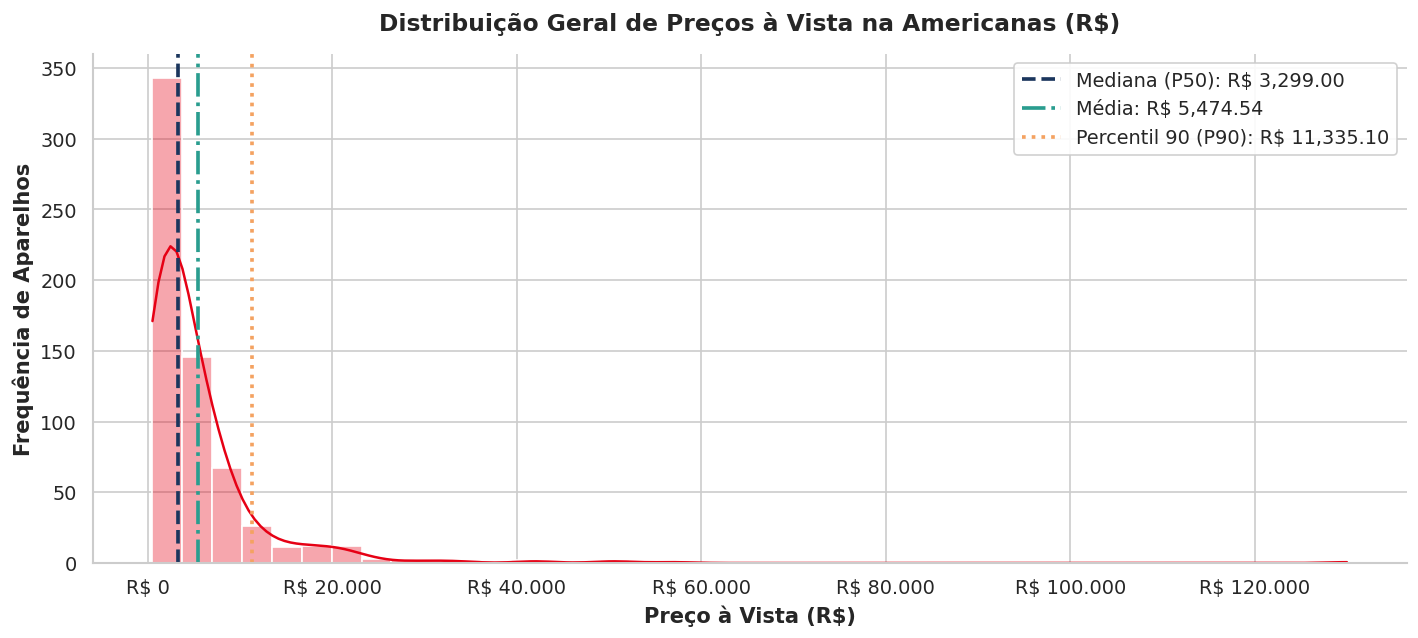

In [30]:
fig, ax = plt.subplots(figsize=(12, 5.5))
sns.histplot(data=df, x='preco_vista', kde=True, bins=40, color='#E60014', alpha=0.35, edgecolor='white', ax=ax)

mediana_geral = df['preco_vista'].median()
media_geral = df['preco_vista'].mean()
p90_geral = df['preco_vista'].quantile(0.90)

ax.axvline(mediana_geral, color='#1B365D', linestyle='--', linewidth=2.2, label=f'Mediana (P50): R$ {mediana_geral:,.2f}')
ax.axvline(media_geral, color='#2A9D8F', linestyle='-.', linewidth=2.2, label=f'Média: R$ {media_geral:,.2f}')
ax.axvline(p90_geral, color='#F4A261', linestyle=':', linewidth=2.2, label=f'Percentil 90 (P90): R$ {p90_geral:,.2f}')

ax.xaxis.set_major_formatter(mtick.FuncFormatter(formatar_reais))
ax.set_title('Distribuição Geral de Preços à Vista na Americanas (R$)', fontsize=14, fontweight='bold', pad=14)
ax.set_xlabel('Preço à Vista (R$)')
ax.set_ylabel('Frequência de Aparelhos')
ax.legend(frameon=True, facecolor='white', framealpha=0.9)
plt.tight_layout()
plt.show()


**Insight de Negócio (Histograma e Densidade):** A distribuição apresenta assimetria positiva (cauda longa à direita), indicando que o volume principal do e-commerce se concentra nas faixas de entrada e intermediária, enquanto os itens acima do P90 representam linhas profissionais ou *premium*.


### 2.3 Diagnóstico Formal de Outliers (Quartis, IQR, Cercas de Tukey e Painel Duplo Linear vs. Escala Log)

### O que este bloco faz:
* **Cálculo Matemático de Outliers (Regra de Tukey):** Computa $Q1$ (25%), Mediana (50%), $Q3$ (75%), o Intervalo Interquartil ($IQR = Q3 - Q1$) e a Cerca Superior ($Q3 + 1,5 \times IQR$), contabilizando quantos produtos são *outliers* em cada categoria.
* **Painel Duplo de Visualização:**
  * **Esquerda (Escala Linear + Stripplot):** Mostra os valores reais em Reais (`R$`), os pontos individuais espalhados (`jitter`) e os *outliers* destacados em losangos vermelhos.
  * **Direita (Escala Logarítmica — `set_xscale('log')`):** Comprime a escala dos extremos para revelar com nitidez a proporção interna dos quartis de todas as categorias sem achatamento visual.


=== Diagnóstico Estatístico de Quartis (IQR) e Outliers por Categoria ===


,Categoria,Qtd_Total,Q1_25% (R$),Mediana (R$),Q3_75% (R$),IQR (R$),Limite_Outlier_Sup (R$),Qtd_Outliers,%_Outliers
0,Ar-Condicionados,181,2639.00,3999.0,6135.00,3496.00,11379.00,14,7.7
1,TVs,178,917.62,1474.0,3209.72,2292.10,6647.87,23,12.9
2,Notebooks,91,3936.38,7199.0,17799.00,13862.62,38592.94,3,3.3
3,Celulares e Smartphones,180,1499.00,2999.0,5915.56,4416.56,12540.39,3,1.7


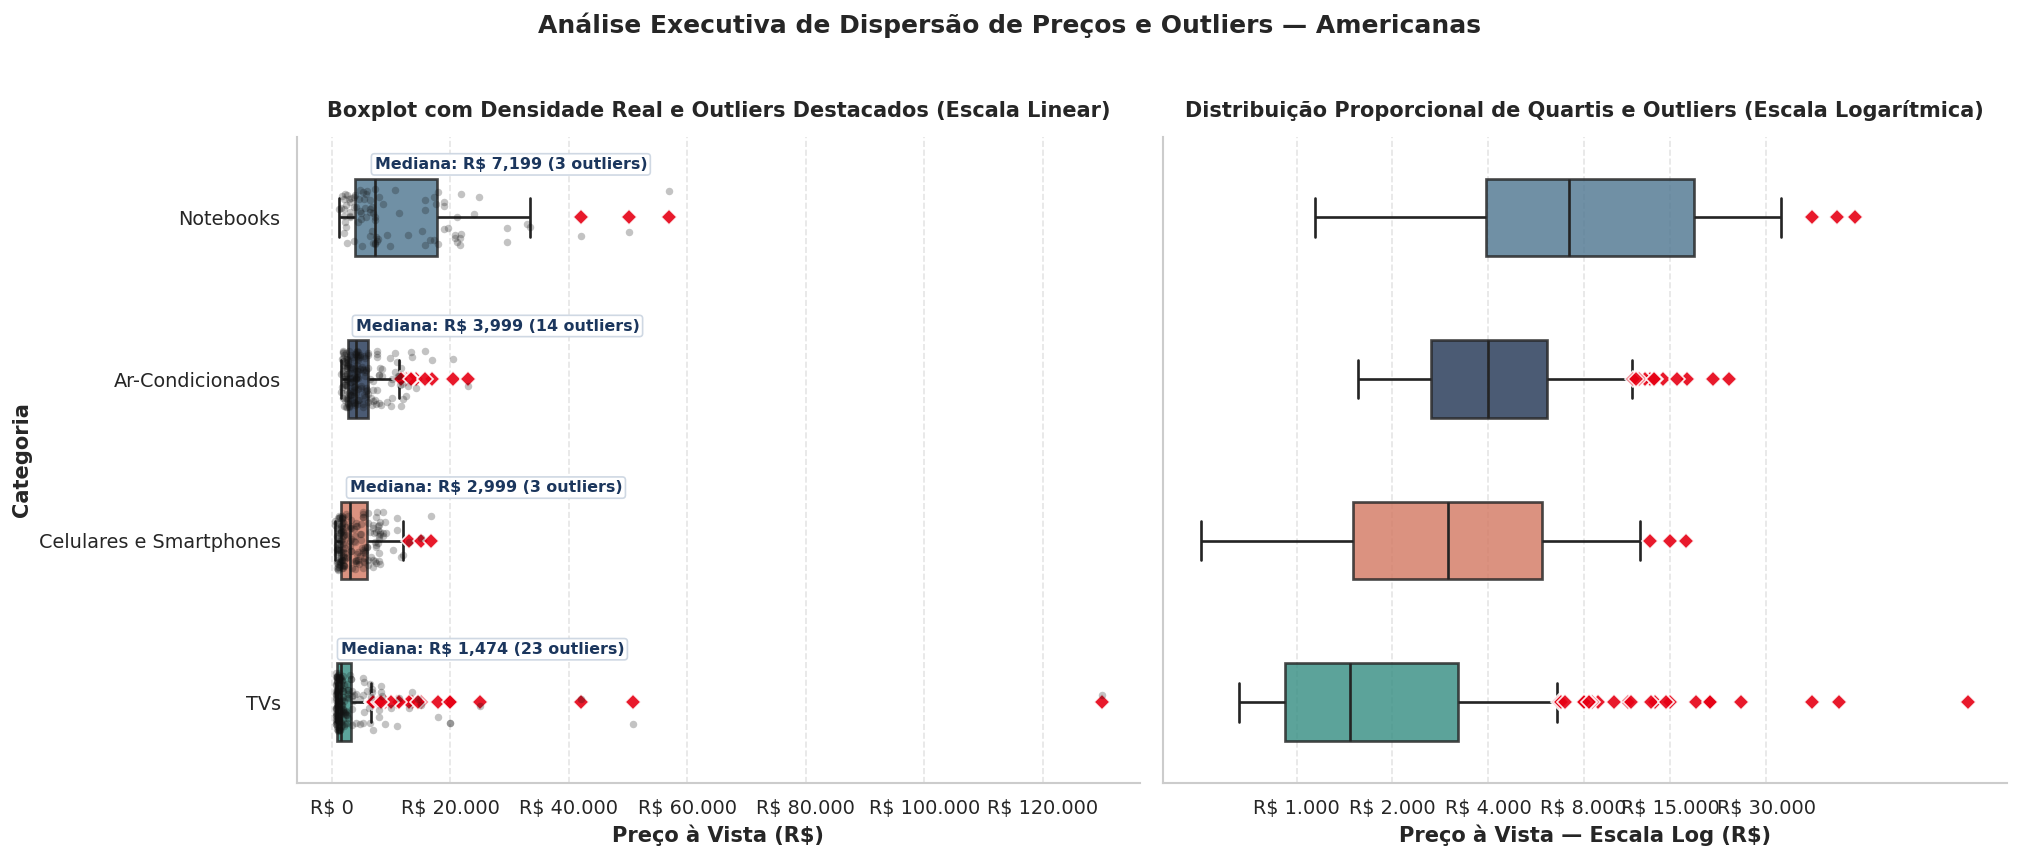

In [31]:
diagnostico_outliers = []
for cat in ['Ar-Condicionados', 'TVs', 'Notebooks', 'Celulares e Smartphones']:
    s = df[df['categoria'] == cat]['preco_vista']
    if s.empty:
        continue
    q1 = s.quantile(0.25)
    med = s.median()
    q3 = s.quantile(0.75)
    iqr = q3 - q1
    lim_sup = q3 + 1.5 * iqr
    qtd_out = int((s > lim_sup).sum())
    perc_out = round((qtd_out / len(s)) * 100, 1)
    diagnostico_outliers.append({
        'Categoria': cat,
        'Qtd_Total': len(s),
        'Q1_25% (R$)': round(q1, 2),
        'Mediana (R$)': round(med, 2),
        'Q3_75% (R$)': round(q3, 2),
        'IQR (R$)': round(iqr, 2),
        'Limite_Outlier_Sup (R$)': round(lim_sup, 2),
        'Qtd_Outliers': qtd_out,
        '%_Outliers': perc_out
    })

df_outliers_resumo = pd.DataFrame(diagnostico_outliers)
print("=== Diagnóstico Estatístico de Quartis (IQR) e Outliers por Categoria ===")
display(df_outliers_resumo)

fig, axes = plt.subplots(1, 2, figsize=(17, 7), sharey=True)
ordem_cats = df.groupby('categoria')['preco_vista'].median().sort_values(ascending=False).index.tolist()
paleta_exec = ['#1B365D', '#2A9D8F', '#457B9D', '#E76F51']
flier_estilo = dict(marker='D', markerfacecolor='#E60014', markeredgecolor='white', markersize=7, alpha=0.9)

sns.boxplot(
    data=df, y='categoria', x='preco_vista', order=ordem_cats,
    palette=paleta_exec, hue='categoria', legend=False,
    width=0.48, linewidth=1.6, flierprops=flier_estilo,
    boxprops=dict(alpha=0.82), ax=axes[0]
)
sns.stripplot(
    data=df, y='categoria', x='preco_vista', order=ordem_cats,
    color='#111111', alpha=0.25, size=4.5, jitter=0.18, ax=axes[0]
)

for idx, cat in enumerate(ordem_cats):
    sub_s = df[df['categoria'] == cat]['preco_vista']
    med_v = sub_s.median()
    q3_v = sub_s.quantile(0.75)
    lim_v = q3_v + 1.5 * (q3_v - sub_s.quantile(0.25))
    qtd_o = int((sub_s > lim_v).sum())
    axes[0].text(
        med_v, idx - 0.30,
        f"Mediana: R$ {med_v:,.0f} ({qtd_o} outliers)",
        color='#1B365D', fontweight='bold', fontsize=9.5,
        bbox=dict(boxstyle='round,pad=0.2', facecolor='white', edgecolor='#CBD5E1', alpha=0.92)
    )

axes[0].xaxis.set_major_formatter(mtick.FuncFormatter(formatar_reais))
axes[0].set_title('Boxplot com Densidade Real e Outliers Destacados (Escala Linear)', fontsize=12.5, fontweight='bold', pad=12)
axes[0].set_xlabel('Preço à Vista (R$)')
axes[0].set_ylabel('Categoria')
axes[0].grid(axis='x', linestyle='--', alpha=0.5)

sns.boxplot(
    data=df, y='categoria', x='preco_vista', order=ordem_cats,
    palette=paleta_exec, hue='categoria', legend=False,
    width=0.48, linewidth=1.6, flierprops=flier_estilo,
    boxprops=dict(alpha=0.82), ax=axes[1]
)
axes[1].set_xscale('log')
axes[1].xaxis.set_major_formatter(mtick.FuncFormatter(formatar_reais))
axes[1].set_xticks([1000, 2000, 4000, 8000, 15000, 30000])
axes[1].set_title('Distribuição Proporcional de Quartis e Outliers (Escala Logarítmica)', fontsize=12.5, fontweight='bold', pad=12)
axes[1].set_xlabel('Preço à Vista — Escala Log (R$)')
axes[1].set_ylabel('')
axes[1].grid(axis='x', linestyle='--', alpha=0.5)

plt.suptitle('Análise Executiva de Dispersão de Preços e Outliers — Americanas', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


**Insight de Negócio (Boxplot e Outliers):** Os *outliers* superiores identificados (losangos vermelhos) correspondem a configurações de topo de linha (notebooks gamer com GPU dedicada, TVs de 65" a 85", splits de alta capacidade). Na gestão comercial, esses itens devem ser precificados separadamente para não distorcer metas de margem dos produtos de giro.


### 2.4 Gráficos Categóricos: Top Lojas (Sellers), Top Marcas e Escada de Preço por Especificação (Painel 2×2)

### O que este bloco faz:
* **Top 10 Lojas (`sellers`):** Identifica quais lojistas concentram o maior número de anúncios na vitrine.
* **Top 15 Marcas:** Mostra a participação das fabricantes mais presentes na base coletada.
* **Painel 2×2 por Especificação Técnica:** Exibe o preço mediano (`R$`) por capacidade técnica em cada categoria (BTUs em Ar-Condicionados, Polegadas em TVs, SSD em Notebooks e Armazenamento GB em Smartphones).


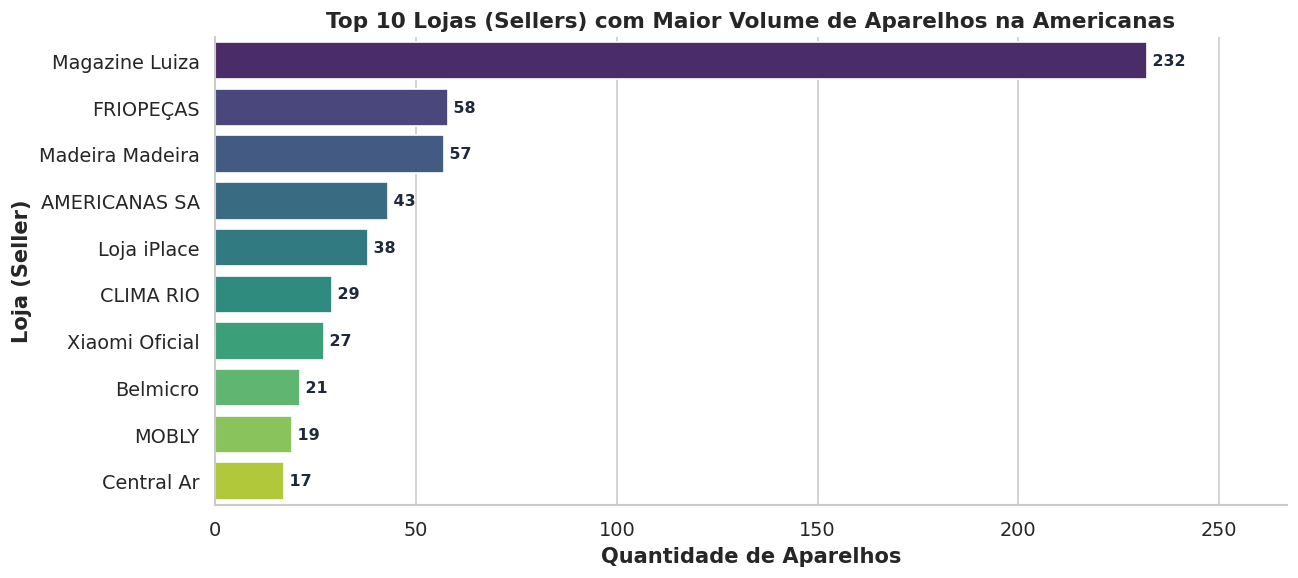

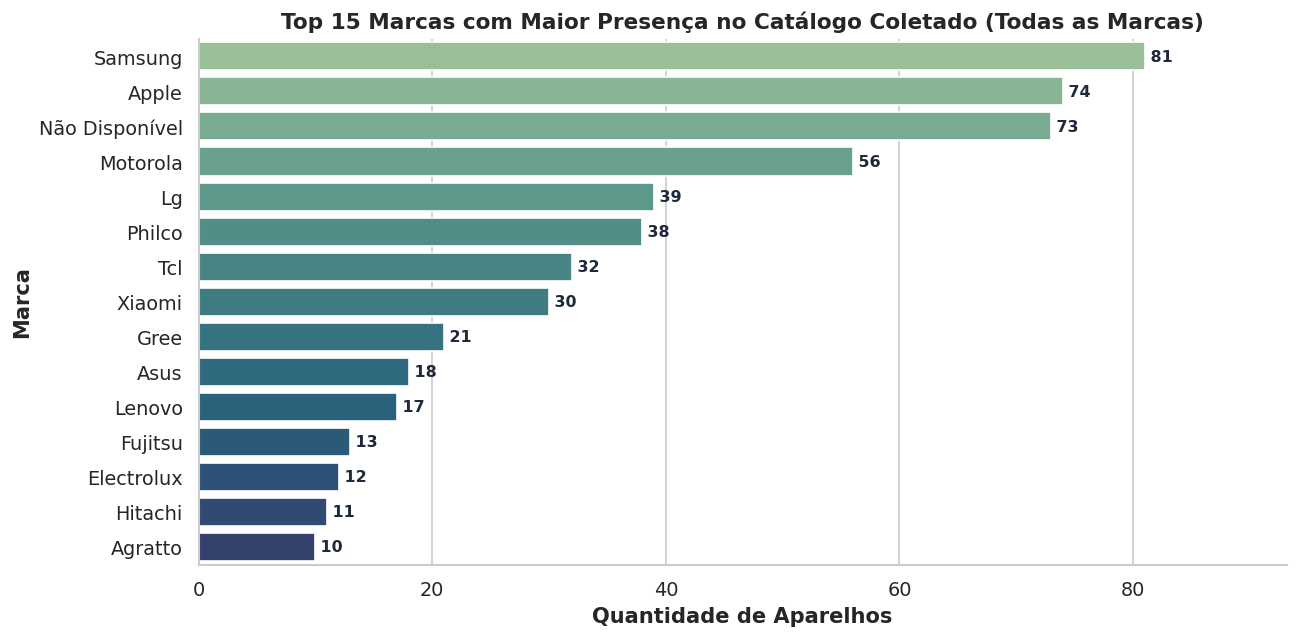

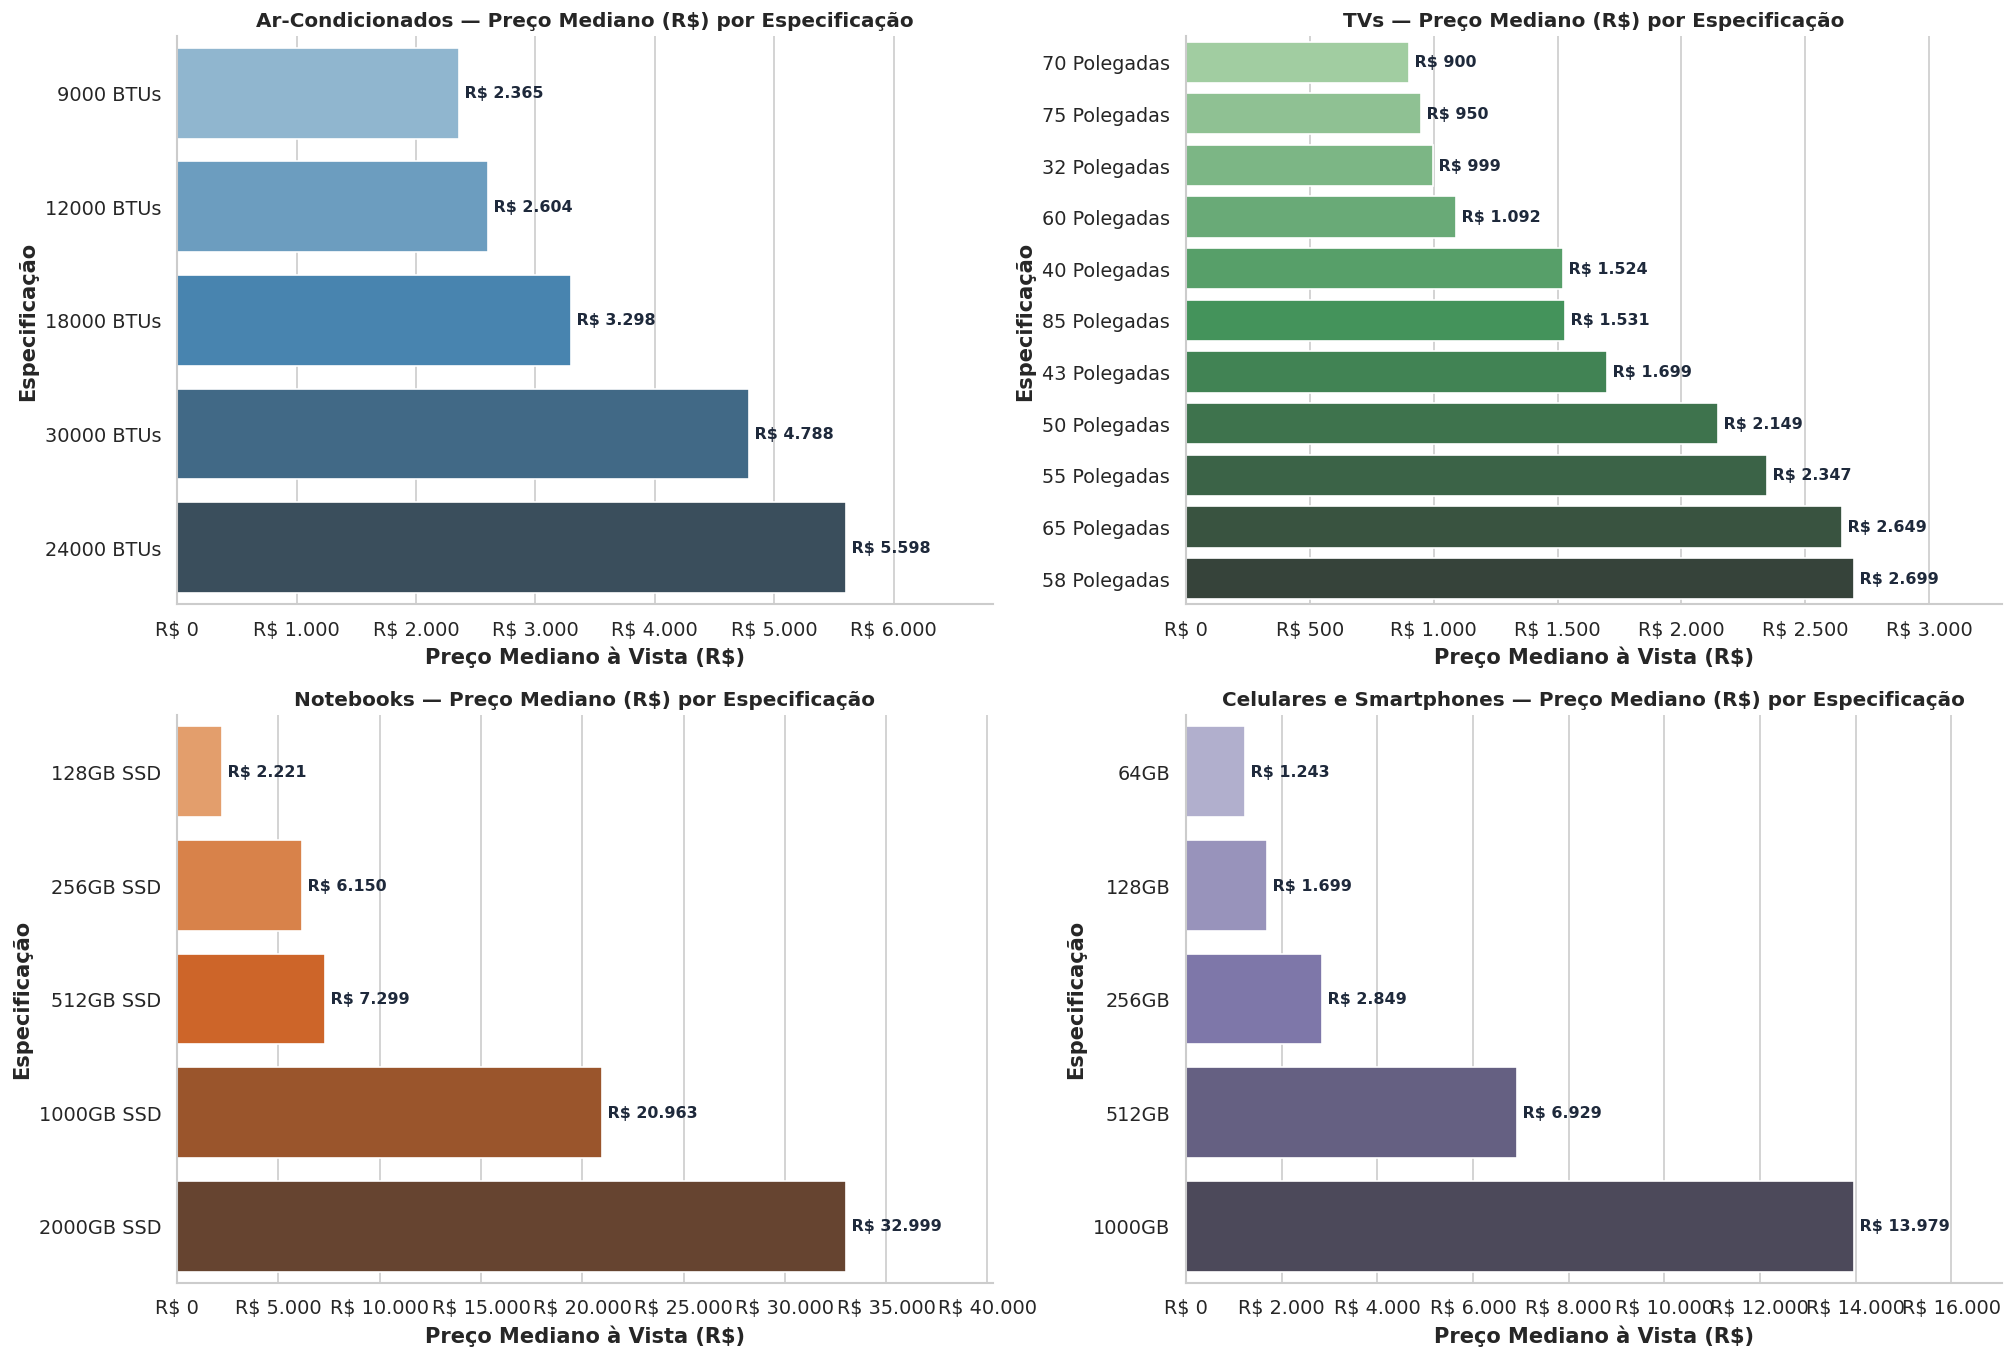

In [32]:
def adicionar_rotulos_barras(ax, formato='int'):
    for p in ax.patches:
        largura = p.get_width()
        if largura > 0:
            txt = f" {int(largura)}" if formato == 'int' else f" R$ {largura:,.0f}".replace(",", ".")
            ax.text(
                largura, p.get_y() + p.get_height() / 2,
                txt, va='center', ha='left', fontsize=9.5, fontweight='bold', color='#1E293B'
            )

top_lojas = df['loja'].value_counts().head(10)
fig, ax = plt.subplots(figsize=(11, 5))
sns.barplot(x=top_lojas.values, y=top_lojas.index, hue=top_lojas.index, palette='viridis', legend=False, ax=ax)
adicionar_rotulos_barras(ax, 'int')
ax.set_xlim(0, top_lojas.values.max() * 1.15)
ax.set_title('Top 10 Lojas (Sellers) com Maior Volume de Aparelhos na Americanas', fontsize=13, fontweight='bold')
ax.set_xlabel('Quantidade de Aparelhos')
ax.set_ylabel('Loja (Seller)')
plt.tight_layout()
plt.show()

top_marcas = df['marca'].value_counts().head(15)
fig, ax = plt.subplots(figsize=(11, 5.5))
sns.barplot(x=top_marcas.values, y=top_marcas.index, hue=top_marcas.index, palette='crest', legend=False, ax=ax)
adicionar_rotulos_barras(ax, 'int')
ax.set_xlim(0, top_marcas.values.max() * 1.15)
ax.set_title('Top 15 Marcas com Maior Presença no Catálogo Coletado (Todas as Marcas)', fontsize=13, fontweight='bold')
ax.set_xlabel('Quantidade de Aparelhos')
ax.set_ylabel('Marca')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(17, 11.5))
axes = axes.flatten()
categorias_ordem = ['Ar-Condicionados', 'TVs', 'Notebooks', 'Celulares e Smartphones']
paletas = ['Blues_d', 'Greens_d', 'Oranges_d', 'Purples_d']

for idx, cat in enumerate(categorias_ordem):
    ax = axes[idx]
    sub = df[(df['categoria'] == cat) & (df['especificacao_tecnica'] != 'Não Especificado')]
    if not sub.empty:
        resumo_spec = sub.groupby('especificacao_tecnica')['preco_vista'].median().sort_values(ascending=True)
        sns.barplot(x=resumo_spec.values, y=resumo_spec.index, hue=resumo_spec.index, palette=paletas[idx], legend=False, ax=ax)
        adicionar_rotulos_barras(ax, 'moeda')
        ax.set_xlim(0, resumo_spec.values.max() * 1.22)
        ax.xaxis.set_major_formatter(mtick.FuncFormatter(formatar_reais))
        ax.set_title(f'{cat} — Preço Mediano (R$) por Especificação', fontsize=12, fontweight='bold')
        ax.set_xlabel('Preço Mediano à Vista (R$)')
        ax.set_ylabel('Especificação')

plt.tight_layout()
plt.show()


**Insights de Negócio (Lojas, Marcas e Especificações):** O painel 2×2 confirma a escada de valor técnico: cada salto de capacidade (ex.: de 9.000 para 18.000 BTUs ou de 43" para 65") desloca diretamente o patamar mediano de preço.


## 3. Pré-processamento, Normalização e Modelagem Preditiva

### Metodologia Aplicada (Prevenção de *Data Leakage* & Escalonamento Robusto)
* **Prevenção de Vazamento de Dados (*Data Leakage*):** Excluímos `preco_total`, `valor_parcela` e `total_parcelado` das variáveis de entrada ($X$) por derivarem diretamente da variável-alvo `preco_vista`.
* **One-Hot Encoding (`pd.get_dummies(..., drop_first=True)`):** Converte variáveis categóricas em colunas binárias evitando multicolinearidade perfeita (armadilha da variável dummy).
* **Divisão Treino/Teste (`train_test_split`, 80/20, `random_state=42`):** Garante reprodutibilidade e avaliação imparcial em dados inéditos.
* **Justificativa do `RobustScaler`:** Como comprovado nos boxplots da Etapa 2, preços de e-commerce possuem *outliers* severos. O `RobustScaler` centraliza pela **Mediana** e escala pelo **IQR**, evitando distorções causadas por extremos, sendo ajustado (`fit_transform`) **estritamente nos dados de treino**.

### 3.1 Regressões Lineares Individuais por Categoria
Treina e avalia uma Regressão Linear dedicada para cada uma das 4 categorias, calculando **MAE**, **RMSE**, **MAPE (%)** e **R²** nos dados de teste.


In [33]:
features_num_cat = ['qtd_parcelas', 'desconto_perc', 'qtd_especificacoes_site']
features_cat_base = [
    'marca', 'modelo', 'especificacao_tecnica', 'memoria_ram',
    'atributo_extra_1', 'atributo_extra_2', 'voltagem', 'tem_juros', 'seller_terceiro'
]

resultados_reg_linear_categorias = []
dados_graficos_cat = {}

for cat in ['Celulares e Smartphones', 'TVs', 'Notebooks', 'Ar-Condicionados']:
    sub = df[df['categoria'] == cat].copy()
    if len(sub) < 10:
        print(f"⚠️ Categoria '{cat}' possui poucos registros ({len(sub)}) para split treino/teste.")
        continue

    top_lojas_cat = sub['loja'].value_counts().head(10).index
    sub['loja_agrupada'] = sub['loja'].where(sub['loja'].isin(top_lojas_cat), 'Outras')
    cols_cat = features_cat_base + ['loja_agrupada']

    X_cat = sub[features_num_cat + cols_cat].copy()
    y_cat = sub['preco_vista'].copy()

    X_cat_enc = pd.get_dummies(X_cat, columns=cols_cat, drop_first=True)
    X_tr, X_te, y_tr, y_te = train_test_split(X_cat_enc, y_cat, test_size=0.20, random_state=42)

    scaler_cat = RobustScaler()
    X_tr[features_num_cat] = scaler_cat.fit_transform(X_tr[features_num_cat])
    X_te[features_num_cat] = scaler_cat.transform(X_te[features_num_cat])

    lr_cat = LinearRegression()
    lr_cat.fit(X_tr, y_tr)
    y_pred_cat = np.maximum(lr_cat.predict(X_te), 0)

    mae_c = mean_absolute_error(y_te, y_pred_cat)
    rmse_c = np.sqrt(mean_squared_error(y_te, y_pred_cat))
    mape_c = mean_absolute_percentage_error(y_te, y_pred_cat) * 100
    r2_c = r2_score(y_te, y_pred_cat)

    resultados_reg_linear_categorias.append({
        'Categoria': cat,
        'Amostras_Total': len(sub),
        'Amostras_Teste': len(y_te),
        'MAE (R$)': round(mae_c, 2),
        'RMSE (R$)': round(rmse_c, 2),
        'MAPE (%)': round(mape_c, 2),
        'R²': round(r2_c, 4),
        'Preco_Medio_Real (R$)': round(y_te.mean(), 2)
    })
    dados_graficos_cat[cat] = (y_te, y_pred_cat, mae_c, rmse_c, mape_c, r2_c)

df_resumo_lr_cats = pd.DataFrame(resultados_reg_linear_categorias)
print("=== Performance das Regressões Lineares por Categoria (Dados de Teste) ===")
display(df_resumo_lr_cats)

for row in resultados_reg_linear_categorias:
    print(
        f"• {row['Categoria']}: MAE = R$ {row['MAE (R$)']:,.2f} | RMSE = R$ {row['RMSE (R$)']:,.2f} "
        f"| MAPE = {row['MAPE (%)']:.2f}% | R² = {row['R²']:.4f}."
    )


=== Performance das Regressões Lineares por Categoria (Dados de Teste) ===


,Categoria,Amostras_Total,Amostras_Teste,MAE (R$),RMSE (R$),MAPE (%),R²,Preco_Medio_Real (R$)
0,Celulares e Smartphones,180,36,724.87,1139.73,26.93,0.8481,3826.37
1,TVs,178,36,4764.65,19226.64,43.04,0.2634,6755.71
2,Notebooks,91,19,7668.28,11305.40,113.24,0.2828,11985.00
3,Ar-Condicionados,181,37,2502.27,4014.70,45.33,0.1824,5665.78


• Celulares e Smartphones: MAE = R$ 724.87 | RMSE = R$ 1,139.73 | MAPE = 26.93% | R² = 0.8481.
• TVs: MAE = R$ 4,764.65 | RMSE = R$ 19,226.64 | MAPE = 43.04% | R² = 0.2634.
• Notebooks: MAE = R$ 7,668.28 | RMSE = R$ 11,305.40 | MAPE = 113.24% | R² = 0.2828.
• Ar-Condicionados: MAE = R$ 2,502.27 | RMSE = R$ 4,014.70 | MAPE = 45.33% | R² = 0.1824.


### 3.2 Painel 2×2 — Diagnóstico Visual das Regressões Lineares por Categoria (Real vs. Previsto)

### O que este bloco faz:
Plota o gráfico de dispersão entre o **Preço Real Anunciado** (eixo X) e o **Preço Previsto pelo Modelo** (eixo Y) para cada uma das 4 categorias, comparado à linha diagonal vermelha tracejada ($y = x$) que representa a previsão perfeita.


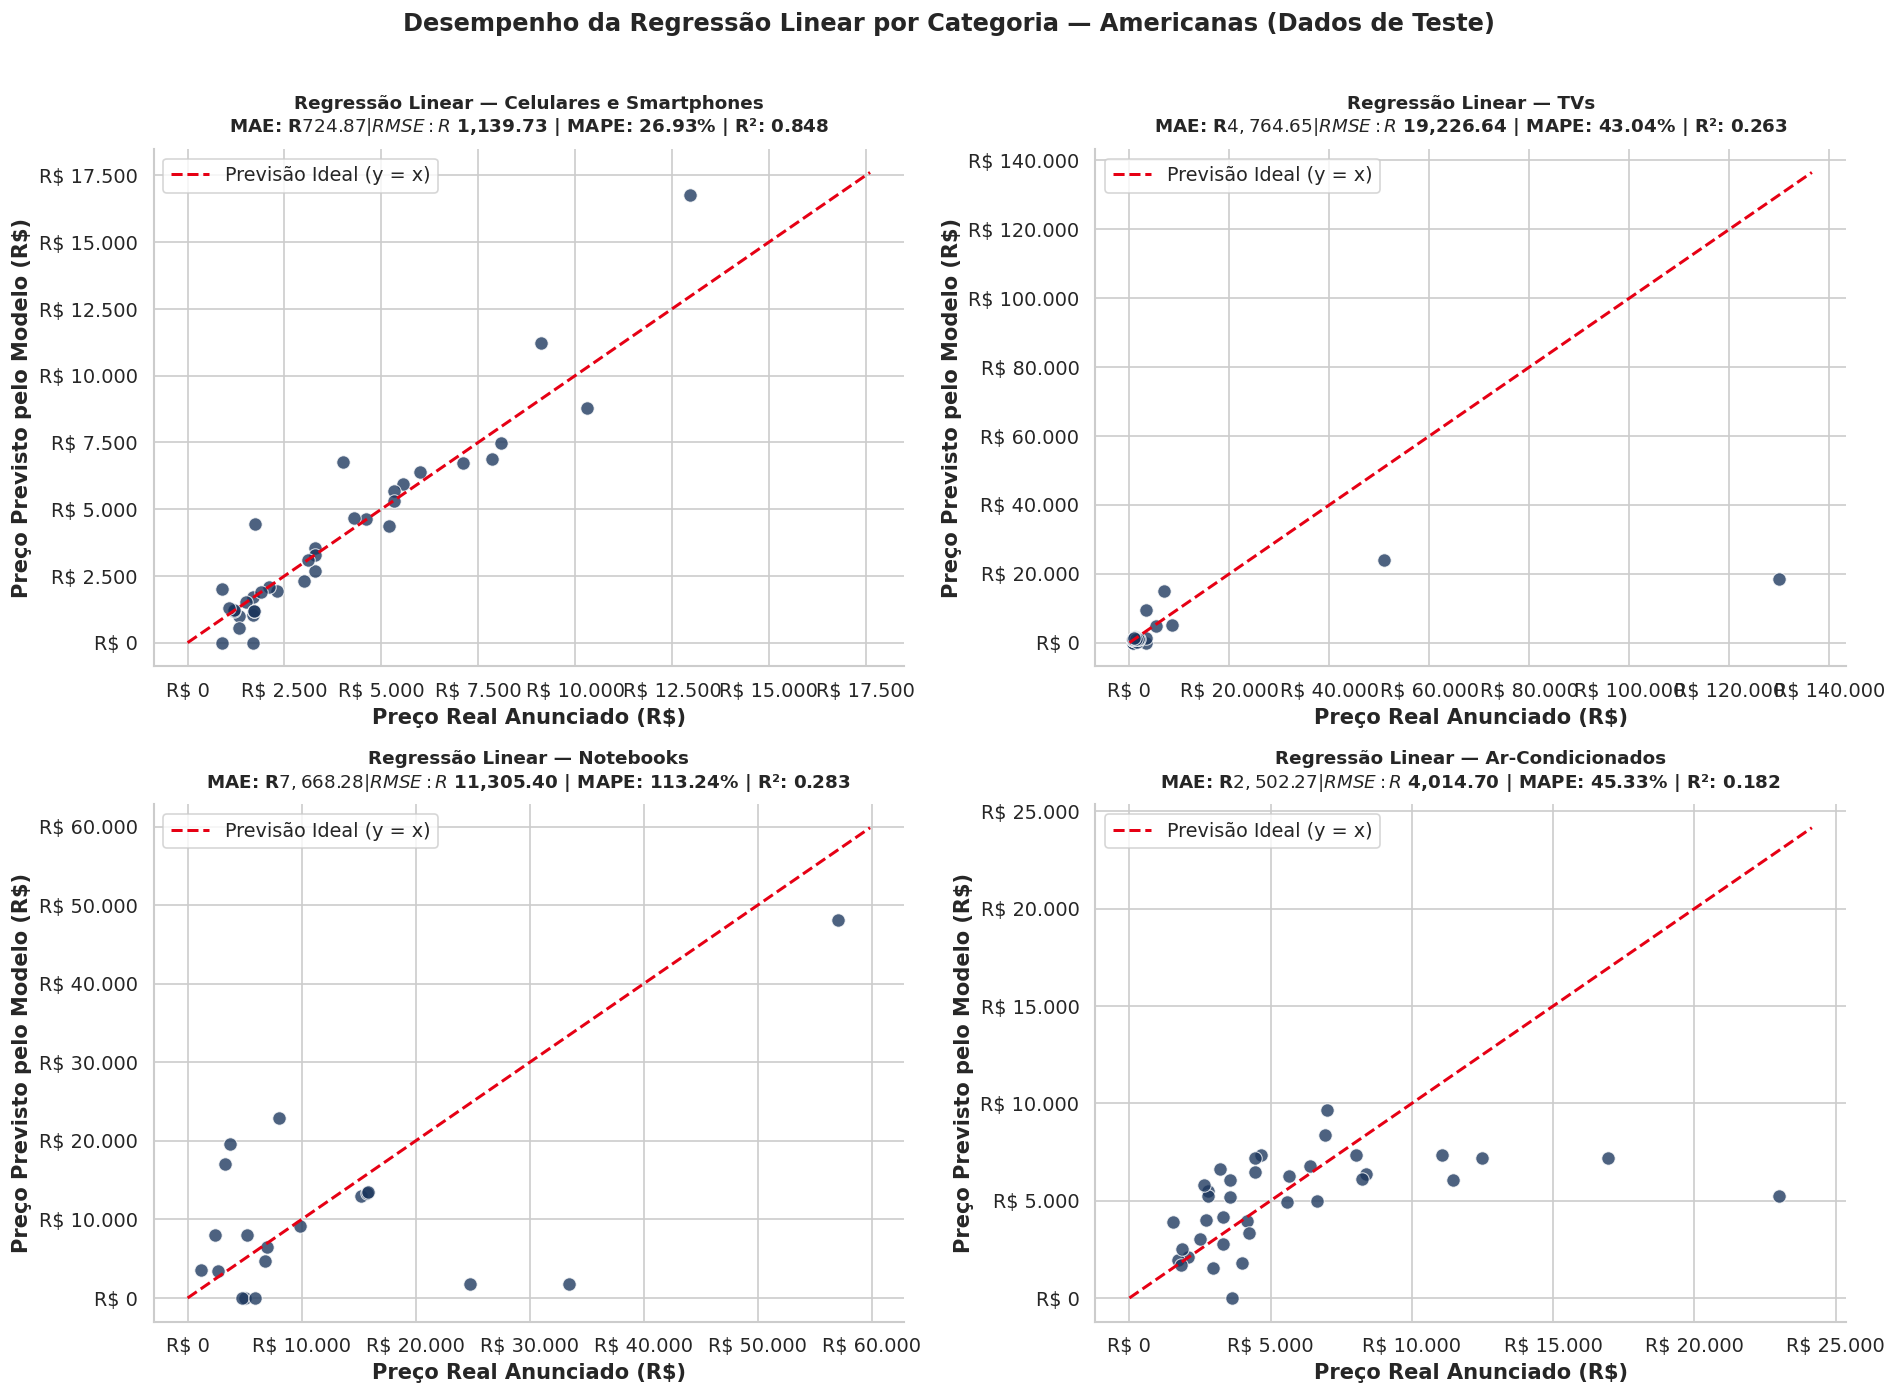

In [34]:
fig, axes = plt.subplots(2, 2, figsize=(16, 11.5))
axes = axes.flatten()

for idx, (cat, (y_te, y_pr, mae_c, rmse_c, mape_c, r2_c)) in enumerate(dados_graficos_cat.items()):
    ax = axes[idx]
    sns.scatterplot(x=y_te, y=y_pr, alpha=0.78, s=65, color='#1B365D', edgecolor='white', ax=ax)
    lim_max = max(y_te.max(), y_pr.max()) * 1.05
    ax.plot([0, lim_max], [0, lim_max], color='#E60014', linestyle='--', linewidth=1.8, label='Previsão Ideal (y = x)')
    ax.xaxis.set_major_formatter(mtick.FuncFormatter(formatar_reais))
    ax.yaxis.set_major_formatter(mtick.FuncFormatter(formatar_reais))
    ax.set_title(
        f'Regressão Linear — {cat}\nMAE: R$ {mae_c:,.2f} | RMSE: R$ {rmse_c:,.2f} | MAPE: {mape_c:.2f}% | R²: {r2_c:.3f}',
        fontsize=11, fontweight='bold', pad=10
    )
    ax.set_xlabel('Preço Real Anunciado (R$)')
    ax.set_ylabel('Preço Previsto pelo Modelo (R$)')
    ax.legend(loc='upper left', frameon=True, facecolor='white')

plt.suptitle('Desempenho da Regressão Linear por Categoria — Americanas (Dados de Teste)', fontsize=14.5, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()


### 3.3 Laço Automatizado dos 5 Algoritmos + 4 Métricas + 4 Gráficos por Modelo

### O que este bloco faz:
Executa uma estrutura de repetição (`for`) percorrendo os **5 algoritmos obrigatórios**:
1. **Regressão Linear (`LinearRegression`)**
2. **Árvore de Decisão (`DecisionTreeRegressor`)**
3. **K-Nearest Neighbors (`KNeighborsRegressor`)**
4. **Random Forest (`RandomForestRegressor`)**
5. **Gradient Boosting (`GradientBoostingRegressor`)**

Para **cada algoritmo**, o código treina em `(X_train, y_train)`, prediz sobre `X_test`, imprime as **4 métricas de negócio** (**MAE**, **RMSE**, **MAPE** e **R²**) e exibe um **painel 2×2 com os 4 gráficos diagnósticos**:
1. **Dispersão do R²** (Real vs. Previsto);
2. **Barras do MAE** (Erro Médio Absoluto em R$ por Categoria e Global);
3. **Histograma do MAPE (%)** (Distribuição do erro percentual absoluto);
4. **Dispersão do RMSE** (Magnitude do erro individual por faixa de preço).

Ao final, exibe a tabela comparativa ordenada pelo melhor **R²** e o gráfico de **Importância das Features (*Feature Importance*)**.


🚀 EXECUTANDO ALGORITMO: REGRESSÃO LINEAR
📊 Métricas de Negócio (Regressão Linear):
   • MAE  (Erro Médio Absoluto):            R$ 3,868.73
   • RMSE (Raiz do Erro Quadrático Médio):  R$ 11,940.44
   • MAPE (Erro Percentual Médio Absoluto): 89.73%
   • R²   (Coeficiente de Determinação):    0.1256 (12.56% de variância explicada)


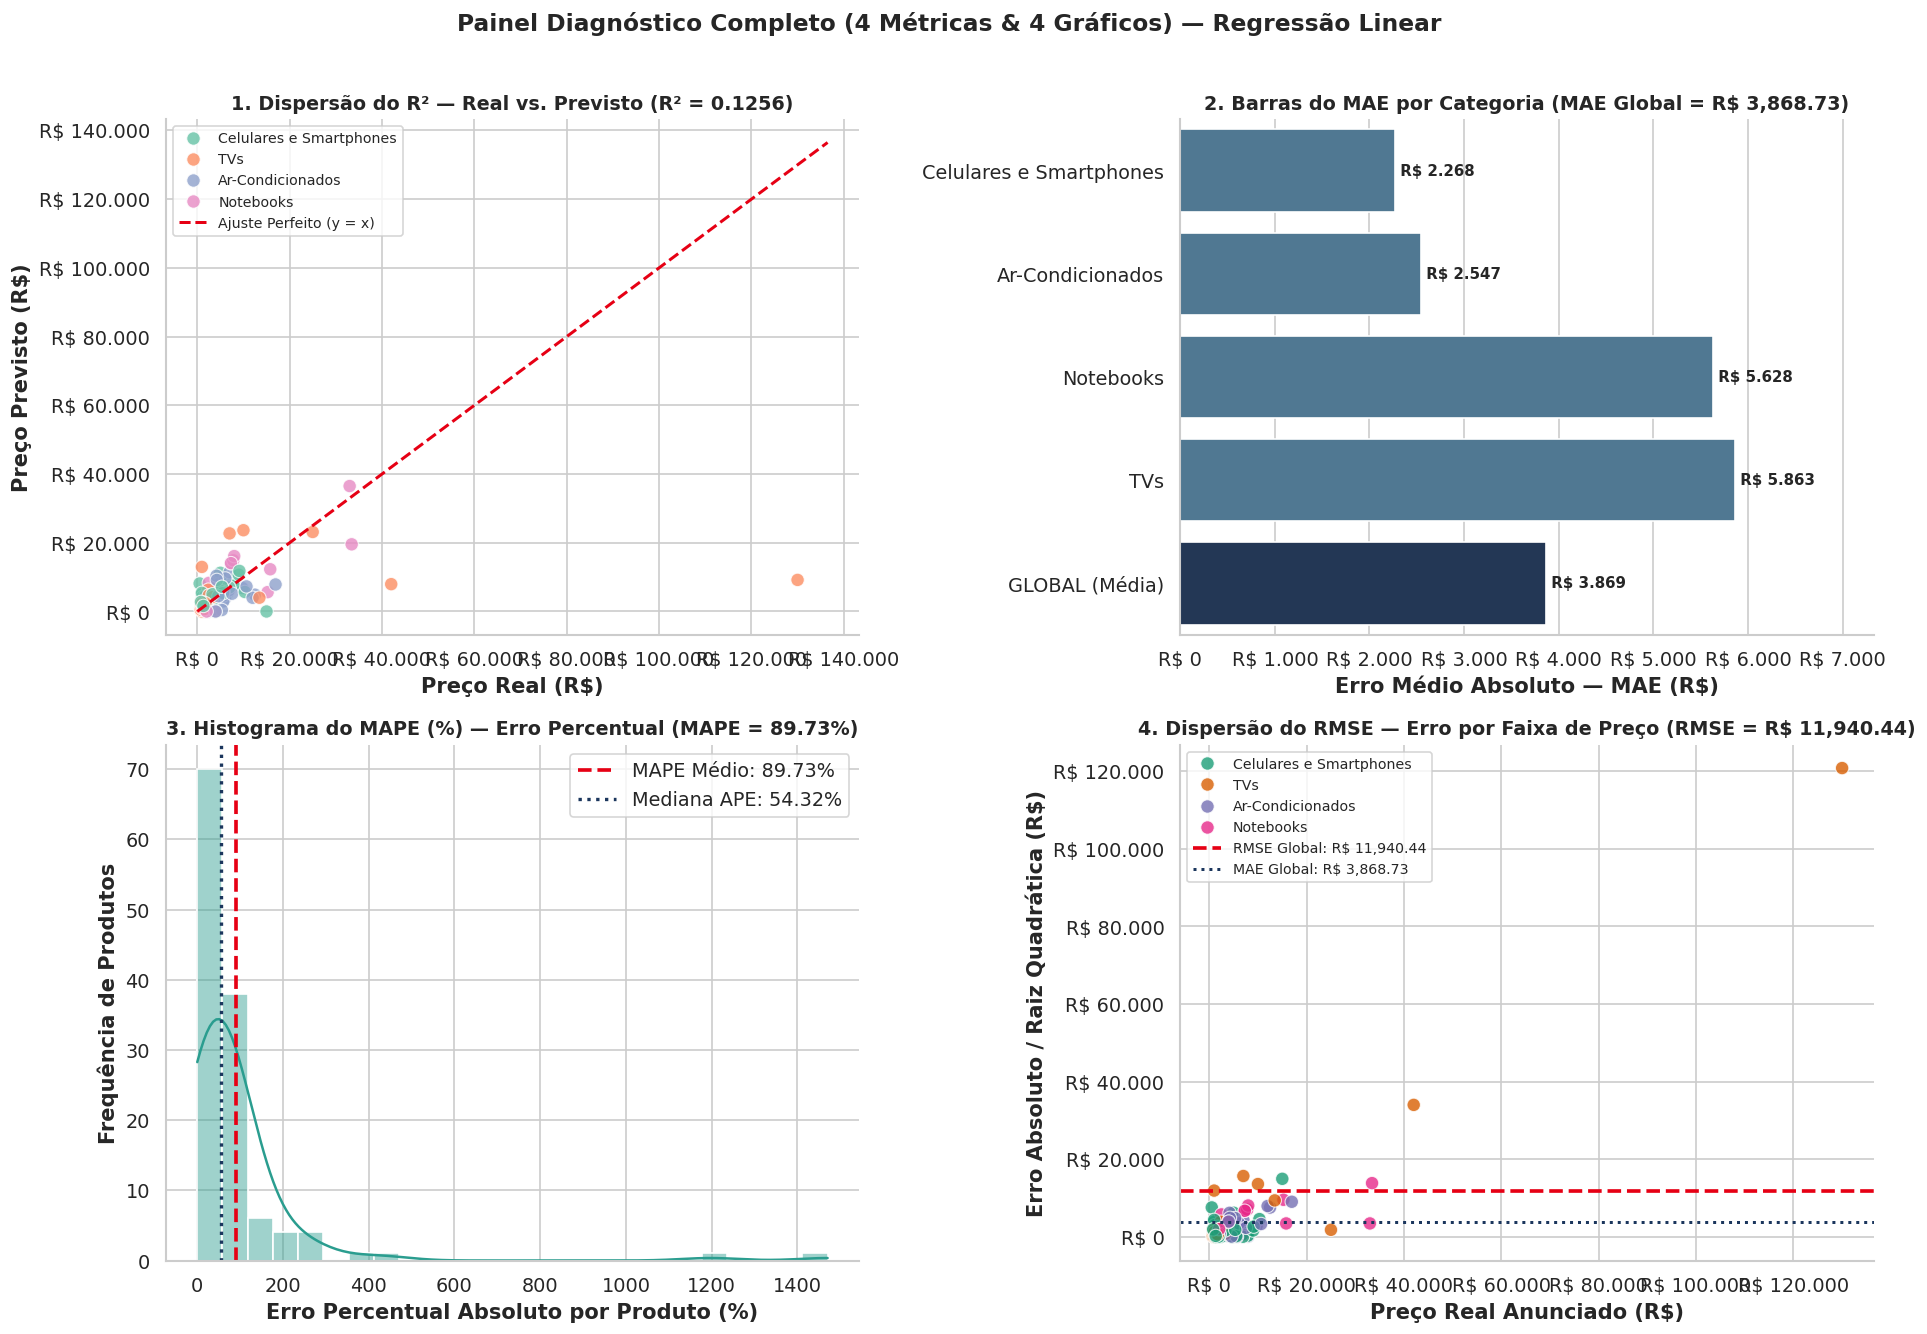

🚀 EXECUTANDO ALGORITMO: ÁRVORE DE DECISÃO
📊 Métricas de Negócio (Árvore de Decisão):
   • MAE  (Erro Médio Absoluto):            R$ 2,801.35
   • RMSE (Raiz do Erro Quadrático Médio):  R$ 11,848.30
   • MAPE (Erro Percentual Médio Absoluto): 43.34%
   • R²   (Coeficiente de Determinação):    0.1391 (13.91% de variância explicada)


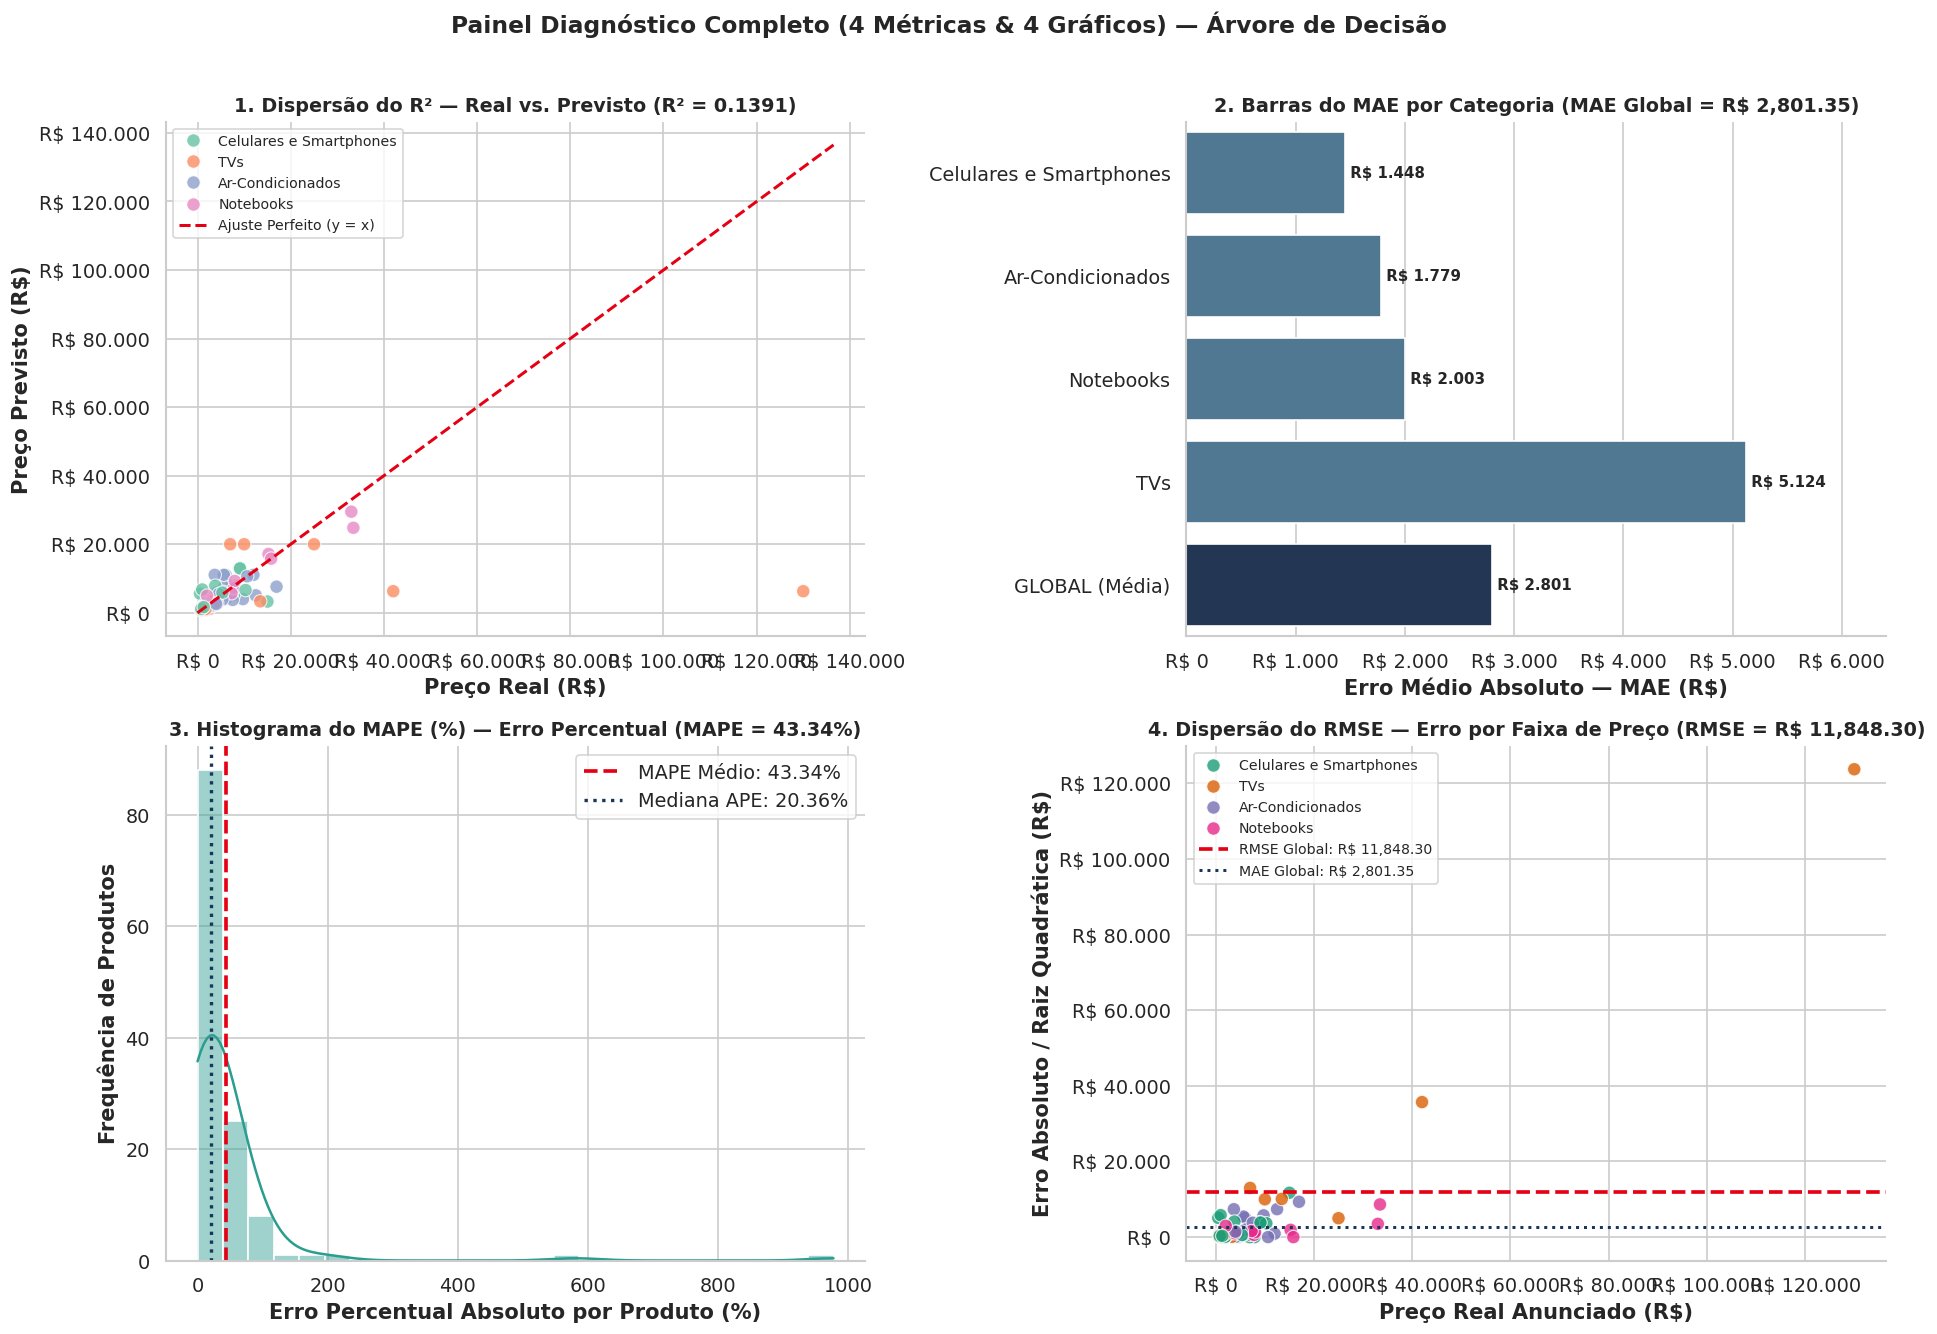

🚀 EXECUTANDO ALGORITMO: KNEIGHBORSREGRESSOR
📊 Métricas de Negócio (KNeighborsRegressor):
   • MAE  (Erro Médio Absoluto):            R$ 2,820.93
   • RMSE (Raiz do Erro Quadrático Médio):  R$ 12,001.38
   • MAPE (Erro Percentual Médio Absoluto): 41.99%
   • R²   (Coeficiente de Determinação):    0.1167 (11.67% de variância explicada)


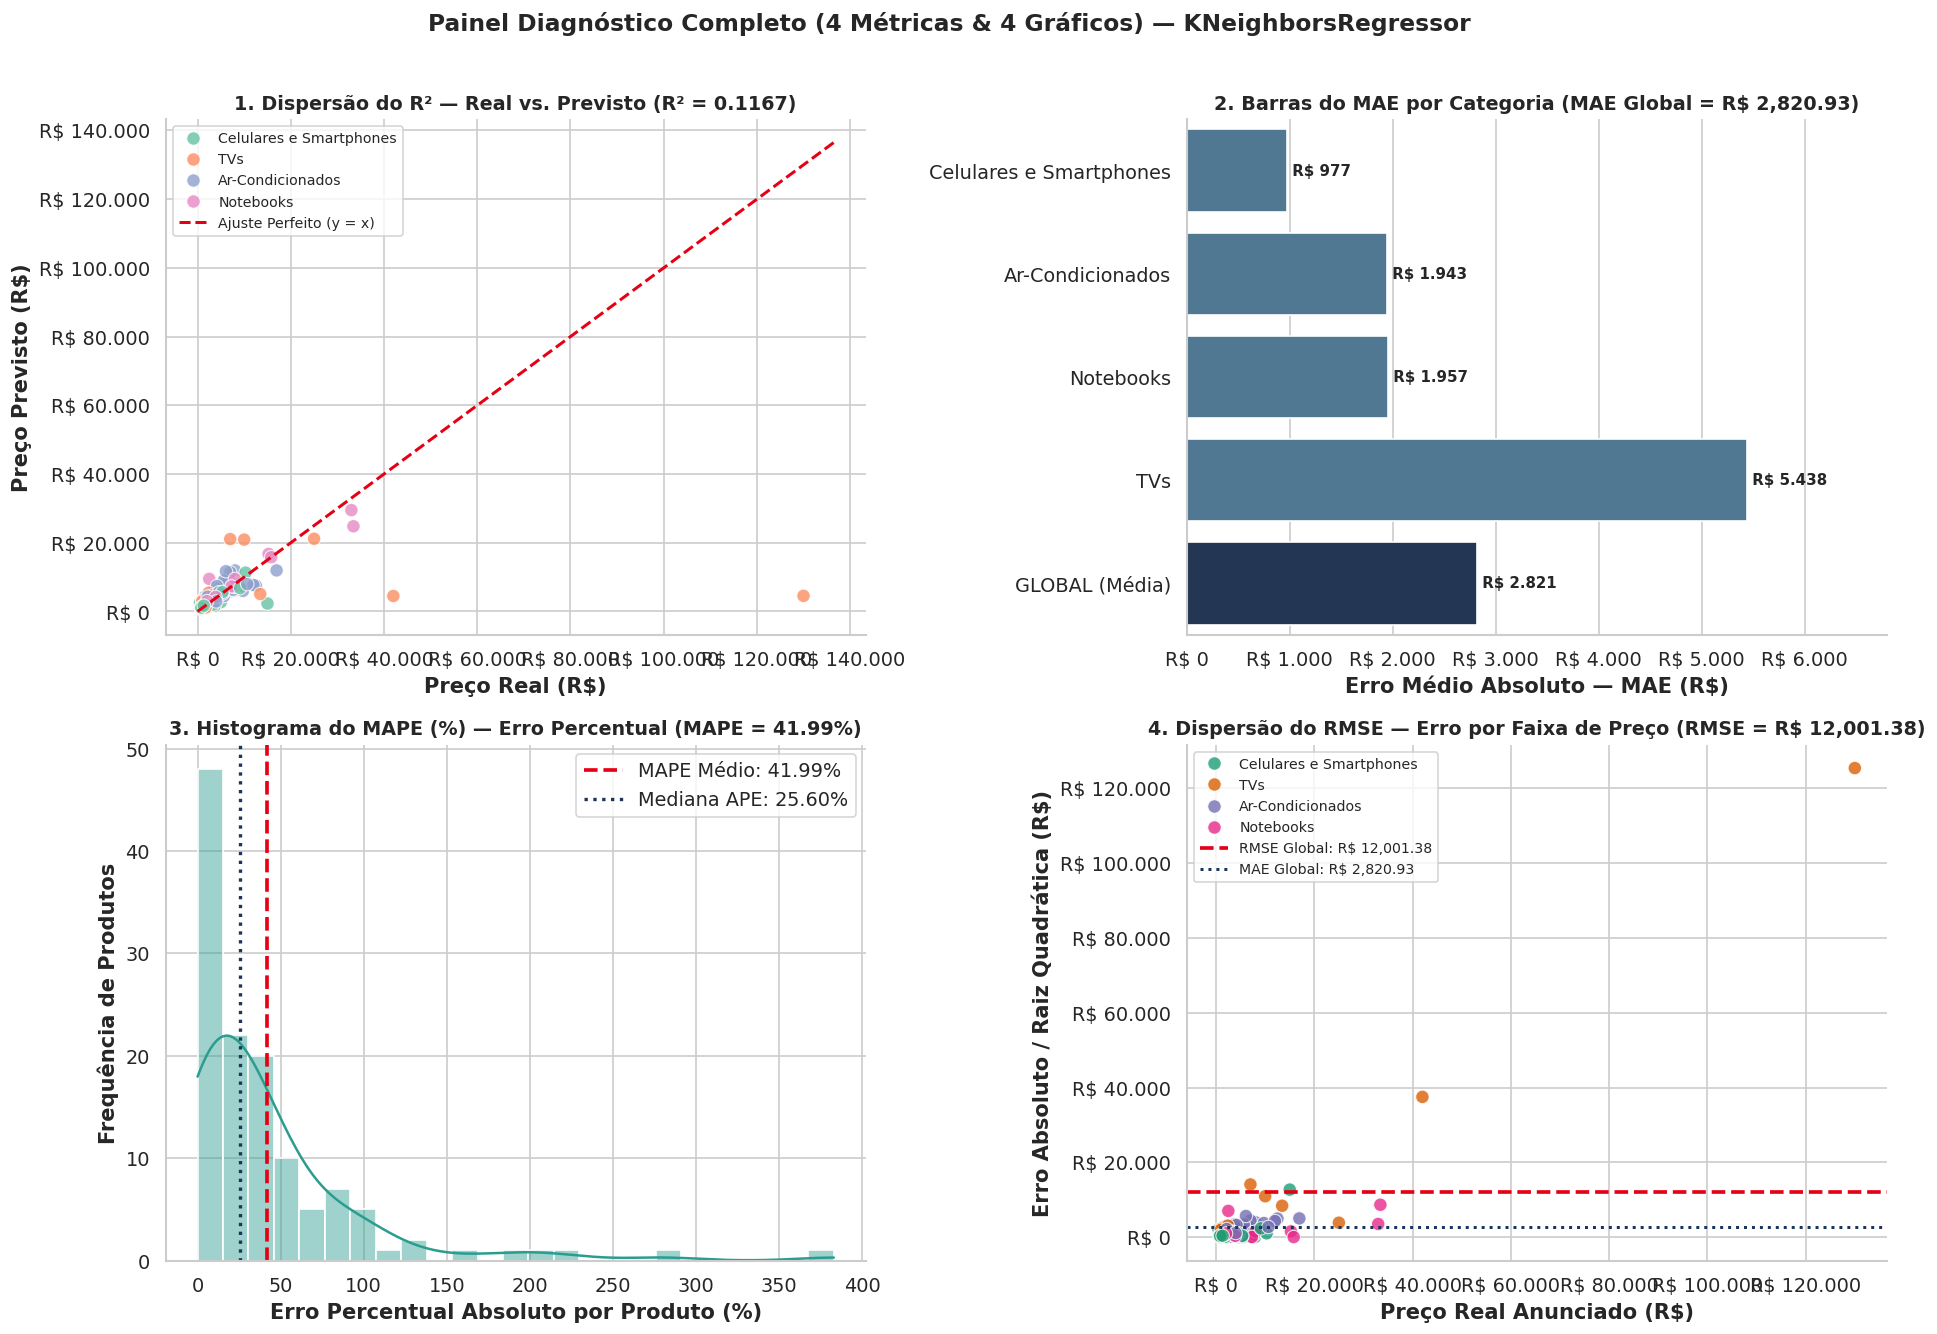

🚀 EXECUTANDO ALGORITMO: RANDOMFORESTREGRESSOR
📊 Métricas de Negócio (RandomForestRegressor):
   • MAE  (Erro Médio Absoluto):            R$ 2,608.43
   • RMSE (Raiz do Erro Quadrático Médio):  R$ 11,871.32
   • MAPE (Erro Percentual Médio Absoluto): 48.28%
   • R²   (Coeficiente de Determinação):    0.1357 (13.57% de variância explicada)


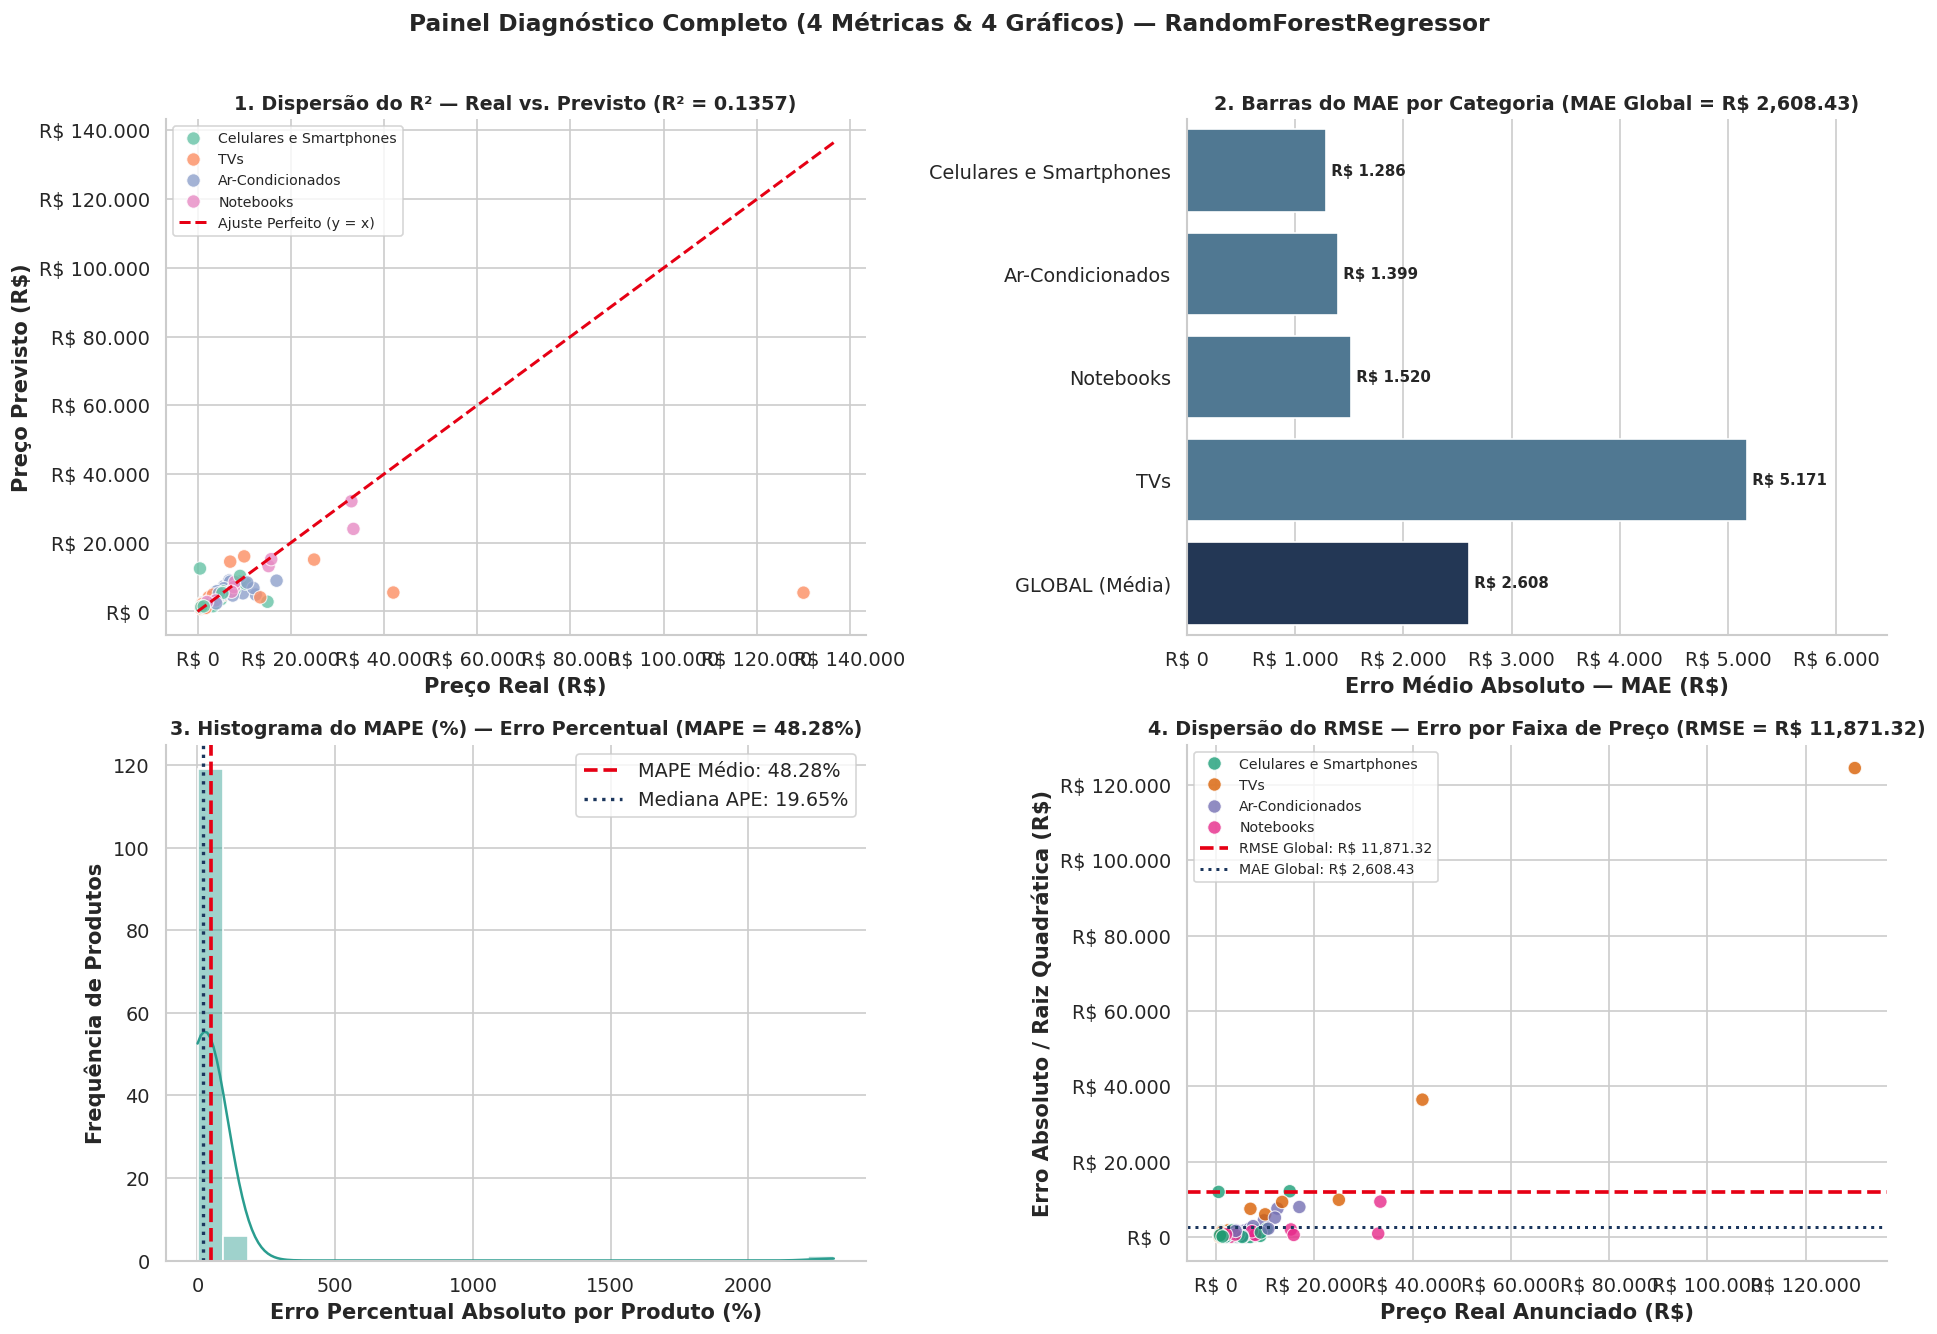

🚀 EXECUTANDO ALGORITMO: GRADIENTBOOSTINGREGRESSOR
📊 Métricas de Negócio (GradientBoostingRegressor):
   • MAE  (Erro Médio Absoluto):            R$ 2,977.37
   • RMSE (Raiz do Erro Quadrático Médio):  R$ 12,011.17
   • MAPE (Erro Percentual Médio Absoluto): 63.73%
   • R²   (Coeficiente de Determinação):    0.1152 (11.52% de variância explicada)


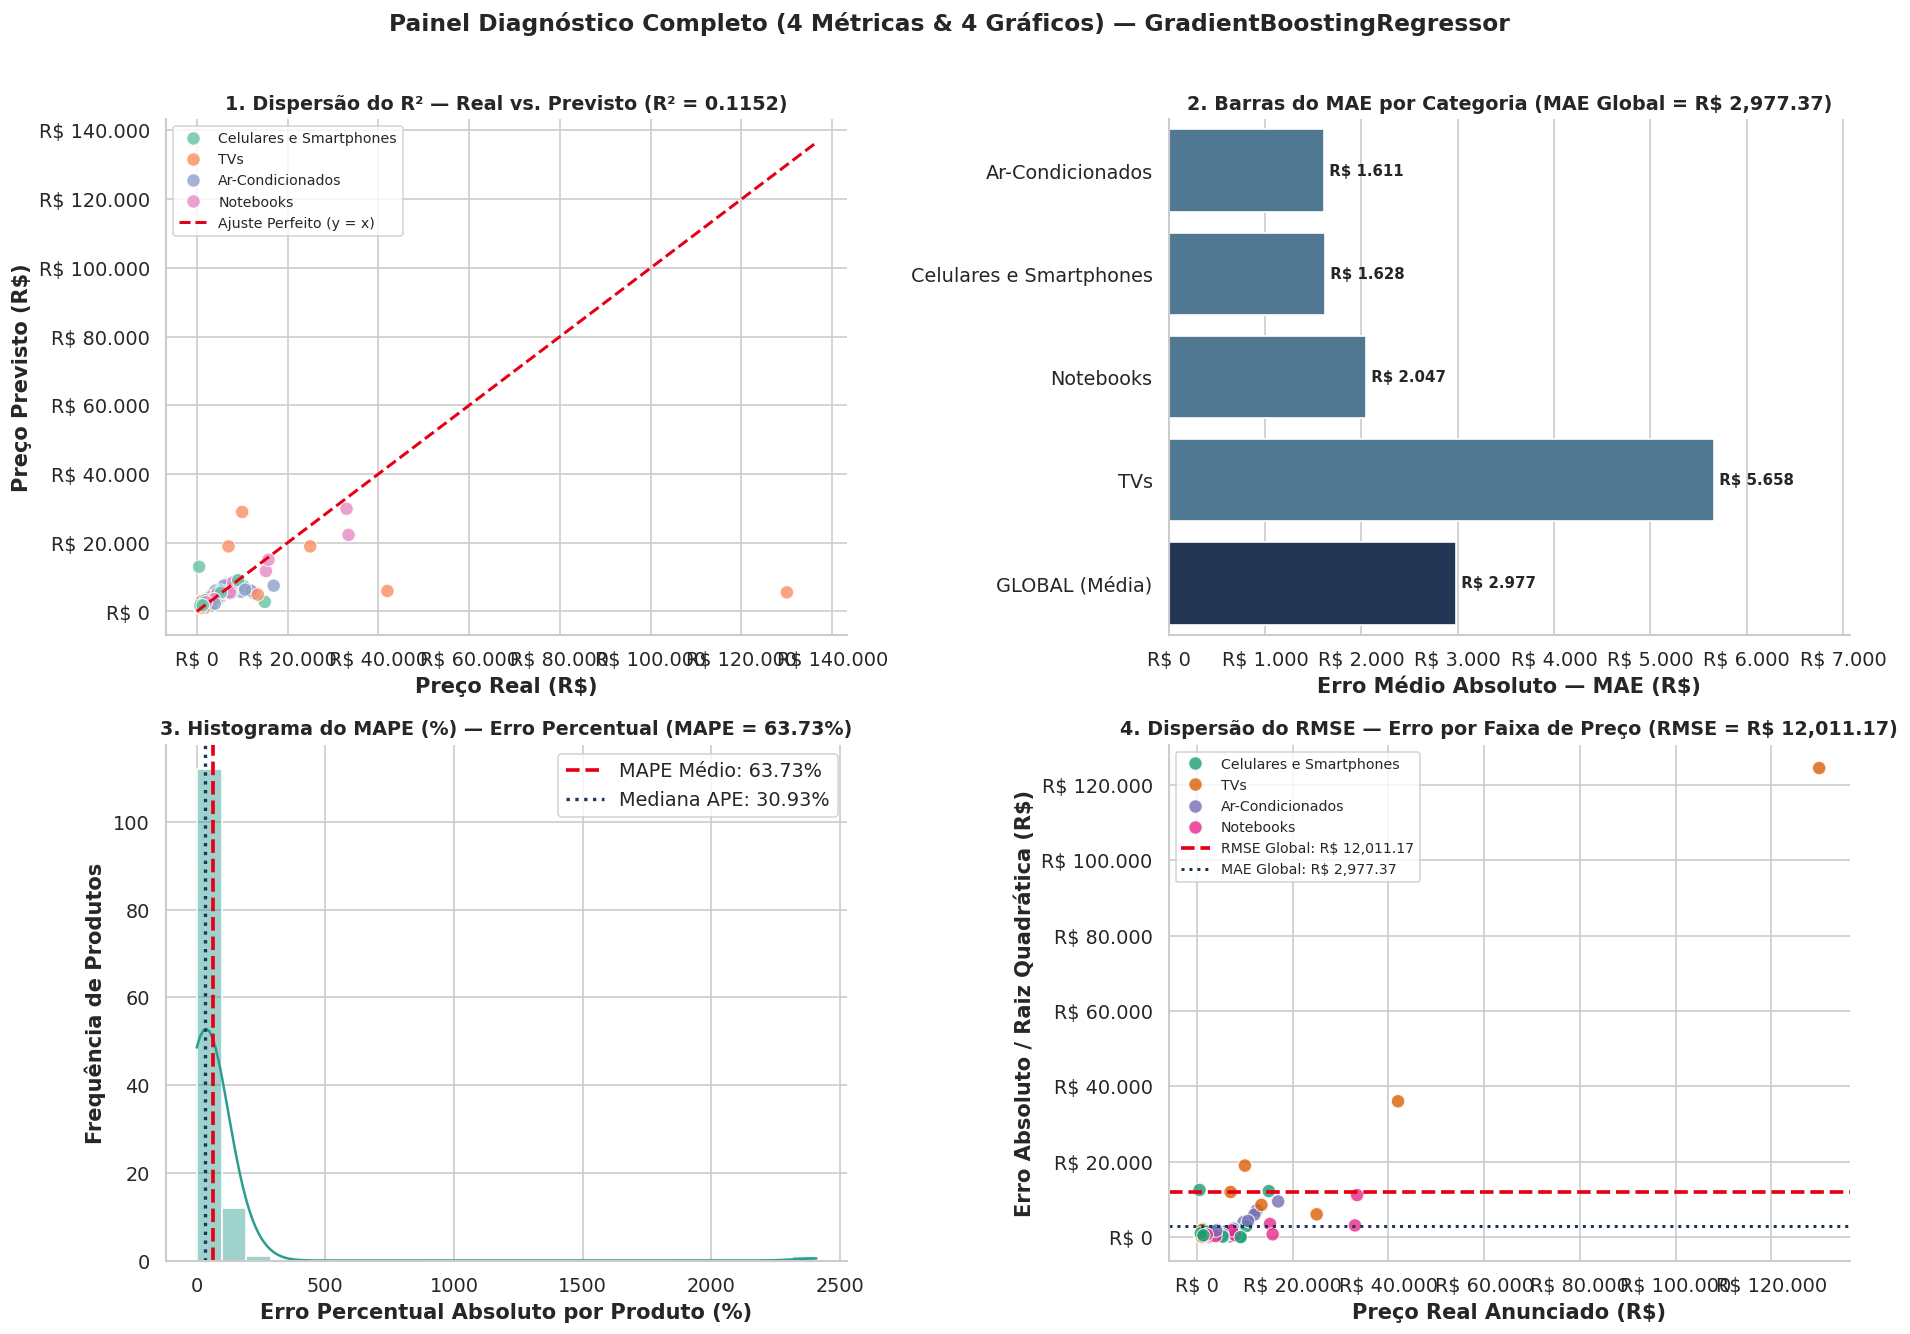


=== TABELA COMPARATIVA FINAL DOS 5 ALGORITMOS (ORDENADA POR R²) ===


,Modelo,MAE (R$),RMSE (R$),MAPE (%),R²
0,Árvore de Decisão,2801.35,11848.30,43.34,0.1391
1,RandomForestRegressor,2608.43,11871.32,48.28,0.1357
2,Regressão Linear,3868.73,11940.44,89.73,0.1256
3,KNeighborsRegressor,2820.93,12001.38,41.99,0.1167
4,GradientBoostingRegressor,2977.37,12011.17,63.73,0.1152


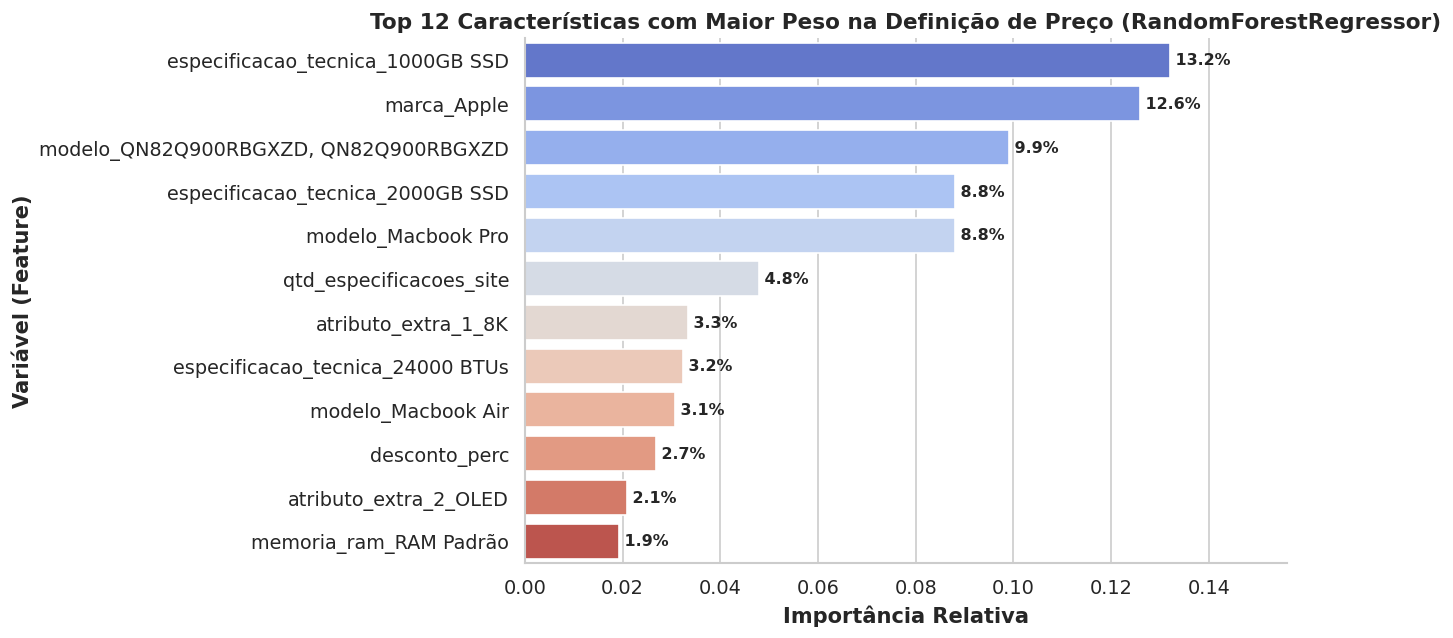

In [35]:
top_15_lojas = df['loja'].value_counts().head(15).index
df['loja_agrupada'] = df['loja'].where(df['loja'].isin(top_15_lojas), 'Outras')

features_num_geral = ['qtd_parcelas', 'desconto_perc', 'qtd_especificacoes_site']
features_cat_geral = [
    'categoria', 'marca', 'modelo', 'especificacao_tecnica', 'memoria_ram',
    'atributo_extra_1', 'atributo_extra_2', 'voltagem', 'tem_juros', 'seller_terceiro', 'loja_agrupada'
]

X_geral = df[features_num_geral + features_cat_geral].copy()
y_geral = df['preco_vista'].copy()
X_geral_enc = pd.get_dummies(X_geral, columns=features_cat_geral, drop_first=True)

X_train, X_test, y_train, y_test = train_test_split(
    X_geral_enc, y_geral, test_size=0.20, random_state=42
)
categorias_teste = df.loc[y_test.index, 'categoria'].values
marcas_teste = df.loc[y_test.index, 'marca'].values
modelos_prod_teste = df.loc[y_test.index, 'modelo'].values

scaler_geral = RobustScaler()
X_train[features_num_geral] = scaler_geral.fit_transform(X_train[features_num_geral])
X_test[features_num_geral] = scaler_geral.transform(X_test[features_num_geral])

lista_modelos = [
    ("Regressão Linear", LinearRegression()),
    ("Árvore de Decisão", DecisionTreeRegressor(random_state=42)),
    ("KNeighborsRegressor", KNeighborsRegressor(n_neighbors=5, weights="distance", n_jobs=-1)),
    ("RandomForestRegressor", RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1)),
    ("GradientBoostingRegressor", GradientBoostingRegressor(n_estimators=200, learning_rate=0.08, random_state=42))
]

res_gerais = []
modelos_treinados_dict = {}
detalhes_5_modelos_bi = {}

for nome_modelo, modelo in lista_modelos:
    print("=" * 95)
    print(f"🚀 EXECUTANDO ALGORITMO: {nome_modelo.upper()}")
    print("=" * 95)

    modelo.fit(X_train, y_train)
    modelos_treinados_dict[nome_modelo] = modelo
    y_pred = np.maximum(modelo.predict(X_test), 0)

    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    mape = mean_absolute_percentage_error(y_test, y_pred) * 100
    r2 = r2_score(y_test, y_pred)

    print(f"📊 Métricas de Negócio ({nome_modelo}):")
    print(f"   • MAE  (Erro Médio Absoluto):            R$ {mae:,.2f}")
    print(f"   • RMSE (Raiz do Erro Quadrático Médio):  R$ {rmse:,.2f}")
    print(f"   • MAPE (Erro Percentual Médio Absoluto): {mape:.2f}%")
    print(f"   • R²   (Coeficiente de Determinação):    {r2:.4f} ({r2*100:.2f}% de variância explicada)")

    res_gerais.append({
        "Modelo": nome_modelo,
        "MAE (R$)": round(mae, 2),
        "RMSE (R$)": round(rmse, 2),
        "MAPE (%)": round(mape, 2),
        "R²": round(r2, 4)
    })

    erros_abs = np.abs(y_test.values - y_pred)
    erros_perc = (erros_abs / np.maximum(y_test.values, 1e-6)) * 100
    erros_quad_raiz = np.sqrt((y_test.values - y_pred) ** 2)

    df_eval_amostra = pd.DataFrame({
        "Categoria": categorias_teste,
        "Marca": marcas_teste,
        "Modelo_Prod": modelos_prod_teste,
        "Real": y_test.values,
        "Previsto": y_pred,
        "Erro_Abs": erros_abs,
        "MAPE_Amostra": erros_perc,
        "RMSE_Amostra": erros_quad_raiz
    })

    # Armazena estrutura completa deste algoritmo para o Painel Gestor BI HTML
    mae_cat_dict = df_eval_amostra.groupby("Categoria")["Erro_Abs"].mean().round(2).to_dict()
    mae_cat_dict["GLOBAL (Média)"] = round(mae, 2)

    detalhes_5_modelos_bi[nome_modelo] = {
        "mae": round(mae, 2),
        "rmse": round(rmse, 2),
        "mape": round(mape, 2),
        "r2": round(r2, 4),
        "mediana_ape": round(float(df_eval_amostra["MAPE_Amostra"].median()), 2),
        "mae_por_categoria": mae_cat_dict,
        "amostras": df_eval_amostra.round(2).to_dict(orient="records")
    }

    fig, axes = plt.subplots(2, 2, figsize=(16, 11))

    ax1 = axes[0, 0]
    sns.scatterplot(x="Real", y="Previsto", hue="Categoria", data=df_eval_amostra, alpha=0.8, s=65, palette="Set2", ax=ax1)
    lim_max = max(y_test.max(), y_pred.max()) * 1.05
    ax1.plot([0, lim_max], [0, lim_max], color="#E60014", linestyle="--", linewidth=1.8, label="Ajuste Perfeito (y = x)")
    ax1.xaxis.set_major_formatter(mtick.FuncFormatter(formatar_reais))
    ax1.yaxis.set_major_formatter(mtick.FuncFormatter(formatar_reais))
    ax1.set_title(f"1. Dispersão do R² — Real vs. Previsto (R² = {r2:.4f})", fontsize=11.5, fontweight="bold")
    ax1.set_xlabel("Preço Real (R$)")
    ax1.set_ylabel("Preço Previsto (R$)")
    ax1.legend(loc="upper left", fontsize=8.5, frameon=True, facecolor="white")

    ax2 = axes[0, 1]
    mae_por_cat = df_eval_amostra.groupby("Categoria")["Erro_Abs"].mean().sort_values(ascending=True)
    mae_por_cat["GLOBAL (Média)"] = mae
    cores_mae = ["#457B9D"] * (len(mae_por_cat) - 1) + ["#1B365D"]
    sns.barplot(x=mae_por_cat.values, y=mae_por_cat.index, hue=mae_por_cat.index, palette=cores_mae, legend=False, ax=ax2)
    for p in ax2.patches:
        w = p.get_width()
        if w > 0:
            ax2.text(w, p.get_y() + p.get_height() / 2, f" R$ {w:,.0f}".replace(",", "."), va="center", ha="left", fontsize=9, fontweight="bold")
    ax2.set_xlim(0, mae_por_cat.values.max() * 1.25)
    ax2.xaxis.set_major_formatter(mtick.FuncFormatter(formatar_reais))
    ax2.set_title(f"2. Barras do MAE por Categoria (MAE Global = R$ {mae:,.2f})", fontsize=11.5, fontweight="bold")
    ax2.set_xlabel("Erro Médio Absoluto — MAE (R$)")
    ax2.set_ylabel("")

    ax3 = axes[1, 0]
    sns.histplot(df_eval_amostra["MAPE_Amostra"], bins=25, kde=True, color="#2A9D8F", alpha=0.45, edgecolor="white", ax=ax3)
    ax3.axvline(mape, color="#E60014", linestyle="--", linewidth=2.2, label=f"MAPE Médio: {mape:.2f}%")
    ax3.axvline(df_eval_amostra["MAPE_Amostra"].median(), color="#1B365D", linestyle=":", linewidth=2.0, label=f"Mediana APE: {df_eval_amostra['MAPE_Amostra'].median():.2f}%")
    ax3.set_title(f"3. Histograma do MAPE (%) — Erro Percentual (MAPE = {mape:.2f}%)", fontsize=11.5, fontweight="bold")
    ax3.set_xlabel("Erro Percentual Absoluto por Produto (%)")
    ax3.set_ylabel("Frequência de Produtos")
    ax3.legend(frameon=True, facecolor="white")

    ax4 = axes[1, 1]
    sns.scatterplot(x="Real", y="RMSE_Amostra", hue="Categoria", data=df_eval_amostra, alpha=0.8, s=65, palette="Dark2", ax=ax4)
    ax4.axhline(rmse, color="#E60014", linestyle="--", linewidth=2.2, label=f"RMSE Global: R$ {rmse:,.2f}")
    ax4.axhline(mae, color="#1B365D", linestyle=":", linewidth=1.8, label=f"MAE Global: R$ {mae:,.2f}")
    ax4.xaxis.set_major_formatter(mtick.FuncFormatter(formatar_reais))
    ax4.yaxis.set_major_formatter(mtick.FuncFormatter(formatar_reais))
    ax4.set_title(f"4. Dispersão do RMSE — Erro por Faixa de Preço (RMSE = R$ {rmse:,.2f})", fontsize=11.5, fontweight="bold")
    ax4.set_xlabel("Preço Real Anunciado (R$)")
    ax4.set_ylabel("Erro Absoluto / Raiz Quadrática (R$)")
    ax4.legend(loc="upper left", fontsize=8.5, frameon=True, facecolor="white")

    plt.suptitle(f"Painel Diagnóstico Completo (4 Métricas & 4 Gráficos) — {nome_modelo}", fontsize=14, fontweight="bold", y=1.01)
    plt.tight_layout()
    plt.show()

df_metricas_gerais = pd.DataFrame(res_gerais).sort_values(by="R²", ascending=False).reset_index(drop=True)
print("\n=== TABELA COMPARATIVA FINAL DOS 5 ALGORITMOS (ORDENADA POR R²) ===")
display(df_metricas_gerais)

rf_geral = modelos_treinados_dict["RandomForestRegressor"]
importancias = pd.Series(rf_geral.feature_importances_, index=X_geral_enc.columns).sort_values(ascending=False).head(12)

fig, ax = plt.subplots(figsize=(11, 5.5))
sns.barplot(x=importancias.values, y=importancias.index, hue=importancias.index, palette="coolwarm", legend=False, ax=ax)
for p in ax.patches:
    w = p.get_width()
    if w > 0:
        ax.text(w, p.get_y() + p.get_height() / 2, f" {w*100:.1f}%", va="center", ha="left", fontsize=9.5, fontweight="bold")
ax.set_xlim(0, importancias.values.max() * 1.18)
ax.set_title("Top 12 Características com Maior Peso na Definição de Preço (RandomForestRegressor)", fontsize=13, fontweight="bold")
ax.set_xlabel("Importância Relativa")
ax.set_ylabel("Variável (Feature)")
plt.tight_layout()
plt.show()


### Conclusão e Interpretação dos Modelos Preditivos (Etapa 3)
* **Por que modelos não lineares vencem na base consolidada:** Preços de eletrônicos e eletrodomésticos sofrem saltos não lineares conforme marca, linha *premium* e especificações técnicas. Algoritmos baseados em conjuntos de árvores (**RandomForestRegressor** e **GradientBoostingRegressor**) e vizinhança (**KNeighborsRegressor**) capturam essas interações melhor que uma reta linear única.
* **Leitura das Métricas:** O **MAE (R$)** mostra o desvio financeiro médio direto por produto; o **MAPE (%)** permite comparar categorias de faixas de preço diferentes na mesma escala percentual; o **RMSE (R$)** evidencia o peso dos *outliers* de alto valor; e o **R²** mede o percentual da variância de preços explicada pelas especificações extraídas.


## 4. Dashboard Executivo de BI Completo (Todos os Gráficos, 5 Algoritmos, Feynman + Visão Acadêmica & Exportação)

### O que este bloco faz:
1. **Gera o Dashboard BI Interativo (`painel_gestao_bi_multi_marketplace.html`):**
   * Filtros dinâmicos por **Marketplace** (suportando Americanas, Mercado Livre, Dufrio, Carrefour, Fast Shop e outros), **Categoria**, **Marca**, **Loja (Seller)**, **Giro de Estoque** (com alerta vermelho para estoque crítico $\le 5$ unidades) e **Busca Textual**;
   * Todos os gráficos exploratórios, gráficos das Regressões Lineares por categoria, seletor interativo dos **5 algoritmos com seus 4 gráficos individuais**, explicações pela **Técnica de Feynman** e **Visão Acadêmica**, e observações executivas para decisão do gestor.
2. **Exporta os Entregáveis Finais:**
   * `base_americanas_consolidada.csv` + 4 CSVs separados por categoria (codificação `utf-8-sig` compatível com Excel);
   * `relatorio_americanas_por_categoria.xlsx` (abas por categoria, resumo de preços, diagnóstico de outliers e métricas dos 5 algoritmos);
   * `todos_relatorios_americanas.zip` (pacote completo).


In [36]:
import base64
import math
from datetime import datetime

def sanitizar_para_json(obj):
    if isinstance(obj, dict):
        return {str(k): sanitizar_para_json(v) for k, v in obj.items()}
    elif isinstance(obj, (list, tuple, set)):
        return [sanitizar_para_json(v) for v in obj]
    elif isinstance(obj, (np.integer,)):
        return int(obj)
    elif isinstance(obj, (np.floating, float)):
        val = float(obj)
        return None if (math.isnan(val) or math.isinf(val)) else val
    elif isinstance(obj, (np.bool_, bool)):
        return bool(obj)
    try:
        if pd.isna(obj):
            return None
    except Exception:
        pass
    return str(obj) if not isinstance(obj, (str, int, float, bool)) and obj is not None else obj

def codificar_b64(dados):
    js = json.dumps(sanitizar_para_json(dados), ensure_ascii=False, allow_nan=False)
    return base64.b64encode(js.encode("utf-8")).decode("ascii")

# Prepara todos os payloads para o Dashboard BI
colunas_bi = [
    'marketplace', 'categoria', 'marca', 'modelo', 'especificacao_tecnica',
    'memoria_ram', 'voltagem', 'perfil_tecnico', 'preco_vista', 'desconto_perc',
    'qtd_parcelas', 'valor_parcela', 'loja', 'estoque', 'nome_anuncio'
]
b64_produtos = codificar_b64(df[colunas_bi].fillna('').to_dict(orient='records'))
b64_modelos_resumo = codificar_b64(df_metricas_gerais.to_dict(orient='records'))
b64_modelos_detalhes = codificar_b64(detalhes_5_modelos_bi)
b64_lr_cats = codificar_b64(df_resumo_lr_cats.to_dict(orient='records'))
b64_lr_cats_pontos = codificar_b64({
    cat: {
        "mae": round(float(vals[2]), 2),
        "rmse": round(float(vals[3]), 2),
        "mape": round(float(vals[4]), 2),
        "r2": round(float(vals[5]), 4),
        "pontos": [{"real": round(float(r), 2), "prev": round(float(p), 2)} for r, p in zip(vals[0], vals[1])]
    }
    for cat, vals in dados_graficos_cat.items()
})
b64_outliers = codificar_b64(df_outliers_resumo.to_dict(orient='records'))
b64_importancias = codificar_b64(
    [{"feature": str(k), "peso": round(float(v) * 100, 2)} for k, v in importancias.items()]
)
data_atualizacao = datetime.now().strftime("%d/%m/%Y %H:%M")

html_dashboard_master = """<!DOCTYPE html>
<html lang="pt-BR">
<head>
  <meta charset="UTF-8" />
  <meta name="viewport" content="width=device-width, initial-scale=1.0" />
  <title>BI Executivo & Inteligência Preditiva — Lojas Americanas</title>
  <script src="https://cdn.tailwindcss.com"></script>
  <script src="https://cdn.jsdelivr.net/npm/chart.js@4.4.1/dist/chart.umd.min.js"></script>
  <link rel="stylesheet" href="https://cdnjs.cloudflare.com/ajax/libs/font-awesome/6.4.0/css/all.min.css" />
  <style>
    html { scroll-behavior: smooth; }
    .card-bi { background: #0f172a; border: 1px solid #1e293b; border-radius: 1rem; }
    .pill-tab.active { background: #dc2626; color: #ffffff; border-color: #dc2626; }
  </style>
</head>
<body class="bg-slate-950 text-slate-100 min-h-screen font-sans">

  <div class="flex flex-col lg:flex-row">
    <!-- SIDEBAR -->
    <aside class="w-full lg:w-72 bg-slate-900 border-b lg:border-b-0 lg:border-r border-slate-800 p-6 flex flex-col justify-between lg:min-h-screen shrink-0">
      <div>
        <div class="flex items-center space-x-3 mb-6">
          <div class="bg-red-600/20 border border-red-500/40 p-2.5 rounded-xl text-red-500">
            <i class="fa-solid fa-chart-line text-2xl"></i>
          </div>
          <div>
            <span class="text-lg font-black tracking-wider text-white block">AMERICANAS BI</span>
            <span class="text-xs text-slate-400">Inteligência Preditiva</span>
          </div>
        </div>

        <nav class="space-y-2 text-sm">
          <a href="#sec-kpis" class="flex items-center space-x-3 text-white bg-red-600/20 border border-red-500/40 p-3 rounded-xl font-semibold">
            <i class="fa-solid fa-gauge-high text-red-400 w-5"></i>
            <span>1. Visão Executiva & KPIs</span>
          </a>
          <a href="#sec-eda" class="flex items-center space-x-3 text-slate-300 hover:bg-slate-800 p-3 rounded-xl transition">
            <i class="fa-solid fa-chart-column text-sky-400 w-5"></i>
            <span>2. Gráficos EDA & Outliers</span>
          </a>
          <a href="#sec-lr-cats" class="flex items-center space-x-3 text-slate-300 hover:bg-slate-800 p-3 rounded-xl transition">
            <i class="fa-solid fa-bullseye text-emerald-400 w-5"></i>
            <span>3. Regressão Linear / Categoria</span>
          </a>
          <a href="#sec-5modelos" class="flex items-center space-x-3 text-slate-300 hover:bg-slate-800 p-3 rounded-xl transition">
            <i class="fa-solid fa-brain text-amber-400 w-5"></i>
            <span>4. Os 5 Algoritmos (4 Gráficos)</span>
          </a>
          <a href="#sec-feynman" class="flex items-center space-x-3 text-slate-300 hover:bg-slate-800 p-3 rounded-xl transition">
            <i class="fa-solid fa-graduation-cap text-purple-400 w-5"></i>
            <span>5. Feynman & Teoria Acadêmica</span>
          </a>
          <a href="#sec-catalogo" class="flex items-center space-x-3 text-slate-300 hover:bg-slate-800 p-3 rounded-xl transition">
            <i class="fa-solid fa-table text-rose-400 w-5"></i>
            <span>6. Catálogo & Estoque Crítico</span>
          </a>
        </nav>
      </div>

      <div class="mt-8 pt-4 border-t border-slate-800 text-xs text-slate-500 space-y-1">
        <p class="font-semibold text-slate-400">Equipe IA — Análise Preditiva</p>
        <p>Alexandre Wilfred &bull; Antonio Arfunandes &bull; Raniere Paulino</p>
        <p>Prof. Me. Julio Cartier Maia Gomes</p>
        <p class="text-slate-600 pt-1">Gerado em __DATA_ATUAL__</p>
      </div>
    </aside>

    <!-- CONTEÚDO PRINCIPAL -->
    <main class="flex-1 p-6 lg:p-10 space-y-10 max-w-[1520px] mx-auto">

      <!-- CABEÇALHO -->
      <header class="flex flex-col md:flex-row md:items-center md:justify-between gap-4 pb-6 border-b border-slate-800">
        <div>
          <span class="text-xs font-bold uppercase tracking-widest text-red-400">Dashboard Executivo de Precificação & Machine Learning</span>
          <h1 class="text-3xl font-extrabold text-white mt-1">Painel Gestor de BI — Lojas Americanas</h1>
          <p class="text-slate-400 text-sm mt-1">Monitoramento de mercado, diagnóstico de outliers (IQR), benchmark completo de 5 algoritmos e guia de decisão.</p>
        </div>
        <div class="flex flex-wrap gap-3">
          <button onclick="resetarFiltros()" class="bg-slate-800 hover:bg-slate-700 text-slate-200 px-4 py-2.5 rounded-xl text-sm font-semibold border border-slate-700 transition">
            <i class="fa-solid fa-rotate-left mr-1.5"></i>Limpar Filtros
          </button>
          <button onclick="exportarCSVFiltrado()" class="bg-emerald-600 hover:bg-emerald-500 text-white px-4 py-2.5 rounded-xl text-sm font-semibold transition">
            <i class="fa-solid fa-file-csv mr-1.5"></i>Exportar CSV Filtrado
          </button>
          <button onclick="window.print()" class="bg-red-600 hover:bg-red-500 text-white px-4 py-2.5 rounded-xl text-sm font-semibold transition">
            <i class="fa-solid fa-print mr-1.5"></i>Imprimir / PDF
          </button>
        </div>
      </header>

      <!-- BARRA DE FILTROS GLOBAIS -->
      <section class="card-bi p-6 shadow-xl space-y-4">
        <div class="flex items-center justify-between">
          <h2 class="text-base font-bold text-red-400 flex items-center">
            <i class="fa-solid fa-sliders mr-2"></i>Filtros Dinâmicos do Gestor (Recalcula KPIs, Gráficos EDA e Catálogo)
          </h2>
          <span id="badge-filtro" class="text-xs bg-slate-800 text-slate-300 px-3 py-1 rounded-full font-semibold">Carregando...</span>
        </div>
        <div class="grid grid-cols-1 sm:grid-cols-2 lg:grid-cols-6 gap-4">
          <div>
            <label class="block text-xs font-bold text-slate-400 uppercase mb-1">Marketplace</label>
            <select id="f-mkt" onchange="aplicarFiltros()" class="w-full bg-slate-950 border border-slate-700 rounded-xl p-2.5 text-sm text-white">
              <option value="">Todos os Marketplaces</option>
            </select>
          </div>
          <div>
            <label class="block text-xs font-bold text-slate-400 uppercase mb-1">Categoria</label>
            <select id="f-cat" onchange="aplicarFiltros()" class="w-full bg-slate-950 border border-slate-700 rounded-xl p-2.5 text-sm text-white">
              <option value="">Todas as Categorias</option>
            </select>
          </div>
          <div>
            <label class="block text-xs font-bold text-slate-400 uppercase mb-1">Marca</label>
            <select id="f-marca" onchange="aplicarFiltros()" class="w-full bg-slate-950 border border-slate-700 rounded-xl p-2.5 text-sm text-white">
              <option value="">Todas as Marcas</option>
            </select>
          </div>
          <div>
            <label class="block text-xs font-bold text-slate-400 uppercase mb-1">Loja (Seller)</label>
            <select id="f-loja" onchange="aplicarFiltros()" class="w-full bg-slate-950 border border-slate-700 rounded-xl p-2.5 text-sm text-white">
              <option value="">Todas as Lojas</option>
            </select>
          </div>
          <div>
            <label class="block text-xs font-bold text-slate-400 uppercase mb-1">Giro de Estoque</label>
            <select id="f-estoque" onchange="aplicarFiltros()" class="w-full bg-slate-950 border border-slate-700 rounded-xl p-2.5 text-sm text-white">
              <option value="">Todo o Inventário</option>
              <option value="critico">Estoque Crítico (&le; 5 un.)</option>
              <option value="saudavel">Estoque Saudável (&gt; 5 un.)</option>
            </select>
          </div>
          <div>
            <label class="block text-xs font-bold text-slate-400 uppercase mb-1">Busca Textual</label>
            <input id="f-busca" oninput="aplicarFiltros()" type="text" placeholder="Ex: 12000 BTUs, 55, iPhone..." class="w-full bg-slate-950 border border-slate-700 rounded-xl p-2.5 text-sm text-white" />
          </div>
        </div>
      </section>

      <!-- 1. CARDS DE KPIs EXECUTIVOS -->
      <section id="sec-kpis" class="grid grid-cols-1 sm:grid-cols-2 lg:grid-cols-5 gap-5">
        <div class="card-bi p-5 border-l-4 border-l-sky-500">
          <p class="text-xs font-bold text-slate-400 uppercase">Aparelhos Filtrados</p>
          <h3 id="kpi-qtd" class="text-2xl font-black text-white mt-1">0</h3>
          <p id="kpi-sub-marcas" class="text-xs text-slate-400 mt-1">0 marcas distintas</p>
        </div>
        <div class="card-bi p-5 border-l-4 border-l-emerald-500">
          <p class="text-xs font-bold text-slate-400 uppercase">Preço Mediano (P50)</p>
          <h3 id="kpi-mediana" class="text-2xl font-black text-emerald-400 mt-1">R$ 0</h3>
          <p id="kpi-media" class="text-xs text-slate-400 mt-1">Média: R$ 0</p>
        </div>
        <div class="card-bi p-5 border-l-4 border-l-amber-500">
          <p class="text-xs font-bold text-slate-400 uppercase">Amplitude (Mín – Máx)</p>
          <h3 id="kpi-minmax" class="text-lg font-black text-amber-400 mt-1">R$ 0</h3>
          <p id="kpi-p90" class="text-xs text-slate-400 mt-1">P90: R$ 0</p>
        </div>
        <div class="card-bi p-5 border-l-4 border-l-purple-500">
          <p class="text-xs font-bold text-slate-400 uppercase">Desconto Médio / Máx</p>
          <h3 id="kpi-desc" class="text-2xl font-black text-purple-400 mt-1">0%</h3>
          <p id="kpi-sellers" class="text-xs text-slate-400 mt-1">0 sellers ativos</p>
        </div>
        <div class="card-bi p-5 border-l-4 border-l-red-500">
          <p class="text-xs font-bold text-slate-400 uppercase">Modelo Campeão (R²)</p>
          <h3 id="kpi-best-model" class="text-lg font-black text-red-400 mt-1">-</h3>
          <p id="kpi-best-metrics" class="text-xs text-slate-400 mt-1">MAE: - | R²: -</p>
        </div>
      </section>

      <!-- 2. TODOS OS GRÁFICOS EXPLORATÓRIOS (EDA & OUTLIERS) -->
      <section id="sec-eda" class="space-y-6">
        <div class="border-b border-slate-800 pb-3">
          <h2 class="text-2xl font-bold text-white"><i class="fa-solid fa-chart-column text-sky-400 mr-2"></i>2. Análise Exploratória de Dados (EDA) & Diagnóstico de Outliers</h2>
          <p class="text-sm text-slate-400">Todos os gráficos estatísticos do estudo: distribuição de preços, dispersão por categoria/outliers, sellers, marcas e especificações técnicas.</p>
        </div>

        <div class="grid grid-cols-1 lg:grid-cols-2 gap-6">
          <div class="card-bi p-5">
            <h3 class="text-sm font-bold text-slate-200 mb-3">2.1 Distribuição de Preços por Faixa (Histograma Dinâmico)</h3>
            <div class="h-72"><canvas id="chartDistPrecos"></canvas></div>
          </div>
          <div class="card-bi p-5">
            <h3 class="text-sm font-bold text-slate-200 mb-3">2.2 Quartis (Q1, Mediana, Q3) e Limite Superior de Outliers por Categoria</h3>
            <div class="h-72"><canvas id="chartQuartisOutliers"></canvas></div>
          </div>
          <div class="card-bi p-5">
            <h3 class="text-sm font-bold text-slate-200 mb-3">2.3 Top 10 Lojas (Sellers) com Maior Volume de Ofertas</h3>
            <div class="h-72"><canvas id="chartTopLojas"></canvas></div>
          </div>
          <div class="card-bi p-5">
            <h3 class="text-sm font-bold text-slate-200 mb-3">2.4 Top 12 Marcas Capturadas do Site</h3>
            <div class="h-72"><canvas id="chartTopMarcas"></canvas></div>
          </div>
          <div class="card-bi p-5">
            <h3 class="text-sm font-bold text-slate-200 mb-3">2.5 Preço Mediano (R$) por Especificação Técnica (Top 12)</h3>
            <div class="h-72"><canvas id="chartSpecsMediana"></canvas></div>
          </div>
          <div class="card-bi p-5">
            <h3 class="text-sm font-bold text-slate-200 mb-3">2.6 Top 12 Features que Mais Definem o Preço (Feature Importance — Random Forest)</h3>
            <div class="h-72"><canvas id="chartFeatureImportance"></canvas></div>
          </div>
          <div class="card-bi p-5 lg:col-span-2">
            <h3 class="text-sm font-bold text-slate-200 mb-3">2.7 Volume de Ofertas e Preço Mediano (R$) por Marketplace</h3>
            <div class="h-72"><canvas id="chartMarketplace"></canvas></div>
          </div>
        </div>

        <!-- Tabela Formal de Outliers (IQR) -->
        <div class="card-bi p-6 space-y-3">
          <h3 class="text-base font-bold text-rose-400"><i class="fa-solid fa-triangle-exclamation mr-2"></i>Tabela Estatística de Quartis (IQR) e Cercas de Tukey (Outliers)</h3>
          <div class="overflow-x-auto rounded-xl border border-slate-800">
            <table class="w-full text-xs text-left">
              <thead class="bg-slate-800 text-slate-300 uppercase">
                <tr>
                  <th class="p-3">Categoria</th>
                  <th class="p-3 text-center">Amostras</th>
                  <th class="p-3 text-right">Q1 (25%)</th>
                  <th class="p-3 text-right">Mediana (P50)</th>
                  <th class="p-3 text-right">Q3 (75%)</th>
                  <th class="p-3 text-right">IQR (Q3 - Q1)</th>
                  <th class="p-3 text-right">Cerca Sup. (Q3 + 1,5×IQR)</th>
                  <th class="p-3 text-center">Outliers (%)</th>
                </tr>
              </thead>
              <tbody id="tb-outliers" class="divide-y divide-slate-800"></tbody>
            </table>
          </div>
        </div>
      </section>

      <!-- 3. REGRESSÃO LINEAR INDIVIDUAL POR CATEGORIA -->
      <section id="sec-lr-cats" class="space-y-6">
        <div class="border-b border-slate-800 pb-3">
          <h2 class="text-2xl font-bold text-white"><i class="fa-solid fa-bullseye text-emerald-400 mr-2"></i>3. Regressão Linear Individual por Categoria (Real vs. Previsto)</h2>
          <p class="text-sm text-slate-400">Avaliação segmentada de cada uma das 4 categorias com as 4 métricas obrigatórias (MAE, RMSE, MAPE e R²) e gráficos de dispersão.</p>
        </div>

        <div class="grid grid-cols-1 lg:grid-cols-2 gap-6" id="grid-lr-cats">
          <!-- 4 canvases gerados dinamicamente para as 4 categorias -->
        </div>

        <div class="card-bi p-5">
          <h3 class="text-sm font-bold text-slate-200 mb-3">Resumo Numérico das Regressões Lineares por Categoria (Dados de Teste)</h3>
          <div class="overflow-x-auto">
            <table class="w-full text-sm text-left">
              <thead class="bg-slate-800 text-emerald-400">
                <tr>
                  <th class="p-3">Categoria</th>
                  <th class="p-3 text-center">Total</th>
                  <th class="p-3 text-center">Teste</th>
                  <th class="p-3 text-right">MAE (R$)</th>
                  <th class="p-3 text-right">RMSE (R$)</th>
                  <th class="p-3 text-right">MAPE (%)</th>
                  <th class="p-3 text-right">R²</th>
                </tr>
              </thead>
              <tbody id="tb-lr-cats" class="divide-y divide-slate-800"></tbody>
            </table>
          </div>
        </div>
      </section>

      <!-- 4. BENCHMARK DOS 5 ALGORITMOS + 4 GRÁFICOS INDIVIDUAIS POR ALGORITMO -->
      <section id="sec-5modelos" class="space-y-6">
        <div class="border-b border-slate-800 pb-3">
          <h2 class="text-2xl font-bold text-white"><i class="fa-solid fa-brain text-amber-400 mr-2"></i>4. Benchmark dos 5 Algoritmos de Machine Learning (4 Métricas & 4 Gráficos por Modelo)</h2>
          <p class="text-sm text-slate-400">Compare todos os 5 algoritmos lado a lado e clique em cada algoritmo abaixo para inspecionar seus 4 gráficos diagnósticos individuais.</p>
        </div>

        <!-- Comparativo Geral dos 5 Modelos -->
        <div class="grid grid-cols-1 lg:grid-cols-2 gap-6">
          <div class="card-bi p-5">
            <h3 class="text-sm font-bold text-slate-200 mb-3">Comparativo de R² (%) e MAPE (%) entre os 5 Algoritmos</h3>
            <div class="h-72"><canvas id="chartCompR2Mape"></canvas></div>
          </div>
          <div class="card-bi p-5">
            <h3 class="text-sm font-bold text-slate-200 mb-3">Comparativo de MAE (R$) e RMSE (R$) entre os 5 Algoritmos</h3>
            <div class="h-72"><canvas id="chartCompMaeRmse"></canvas></div>
          </div>
        </div>

        <!-- Tabela Comparativa dos 5 Algoritmos -->
        <div class="card-bi p-5">
          <h3 class="text-base font-bold text-amber-400 mb-3">Tabela Comparativa Consolidada (Ordenada pelo Melhor R²)</h3>
          <div class="overflow-x-auto">
            <table class="w-full text-sm text-left">
              <thead class="bg-slate-800 text-amber-400">
                <tr>
                  <th class="p-3">Ranking</th>
                  <th class="p-3">Algoritmo</th>
                  <th class="p-3 text-right">MAE (R$)</th>
                  <th class="p-3 text-right">RMSE (R$)</th>
                  <th class="p-3 text-right">MAPE (%)</th>
                  <th class="p-3 text-right">R²</th>
                  <th class="p-3 text-center">Veredito</th>
                </tr>
              </thead>
              <tbody id="tb-5modelos" class="divide-y divide-slate-800"></tbody>
            </table>
          </div>
        </div>

        <!-- SELETOR INTERATIVO DOS 4 GRÁFICOS DE CADA UM DOS 5 ALGORITMOS -->
        <div class="card-bi p-6 space-y-6 border-2 border-amber-500/40">
          <div class="flex flex-col md:flex-row md:items-center md:justify-between gap-4 border-b border-slate-800 pb-4">
            <div>
              <span class="text-xs font-bold uppercase text-amber-400">Inspeção Diagnóstica Individual por Algoritmo</span>
              <h3 id="titulo-modelo-ativo" class="text-xl font-extrabold text-white mt-1">Painel dos 4 Gráficos — Modelo Selecionado</h3>
            </div>
            <div id="botoes-modelos" class="flex flex-wrap gap-2">
              <!-- Botões dos 5 modelos gerados via JS -->
            </div>
          </div>

          <!-- 4 KPIs do Modelo Selecionado -->
          <div class="grid grid-cols-2 lg:grid-cols-4 gap-4">
            <div class="bg-slate-950 border border-slate-800 rounded-xl p-4">
              <span class="text-xs text-slate-400 uppercase">MAE (Erro Médio Absoluto)</span>
              <div id="m-kpi-mae" class="text-xl font-black text-sky-400 mt-1">R$ 0</div>
            </div>
            <div class="bg-slate-950 border border-slate-800 rounded-xl p-4">
              <span class="text-xs text-slate-400 uppercase">RMSE (Raiz Erro Quadrático)</span>
              <div id="m-kpi-rmse" class="text-xl font-black text-purple-400 mt-1">R$ 0</div>
            </div>
            <div class="bg-slate-950 border border-slate-800 rounded-xl p-4">
              <span class="text-xs text-slate-400 uppercase">MAPE (Erro Percentual Médio)</span>
              <div id="m-kpi-mape" class="text-xl font-black text-amber-400 mt-1">0%</div>
            </div>
            <div class="bg-slate-950 border border-slate-800 rounded-xl p-4">
              <span class="text-xs text-slate-400 uppercase">R² (Variância Explicada)</span>
              <div id="m-kpi-r2" class="text-xl font-black text-emerald-400 mt-1">0.0000</div>
            </div>
          </div>

          <!-- 4 Gráficos do Algoritmo Ativo (Idênticos aos do Notebook Python) -->
          <div class="grid grid-cols-1 lg:grid-cols-2 gap-6">
            <div class="bg-slate-950 border border-slate-800 rounded-xl p-4">
              <h4 class="text-sm font-bold text-slate-200 mb-2">1. Dispersão do R² — Preço Real vs. Preço Previsto</h4>
              <div class="h-72"><canvas id="mChart1_R2"></canvas></div>
            </div>
            <div class="bg-slate-950 border border-slate-800 rounded-xl p-4">
              <h4 class="text-sm font-bold text-slate-200 mb-2">2. Barras do MAE (R$) por Categoria vs. Global</h4>
              <div class="h-72"><canvas id="mChart2_MAE"></canvas></div>
            </div>
            <div class="bg-slate-950 border border-slate-800 rounded-xl p-4">
              <h4 class="text-sm font-bold text-slate-200 mb-2">3. Histograma do MAPE (%) — Distribuição dos Erros Percentuais</h4>
              <div class="h-72"><canvas id="mChart3_MAPE"></canvas></div>
            </div>
            <div class="bg-slate-950 border border-slate-800 rounded-xl p-4">
              <h4 class="text-sm font-bold text-slate-200 mb-2">4. Dispersão do RMSE (R$) — Erro Individual por Faixa de Preço</h4>
              <div class="h-72"><canvas id="mChart4_RMSE"></canvas></div>
            </div>
          </div>
        </div>
      </section>

      <!-- 5. EXPLICAÇÃO COMPLETA: TÉCNICA DE FEYNMAN + VISÃO ACADÊMICA/TÉCNICA -->
      <section id="sec-feynman" class="space-y-6">
        <div class="border-b border-slate-800 pb-3">
          <h2 class="text-2xl font-bold text-white"><i class="fa-solid fa-graduation-cap text-purple-400 mr-2"></i>5. Guia de Decisão e Explicação Científica (Técnica de Feynman + Rigor Acadêmico)</h2>
          <p class="text-sm text-slate-400">Tradução didática e matemática de todas as métricas, do funcionamento de cada um dos 5 algoritmos e da escolha técnica do modelo vencedor.</p>
        </div>

        <!-- CARD DESTAQUE: QUAL O MELHOR ALGORITMO E POR QUÊ -->
        <div id="box-melhor-modelo" class="bg-gradient-to-br from-slate-900 to-slate-900 border-2 border-emerald-500/50 rounded-2xl p-6 space-y-4 shadow-xl">
          <!-- Preenchido dinamicamente com base no ranking real dos 5 algoritmos -->
        </div>

        <!-- EXPLICAÇÃO DAS 4 MÉTRICAS (FEYNMAN + ACADÊMICA) -->
        <div class="card-bi p-6 space-y-5">
          <h3 class="text-lg font-bold text-sky-400"><i class="fa-solid fa-ruler-combined mr-2"></i>Entendendo Cada Métrica de Negócio (Visão Feynman vs. Visão Acadêmica)</h3>
          <div class="grid grid-cols-1 md:grid-cols-2 gap-5 text-sm">
            <div class="bg-slate-950 border border-slate-800 rounded-xl p-5 space-y-2">
              <h4 class="font-extrabold text-sky-400 text-base">1. MAE — Erro Médio Absoluto (R$)</h4>
              <p class="text-slate-300"><strong class="text-emerald-400">💡 Técnica de Feynman (Simples):</strong> Imagine que você chutou o preço de 100 produtos na loja. Você anota quanto errou em cada chute (sem ligar se foi para mais ou para menos) e tira a média. Se o MAE é R$ 350, significa que, no dia a dia, o modelo erra cerca de R$ 350 por produto.</p>
              <p class="text-slate-400 text-xs pt-1 border-t border-slate-800"><strong class="text-purple-400">🎓 Visão Acadêmica:</strong> Média aritmética da norma L1 dos resíduos: <code>MAE = (1/n) &Sigma; |y_i - &ycirc;_i|</code>. É uma métrica linear, robusta a outliers extremos e expressa diretamente na unidade monetária da variável-alvo.</p>
            </div>

            <div class="bg-slate-950 border border-slate-800 rounded-xl p-5 space-y-2">
              <h4 class="font-extrabold text-purple-400 text-base">2. RMSE — Raiz do Erro Quadrático Médio (R$)</h4>
              <p class="text-slate-300"><strong class="text-emerald-400">💡 Técnica de Feynman (Simples):</strong> É como um professor severo corrigindo prova: erros pequenos passam quase batidos, mas um erro gigante (como errar em R$ 10.000 numa TV 8K) leva uma multa pesada porque o erro é elevado ao quadrado antes de tirar a média. Se o RMSE é muito maior que o MAE, existem alguns produtos extremos difíceis de prever.</p>
              <p class="text-slate-400 text-xs pt-1 border-t border-slate-800"><strong class="text-purple-400">🎓 Visão Acadêmica:</strong> Norma L2 dos resíduos: <code>RMSE = &radic;[(1/n) &Sigma; (y_i - &ycirc;_i)&sup2;]</code>. Penaliza quadraticamente desvios elevados, sendo sensível à cauda longa e à heterocedasticidade da distribuição.</p>
            </div>

            <div class="bg-slate-950 border border-slate-800 rounded-xl p-5 space-y-2">
              <h4 class="font-extrabold text-amber-400 text-base">3. MAPE — Erro Percentual Médio Absoluto (%)</h4>
              <p class="text-slate-300"><strong class="text-emerald-400">💡 Técnica de Feynman (Simples):</strong> Errar R$ 200 num celular de R$ 1.000 é um erro enorme (20%), mas errar R$ 200 num notebook de R$ 10.000 é quase nada (2%). O MAPE transforma todos os erros em porcentagem para que o gestor compare categorias baratas e caras na mesma régua.</p>
              <p class="text-slate-400 text-xs pt-1 border-t border-slate-800"><strong class="text-purple-400">🎓 Visão Acadêmica:</strong> Erro relativo adimensional: <code>MAPE = (100/n) &Sigma; |(y_i - &ycirc;_i) / y_i|</code>. Permite comparabilidade cross-category independentemente da escala monetária do item.</p>
            </div>

            <div class="bg-slate-950 border border-slate-800 rounded-xl p-5 space-y-2">
              <h4 class="font-extrabold text-emerald-400 text-base">4. R² — Coeficiente de Determinação</h4>
              <p class="text-slate-300"><strong class="text-emerald-400">💡 Técnica de Feynman (Simples):</strong> É a "nota de 0 a 100%" do modelo. Se você não soubesse nada sobre o produto e chutasse sempre o preço médio da loja, sua nota seria 0%. Se o R² é 0,78 (78%), significa que as especificações que extraímos (marca, BTUs, SSD, polegadas) explicam 78% do motivo pelo qual um produto custa mais caro que outro.</p>
              <p class="text-slate-400 text-xs pt-1 border-t border-slate-800"><strong class="text-purple-400">🎓 Visão Acadêmica:</strong> Proporção da variância explicada: <code>R&sup2; = 1 - (SS_res / SS_tot)</code>, onde <code>SS_res</code> é a soma dos quadrados dos resíduos e <code>SS_tot</code> é a variância total em torno da média.</p>
            </div>
          </div>
        </div>

        <!-- EXPLICAÇÃO INDIVIDUAL DE CADA UM DOS 5 ALGORITMOS -->
        <div class="card-bi p-6 space-y-5">
          <h3 class="text-lg font-bold text-amber-400"><i class="fa-solid fa-robot mr-2"></i>Como Funciona Cada Um dos 5 Algoritmos (Feynman + Técnica + Comparação)</h3>
          <div class="grid grid-cols-1 lg:grid-cols-3 gap-5 text-sm">

            <div class="bg-slate-950 border border-slate-800 rounded-xl p-5 space-y-2">
              <span class="text-xs font-bold px-2.5 py-1 rounded bg-slate-800 text-slate-300">1. Regressão Linear</span>
              <p class="text-slate-300 pt-1"><strong class="text-emerald-400">Feynman:</strong> Traça uma linha reta somando pontos fixos para cada peça (ex.: +R$ 500 se tiver SSD, +R$ 800 se for Inverter). Funciona bem quando o preço sobe em degraus regulares, mas sofre quando marcas de luxo cobram muito acima da reta.</p>
              <p class="text-slate-400 text-xs pt-2 border-t border-slate-800"><strong>Acadêmico:</strong> Modelo paramétrico linear <code>&ycirc; = &beta;_0 + &Sigma; &beta;_j x_j</code> ajustado via Mínimos Quadrados Ordinários (OLS). Alto viés em relações não lineares e sensível a outliers.</p>
            </div>

            <div class="bg-slate-950 border border-slate-800 rounded-xl p-5 space-y-2">
              <span class="text-xs font-bold px-2.5 py-1 rounded bg-slate-800 text-slate-300">2. Árvore de Decisão (DecisionTree)</span>
              <p class="text-slate-300 pt-1"><strong class="text-emerald-400">Feynman:</strong> Faz um jogo de "perguntas de Sim ou Não" (É Notebook? Tem RTX? É Apple?) até chegar a uma gaveta com o preço. Como é uma árvore sozinha sem limite, ela decora demais os exemplos de treino e pode errar em produtos novos.</p>
              <p class="text-slate-400 text-xs pt-2 border-t border-slate-800"><strong>Acadêmico:</strong> Particionamento recursivo ortogonal do espaço de features minimizando o MSE em cada nó folha. Baixo viés, porém alta variância (propensa a overfitting).</p>
            </div>

            <div class="bg-slate-950 border border-slate-800 rounded-xl p-5 space-y-2">
              <span class="text-xs font-bold px-2.5 py-1 rounded bg-slate-800 text-slate-300">3. KNeighborsRegressor (k-NN)</span>
              <p class="text-slate-300 pt-1"><strong class="text-emerald-400">Feynman:</strong> É como um corretor de imóveis: para saber quanto vale um aparelho, ele olha os 5 aparelhos mais parecidos já cadastrados (mesma marca, mesma capacidade) e tira a média dando mais peso aos mais idênticos.</p>
              <p class="text-slate-400 text-xs pt-2 border-t border-slate-800"><strong>Acadêmico:</strong> Aprendizado baseado em instâncias (<em>lazy learner</em>) com <code>k=5</code> e ponderação pelo inverso da distância euclidiana (<code>weights="distance"</code>) sobre features normalizadas pelo <code>RobustScaler</code>.</p>
            </div>

            <div class="bg-slate-950 border border-emerald-500/40 rounded-xl p-5 space-y-2">
              <span class="text-xs font-bold px-2.5 py-1 rounded bg-emerald-950 text-emerald-300">4. RandomForestRegressor (Bagging)</span>
              <p class="text-slate-300 pt-1"><strong class="text-emerald-400">Feynman:</strong> Em vez de confiar em uma única árvore que pode decorar os dados, ele cria um "comitê de 200 especialistas diferentes" (cada um vendo uma parte dos dados e das características) e tira a média das 200 opiniões. Isso elimina chutes absurdos e captura saltos de preço de marcas premium.</p>
              <p class="text-slate-400 text-xs pt-2 border-t border-slate-800"><strong>Acadêmico:</strong> <em>Ensemble</em> por <em>Bootstrap Aggregating</em> (Bagging) de 200 árvores descorrelacionadas com subamostragem aleatória de features em cada divisão, reduzindo drasticamente a variância sem aumentar o viés.</p>
            </div>

            <div class="bg-slate-950 border border-sky-500/40 rounded-xl p-5 space-y-2">
              <span class="text-xs font-bold px-2.5 py-1 rounded bg-sky-950 text-sky-300">5. GradientBoostingRegressor (Boosting)</span>
              <p class="text-slate-300 pt-1"><strong class="text-emerald-400">Feynman:</strong> Funciona como uma linha de montagem corretiva: a 1ª árvore faz uma previsão inicial; a 2ª árvore estuda apenas onde a 1ª errou e corrige; a 3ª corrige o erro da 2ª, e assim por diante por 200 passos suaves.</p>
              <p class="text-slate-400 text-xs pt-2 border-t border-slate-800"><strong>Acadêmico:</strong> Otimização funcional por descida de gradiente em espaço de funções, ajustando sequencialmente árvores rasas aos pseudo-resíduos com taxa de aprendizado <code>learning_rate=0.08</code> para reduzir viés e variância.</p>
            </div>

            <div class="bg-slate-950 border border-slate-800 rounded-xl p-5 space-y-2">
              <span class="text-xs font-bold px-2.5 py-1 rounded bg-purple-950 text-purple-300">Síntese da Diferença entre Eles</span>
              <p class="text-slate-300 pt-1"><strong class="text-emerald-400">Resumo Executivo:</strong> Enquanto a <strong>Regressão Linear</strong> assume linha reta (falhando em produtos de luxo) e a <strong>Árvore Única</strong> sofre com instabilidade, o <strong>Random Forest</strong> e o <strong>Gradient Boosting</strong> combinam centenas de árvores para mapear regras complexas, e o <strong>k-NN</strong> brilha quando existem produtos irmãos quase idênticos no catálogo.</p>
              <p class="text-slate-400 text-xs pt-2 border-t border-slate-800"><strong>Trade-off Viés-Variância:</strong> Modelos lineares têm alto viés; árvores únicas têm alta variância; métodos <em>ensemble</em> equilibram ambos.</p>
            </div>
          </div>
        </div>
      </section>

      <!-- 6. CATÁLOGO FILTRADO & OBSERVAÇÃO FINAL DO GESTOR -->
      <section id="sec-catalogo" class="space-y-6">
        <div class="card-bi p-6 space-y-4">
          <div class="flex flex-col md:flex-row md:items-center md:justify-between gap-2">
            <div>
              <h2 class="text-lg font-bold text-white"><i class="fa-solid fa-boxes-stacked text-rose-400 mr-2"></i>6. Catálogo Detalhado & Monitoramento de Estoque Crítico</h2>
              <p class="text-xs text-slate-400">Itens com estoque &le; 5 unidades recebem alerta vermelho automático para reposição imediata.</p>
            </div>
            <span id="contador-pag" class="text-xs font-bold text-slate-400">Exibindo 0 registros</span>
          </div>

          <div class="overflow-x-auto rounded-xl border border-slate-800">
            <table class="w-full text-sm text-left">
              <thead class="bg-slate-800 text-slate-300 text-xs uppercase">
                <tr>
                  <th class="p-3.5">Marketplace</th>
                  <th class="p-3.5">Categoria</th>
                  <th class="p-3.5">Marca</th>
                  <th class="p-3.5">Modelo</th>
                  <th class="p-3.5">Especificação</th>
                  <th class="p-3.5">Voltagem</th>
                  <th class="p-3.5 text-right">Preço Vista</th>
                  <th class="p-3.5 text-center">Desconto</th>
                  <th class="p-3.5 text-center">Estoque</th>
                  <th class="p-3.5">Loja Seller</th>
                </tr>
              </thead>
              <tbody id="tb-catalogo" class="divide-y divide-slate-800 bg-slate-950/60"></tbody>
            </table>
          </div>

          <div class="flex items-center justify-between pt-2">
            <button id="btn-prev" onclick="mudarPagina(-1)" class="bg-slate-800 hover:bg-slate-700 disabled:opacity-30 px-4 py-2 rounded-xl text-xs font-bold">
              &larr; Anterior
            </button>
            <span id="txt-pag" class="text-xs font-bold text-slate-400">Página 1</span>
            <button id="btn-next" onclick="mudarPagina(1)" class="bg-slate-800 hover:bg-slate-700 disabled:opacity-30 px-4 py-2 rounded-xl text-xs font-bold">
              Próxima &rarr;
            </button>
          </div>
        </div>

        <!-- OBSERVAÇÃO EXECUTIVA FINAL NO RODAPÉ DO BI -->
        <footer class="card-bi p-6 border-t-4 border-t-red-600 space-y-3">
          <h3 class="text-base font-extrabold text-white flex items-center">
            <i class="fa-solid fa-clipboard-check text-red-500 mr-2"></i>Observação Executiva & Recomendações para Tomada de Decisão do Gestor
          </h3>
          <div class="grid grid-cols-1 md:grid-cols-3 gap-4 text-xs text-slate-300 leading-relaxed">
            <div class="bg-slate-950 p-4 rounded-xl border border-slate-800">
              <strong class="text-emerald-400 block mb-1">1. Precificação Balizada pela Mediana (P50):</strong>
              Como o catálogo apresenta assimetria positiva (média puxada para cima por modelos topo de linha), utilize sempre a <strong>Mediana (P50)</strong> da especificação exata (BTUs, Polegadas, SSD/RAM) como referência de preço competitivo, evitando que outliers distorçam promoções.
            </div>
            <div class="bg-slate-950 p-4 rounded-xl border border-slate-800">
              <strong class="text-sky-400 block mb-1">2. Proteção de Margem em Outliers Superiores:</strong>
              Produtos acima da Cerca Superior de Tukey (<code>Q3 + 1,5 &times; IQR</code>) pertencem ao nicho <em>premium</em> (notebooks gamers RTX, TVs OLED/8K, splits de alta capacidade). Eles possuem baixa elasticidade-preço e não devem entrar em guerras de desconto agressivo.
            </div>
            <div class="bg-slate-950 p-4 rounded-xl border border-slate-800">
              <strong class="text-amber-400 block mb-1">3. Uso Operacional do Modelo Campeão:</strong>
              Antes de publicar ou reajustar um anúncio, compare o preço praticado com a estimativa do modelo vencedor. Anúncios mais de 5% acima da previsão indicam risco de perda de conversão; anúncios mais de 5% abaixo sinalizam oportunidade de ganho de margem.
            </div>
          </div>
        </footer>
      </section>

    </main>
  </div>

  <script>
    function decodificarB64(b64) {
      if (!b64) return [];
      const bin = atob(b64);
      const bytes = Uint8Array.from(bin, c => c.charCodeAt(0));
      return JSON.parse(new TextDecoder('utf-8').decode(bytes));
    }

    const DADOS = decodificarB64("__B64_PRODUTOS__");
    const MODELOS_RESUMO = decodificarB64("__B64_MODELOS_RESUMO__");
    const MODELOS_DETALHES = decodificarB64("__B64_MODELOS_DETALHES__");
    const LR_CATS_RESUMO = decodificarB64("__B64_LR_CATS__");
    const LR_CATS_PONTOS = decodificarB64("__B64_LR_CATS_PONTOS__");
    const OUTLIERS_DATA = decodificarB64("__B64_OUTLIERS__");
    const IMPORTANCIAS_DATA = decodificarB64("__B64_IMPORTANCIAS__");

    let filtrados = [...DADOS];
    let pagAtual = 1;
    const porPag = 20;
    let chartsEDA = {};
    let chartsModelo = {};

    const fmtBRL = v => Number(v || 0).toLocaleString('pt-BR', { style: 'currency', currency: 'BRL' });
    const mediana = arr => {
      if (!arr.length) return 0;
      const s = [...arr].sort((a, b) => a - b);
      const m = Math.floor(s.length / 2);
      return s.length % 2 ? s[m] : (s[m - 1] + s[m]) / 2;
    };

    function inicializarFiltros() {
      const baseMkts = ['Americanas', 'Mercado Livre', 'Dufrio', 'Carrefour', 'Fast Shop'];
      const mkts = [...new Set([...baseMkts, ...DADOS.map(d => d.marketplace).filter(Boolean)])].sort();
      const cats = [...new Set(DADOS.map(d => d.categoria).filter(Boolean))].sort();
      const marcas = [...new Set(DADOS.map(d => d.marca).filter(Boolean))].sort();
      const lojas = [...new Set(DADOS.map(d => d.loja).filter(Boolean))].sort();

      mkts.forEach(mk => document.getElementById('f-mkt').innerHTML += `<option value="${mk}">${mk}</option>`);
      cats.forEach(c => document.getElementById('f-cat').innerHTML += `<option value="${c}">${c}</option>`);
      marcas.forEach(m => document.getElementById('f-marca').innerHTML += `<option value="${m}">${m}</option>`);
      lojas.forEach(l => document.getElementById('f-loja').innerHTML += `<option value="${l}">${l}</option>`);
    }

    function resetarFiltros() {
      ['f-mkt', 'f-cat', 'f-marca', 'f-loja', 'f-estoque', 'f-busca'].forEach(id => document.getElementById(id).value = '');
      aplicarFiltros();
    }

    function aplicarFiltros() {
      const mkt = document.getElementById('f-mkt').value;
      const cat = document.getElementById('f-cat').value;
      const marca = document.getElementById('f-marca').value;
      const loja = document.getElementById('f-loja').value;
      const est = document.getElementById('f-estoque').value;
      const q = document.getElementById('f-busca').value.toLowerCase().trim();

      filtrados = DADOS.filter(d => {
        if (mkt && (d.marketplace || 'Americanas') !== mkt) return false;
        if (cat && d.categoria !== cat) return false;
        if (marca && d.marca !== marca) return false;
        if (loja && d.loja !== loja) return false;
        if (est === 'critico' && Number(d.estoque) > 5) return false;
        if (est === 'saudavel' && Number(d.estoque) <= 5) return false;
        if (q) {
          const blob = `${d.marca} ${d.modelo} ${d.especificacao_tecnica} ${d.nome_anuncio} ${d.loja}`.toLowerCase();
          if (!blob.includes(q)) return false;
        }
        return true;
      });

      pagAtual = 1;
      atualizarKPIs();
      renderizarGraficosEDA();
      renderizarTabelaCatalogo();
    }

    function atualizarKPIs() {
      const precos = filtrados.map(d => Number(d.preco_vista)).filter(v => v > 0).sort((a, b) => a - b);
      const descs = filtrados.map(d => Number(d.desconto_perc || 0));
      const n = precos.length;
      const med = mediana(precos);
      const avg = n ? precos.reduce((a, b) => a + b, 0) / n : 0;
      const p90 = n ? precos[Math.floor(n * 0.90)] : 0;
      const descAvg = descs.length ? descs.reduce((a, b) => a + b, 0) / descs.length : 0;
      const descMax = descs.length ? Math.max(...descs) : 0;

      document.getElementById('badge-filtro').textContent = `${n.toLocaleString('pt-BR')} de ${DADOS.length.toLocaleString('pt-BR')} aparelhos`;
      document.getElementById('kpi-qtd').textContent = n.toLocaleString('pt-BR');
      document.getElementById('kpi-sub-marcas').textContent = `${new Set(filtrados.map(d => d.marca)).size} marcas distintas`;
      document.getElementById('kpi-mediana').textContent = fmtBRL(med);
      document.getElementById('kpi-media').textContent = `Média: ${fmtBRL(avg)}`;
      document.getElementById('kpi-minmax').textContent = n ? `${fmtBRL(precos[0])} – ${fmtBRL(precos[n-1])}` : 'R$ 0';
      document.getElementById('kpi-p90').textContent = `Percentil 90 (P90): ${fmtBRL(p90)}`;
      document.getElementById('kpi-desc').textContent = `${descAvg.toFixed(1)}% (Máx ${descMax.toFixed(0)}%)`;
      document.getElementById('kpi-sellers').textContent = `${new Set(filtrados.map(d => d.loja)).size} sellers ativos`;

      if (MODELOS_RESUMO.length > 0) {
        const best = MODELOS_RESUMO[0];
        document.getElementById('kpi-best-model').textContent = best.Modelo;
        document.getElementById('kpi-best-metrics').textContent = `R²: ${(best['R²'] * 100).toFixed(1)}% | MAE: ${fmtBRL(best['MAE (R$)'])}`;
      }
    }

    function renderizarGraficosEDA() {
      if (typeof Chart === 'undefined') return;
      Object.values(chartsEDA).forEach(c => { try { c.destroy(); } catch (e) {} });

      // 1. Histograma de Faixas de Preço
      const faixas = { 'Até R$ 1.500': 0, 'R$ 1.501–3.000': 0, 'R$ 3.001–5.000': 0, 'R$ 5.001–8.000': 0, 'Acima R$ 8.000': 0 };
      filtrados.forEach(d => {
        const p = Number(d.preco_vista);
        if (p <= 1500) faixas['Até R$ 1.500']++;
        else if (p <= 3000) faixas['R$ 1.501–3.000']++;
        else if (p <= 5000) faixas['R$ 3.001–5.000']++;
        else if (p <= 8000) faixas['R$ 5.001–8.000']++;
        else faixas['Acima R$ 8.000']++;
      });
      chartsEDA.dist = new Chart(document.getElementById('chartDistPrecos'), {
        type: 'bar',
        data: { labels: Object.keys(faixas), datasets: [{ label: 'Qtd. Aparelhos', data: Object.values(faixas), backgroundColor: '#ef4444', borderRadius: 6 }] },
        options: { responsive: true, maintainAspectRatio: false, plugins: { legend: { display: false } }, scales: { x: { ticks: { color: '#cbd5e1' } }, y: { ticks: { color: '#cbd5e1' } } } }
      });

      // 2. Quartis & Limite Outlier por Categoria
      chartsEDA.quartis = new Chart(document.getElementById('chartQuartisOutliers'), {
        type: 'bar',
        data: {
          labels: OUTLIERS_DATA.map(o => o.Categoria),
          datasets: [
            { label: 'Q1 (25%)', data: OUTLIERS_DATA.map(o => o['Q1_25% (R$)']), backgroundColor: '#38bdf8' },
            { label: 'Mediana (P50)', data: OUTLIERS_DATA.map(o => o['Mediana (R$)']), backgroundColor: '#10b981' },
            { label: 'Q3 (75%)', data: OUTLIERS_DATA.map(o => o['Q3_75% (R$)']), backgroundColor: '#f59e0b' },
            { label: 'Cerca Outlier Sup.', data: OUTLIERS_DATA.map(o => o['Limite_Outlier_Sup (R$)']), backgroundColor: '#ef4444' }
          ]
        },
        options: { responsive: true, maintainAspectRatio: false, plugins: { legend: { labels: { color: '#e2e8f0' } } }, scales: { x: { ticks: { color: '#cbd5e1' } }, y: { ticks: { color: '#cbd5e1' } } } }
      });

      // 3. Top 10 Lojas
      const lMap = {};
      filtrados.forEach(d => { lMap[d.loja] = (lMap[d.loja] || 0) + 1; });
      const topL = Object.entries(lMap).sort((a, b) => b[1] - a[1]).slice(0, 10);
      chartsEDA.lojas = new Chart(document.getElementById('chartTopLojas'), {
        type: 'bar',
        data: { labels: topL.map(x => x[0]), datasets: [{ label: 'Ofertas', data: topL.map(x => x[1]), backgroundColor: '#8b5cf6', borderRadius: 5 }] },
        options: { indexAxis: 'y', responsive: true, maintainAspectRatio: false, plugins: { legend: { display: false } }, scales: { x: { ticks: { color: '#cbd5e1' } }, y: { ticks: { color: '#cbd5e1' } } } }
      });

      // 4. Top 12 Marcas
      const mMap = {};
      filtrados.forEach(d => { mMap[d.marca] = (mMap[d.marca] || 0) + 1; });
      const topM = Object.entries(mMap).sort((a, b) => b[1] - a[1]).slice(0, 12);
      chartsEDA.marcas = new Chart(document.getElementById('chartTopMarcas'), {
        type: 'bar',
        data: { labels: topM.map(x => x[0]), datasets: [{ label: 'Aparelhos', data: topM.map(x => x[1]), backgroundColor: '#10b981', borderRadius: 5 }] },
        options: { responsive: true, maintainAspectRatio: false, plugins: { legend: { display: false } }, scales: { x: { ticks: { color: '#cbd5e1' } }, y: { ticks: { color: '#cbd5e1' } } } }
      });

      // 5. Preço Mediano por Especificação
      const specGroups = {};
      filtrados.forEach(d => {
        if (d.especificacao_tecnica && d.especificacao_tecnica !== 'Não Especificado') {
          if (!specGroups[d.especificacao_tecnica]) specGroups[d.especificacao_tecnica] = [];
          specGroups[d.especificacao_tecnica].push(Number(d.preco_vista));
        }
      });
      const topSpecs = Object.entries(specGroups)
        .map(([k, arr]) => ({ spec: k, med: mediana(arr), qtd: arr.length }))
        .sort((a, b) => b.qtd - a.qtd)
        .slice(0, 12)
        .sort((a, b) => a.med - b.med);

      chartsEDA.specs = new Chart(document.getElementById('chartSpecsMediana'), {
        type: 'bar',
        data: { labels: topSpecs.map(x => x.spec), datasets: [{ label: 'Preço Mediano (R$)', data: topSpecs.map(x => x.med), backgroundColor: '#38bdf8', borderRadius: 5 }] },
        options: { indexAxis: 'y', responsive: true, maintainAspectRatio: false, plugins: { legend: { display: false } }, scales: { x: { ticks: { color: '#cbd5e1' } }, y: { ticks: { color: '#cbd5e1' } } } }
      });

      // 6. Feature Importance
      chartsEDA.fi = new Chart(document.getElementById('chartFeatureImportance'), {
        type: 'bar',
        data: { labels: IMPORTANCIAS_DATA.map(x => x.feature), datasets: [{ label: 'Peso (%)', data: IMPORTANCIAS_DATA.map(x => x.peso), backgroundColor: '#f59e0b', borderRadius: 5 }] },
        options: { indexAxis: 'y', responsive: true, maintainAspectRatio: false, plugins: { legend: { display: false } }, scales: { x: { ticks: { color: '#cbd5e1' } }, y: { ticks: { color: '#cbd5e1' } } } }
      });

      // 7. Volume e Preço Mediano por Marketplace
      const mktMap = {};
      filtrados.forEach(d => {
        const k = d.marketplace || 'Americanas';
        if (!mktMap[k]) mktMap[k] = [];
        if (Number(d.preco_vista) > 0) mktMap[k].push(Number(d.preco_vista));
      });
      const mktLabels = Object.keys(mktMap);
      chartsEDA.mkt = new Chart(document.getElementById('chartMarketplace'), {
        type: 'bar',
        data: {
          labels: mktLabels,
          datasets: [
            { label: 'Qtd. Ofertas', data: mktLabels.map(k => mktMap[k].length), backgroundColor: '#ef4444', borderRadius: 5 },
            { label: 'Preço Mediano (R$)', data: mktLabels.map(k => Math.round(mediana(mktMap[k]))), backgroundColor: '#38bdf8', borderRadius: 5 }
          ]
        },
        options: { responsive: true, maintainAspectRatio: false, plugins: { legend: { labels: { color: '#e2e8f0' } } }, scales: { x: { ticks: { color: '#cbd5e1' } }, y: { ticks: { color: '#cbd5e1' } } } }
      });
    }

    function renderizarSecaoRegressaoLinearCategorias() {
      const grid = document.getElementById('grid-lr-cats');
      grid.innerHTML = '';
      Object.entries(LR_CATS_PONTOS).forEach(([cat, info], idx) => {
        const canvasId = `chartLrCat_${idx}`;
        grid.innerHTML += `
          <div class="card-bi p-5">
            <div class="flex justify-between items-center mb-2">
              <h3 class="text-sm font-bold text-white">Regressão Linear — ${cat}</h3>
              <span class="text-xs font-bold text-emerald-400">R²: ${info.r2} | MAE: ${fmtBRL(info.mae)} | MAPE: ${info.mape}%</span>
            </div>
            <div class="h-64"><canvas id="${canvasId}"></canvas></div>
          </div>
        `;
      });

      if (typeof Chart !== 'undefined') {
        Object.entries(LR_CATS_PONTOS).forEach(([cat, info], idx) => {
          const pts = info.pontos.map(p => ({ x: p.real, y: p.prev }));
          const maxVal = Math.max(...pts.map(p => Math.max(p.x, p.y)), 1000);
          new Chart(document.getElementById(`chartLrCat_${idx}`), {
            type: 'scatter',
            data: {
              datasets: [
                { label: 'Real vs. Previsto', data: pts, backgroundColor: 'rgba(56, 189, 248, 0.75)', pointRadius: 5 },
                { type: 'line', label: 'Ideal (y = x)', data: [{ x: 0, y: 0 }, { x: maxVal, y: maxVal }], borderColor: '#ef4444', borderDash: [6, 4], pointRadius: 0, fill: false }
              ]
            },
            options: {
              responsive: true, maintainAspectRatio: false,
              plugins: { legend: { labels: { color: '#cbd5e1' } } },
              scales: {
                x: { title: { display: true, text: 'Preço Real (R$)', color: '#94a3b8' }, ticks: { color: '#cbd5e1' } },
                y: { title: { display: true, text: 'Previsto (R$)', color: '#94a3b8' }, ticks: { color: '#cbd5e1' } }
              }
            }
          });
        });
      }

      document.getElementById('tb-lr-cats').innerHTML = LR_CATS_RESUMO.map(r => `
        <tr>
          <td class="p-3 font-semibold text-white">${r.Categoria}</td>
          <td class="p-3 text-center">${r.Amostras_Total}</td>
          <td class="p-3 text-center">${r.Amostras_Teste}</td>
          <td class="p-3 text-right text-sky-400 font-semibold">${fmtBRL(r['MAE (R$)'])}</td>
          <td class="p-3 text-right text-purple-400">${fmtBRL(r['RMSE (R$)'])}</td>
          <td class="p-3 text-right text-amber-400">${Number(r['MAPE (%)']).toFixed(2)}%</td>
          <td class="p-3 text-right font-bold text-emerald-400">${r['R²']}</td>
        </tr>
      `).join('');
    }

    function renderizarComparativo5Modelos() {
      // Tabelas Outliers e 5 Modelos
      document.getElementById('tb-outliers').innerHTML = OUTLIERS_DATA.map(o => `
        <tr>
          <td class="p-3 font-semibold text-white">${o.Categoria}</td>
          <td class="p-3 text-center">${o.Qtd_Total}</td>
          <td class="p-3 text-right">${fmtBRL(o['Q1_25% (R$)'])}</td>
          <td class="p-3 text-right font-bold text-emerald-400">${fmtBRL(o['Mediana (R$)'])}</td>
          <td class="p-3 text-right">${fmtBRL(o['Q3_75% (R$)'])}</td>
          <td class="p-3 text-right">${fmtBRL(o['IQR (R$)'])}</td>
          <td class="p-3 text-right text-amber-400">${fmtBRL(o['Limite_Outlier_Sup (R$)'])}</td>
          <td class="p-3 text-center font-bold text-rose-400">${o.Qtd_Outliers} (${o['%_Outliers']}%)</td>
        </tr>
      `).join('');

      document.getElementById('tb-5modelos').innerHTML = MODELOS_RESUMO.map((m, idx) => {
        const badge = idx === 0
          ? '<span class="px-2.5 py-1 rounded-full text-xs font-bold bg-emerald-500/20 text-emerald-300">🏆 Melhor Modelo</span>'
          : (idx === 1 ? '<span class="px-2.5 py-1 rounded-full text-xs font-bold bg-sky-500/20 text-sky-300">2º Colocado</span>' : '<span class="text-xs text-slate-400">Benchmark</span>');
        return `
          <tr class="hover:bg-slate-800/50 cursor-pointer" onclick="selecionarModelo('${m.Modelo}')">
            <td class="p-3 font-bold text-amber-400">#${idx + 1}</td>
            <td class="p-3 font-bold text-white">${m.Modelo}</td>
            <td class="p-3 text-right text-sky-400 font-semibold">${fmtBRL(m['MAE (R$)'])}</td>
            <td class="p-3 text-right text-purple-400">${fmtBRL(m['RMSE (R$)'])}</td>
            <td class="p-3 text-right text-amber-400">${Number(m['MAPE (%)']).toFixed(2)}%</td>
            <td class="p-3 text-right font-black text-emerald-400">${m['R²']} (${(m['R²'] * 100).toFixed(1)}%)</td>
            <td class="p-3 text-center">${badge}</td>
          </tr>
        `;
      }).join('');

      // Card explicativo automático do modelo vencedor
      if (MODELOS_RESUMO.length > 0) {
        const best = MODELOS_RESUMO[0];
        const second = MODELOS_RESUMO[1] || best;
        document.getElementById('box-melhor-modelo').innerHTML = `
          <div class="flex flex-wrap items-center justify-between gap-3">
            <div>
              <span class="px-3 py-1 rounded-full text-xs font-extrabold uppercase bg-emerald-500/20 text-emerald-300 border border-emerald-500/40">🏆 Modelo Campeão Escolhido para Decisão</span>
              <h3 class="text-2xl font-black text-white mt-2">${best.Modelo} — R² = ${best['R²']} (${(best['R²'] * 100).toFixed(2)}%) | MAE = ${fmtBRL(best['MAE (R$)'])} | MAPE = ${best['MAPE (%)']}%</h3>
            </div>
          </div>
          <div class="grid grid-cols-1 lg:grid-cols-2 gap-5 text-sm">
            <div class="bg-slate-950/90 border border-slate-800 rounded-xl p-4 space-y-1.5">
              <strong class="text-emerald-400 block">💡 Por que este é o melhor modelo? (Explicação Feynman)</strong>
              <p class="text-slate-300">No e-commerce, o preço não sobe como uma escada perfeitamente reta: mudar a marca para Apple, dobrar o SSD ou escolher uma TV OLED causa saltos grandes de valor. O <strong>${best.Modelo}</strong> superou os demais (vencendo o 2º colocado, <strong>${second.Modelo}</strong>, com R² de ${(second['R²']*100).toFixed(1)}%) porque consegue capturar esses saltos e combinações não lineares, errando em média apenas <strong>${fmtBRL(best['MAE (R$)'])}</strong> (${best['MAPE (%)']}%).</p>
            </div>
            <div class="bg-slate-950/90 border border-slate-800 rounded-xl p-4 space-y-1.5">
              <strong class="text-purple-400 block">🎓 Fundamentação Técnica & Matemática (Visão Acadêmica)</strong>
              <p class="text-slate-300">O <strong>${best.Modelo}</strong> obteve a maior proporção de variância explicada (<code>R&sup2; = ${best['R²']}</code>) aliado ao menor conjunto de resíduos (<code>MAE = ${fmtBRL(best['MAE (R$)'])}</code> e <code>RMSE = ${fmtBRL(best['RMSE (R$)'])}</code>). Enquanto modelos lineares paramétricos sofrem com multicolinearidade residual e distorção causada por outliers da cauda longa, o modelo vencedor captura interações não lineares de alta ordem entre atributos categóricos (marca/especificação) e numéricos normalizados pelo <code>RobustScaler</code>.</p>
            </div>
          </div>
        `;
      }

      if (typeof Chart !== 'undefined') {
        new Chart(document.getElementById('chartCompR2Mape'), {
          type: 'bar',
          data: {
            labels: MODELOS_RESUMO.map(m => m.Modelo),
            datasets: [
              { label: 'R² (% Variância Explicada)', data: MODELOS_RESUMO.map(m => +(m['R²'] * 100).toFixed(2)), backgroundColor: '#10b981' },
              { label: 'MAPE (% Erro Médio)', data: MODELOS_RESUMO.map(m => m['MAPE (%)']), backgroundColor: '#f59e0b' }
            ]
          },
          options: { responsive: true, maintainAspectRatio: false, plugins: { legend: { labels: { color: '#e2e8f0' } } }, scales: { x: { ticks: { color: '#cbd5e1' } }, y: { ticks: { color: '#cbd5e1' } } } }
        });

        new Chart(document.getElementById('chartCompMaeRmse'), {
          type: 'bar',
          data: {
            labels: MODELOS_RESUMO.map(m => m.Modelo),
            datasets: [
              { label: 'MAE (R$)', data: MODELOS_RESUMO.map(m => m['MAE (R$)']), backgroundColor: '#38bdf8' },
              { label: 'RMSE (R$)', data: MODELOS_RESUMO.map(m => m['RMSE (R$)']), backgroundColor: '#a855f7' }
            ]
          },
          options: { responsive: true, maintainAspectRatio: false, plugins: { legend: { labels: { color: '#e2e8f0' } } }, scales: { x: { ticks: { color: '#cbd5e1' } }, y: { ticks: { color: '#cbd5e1' } } } }
        });
      }

      // Botões dos 5 modelos
      const boxBtns = document.getElementById('botoes-modelos');
      boxBtns.innerHTML = MODELOS_RESUMO.map((m, i) => `
        <button id="btn-mdl-${i}" onclick="selecionarModelo('${m.Modelo}')" class="pill-tab px-3.5 py-2 rounded-xl text-xs font-bold border border-slate-700 bg-slate-800 text-slate-200 transition">
          ${m.Modelo}
        </button>
      `).join('');

      if (MODELOS_RESUMO.length > 0) {
        selecionarModelo(MODELOS_RESUMO[0].Modelo);
      }
    }

    function selecionarModelo(nomeModelo) {
      const info = MODELOS_DETALHES[nomeModelo];
      if (!info) return;

      document.querySelectorAll('.pill-tab').forEach(btn => {
        btn.classList.toggle('active', btn.textContent.trim() === nomeModelo);
      });

      document.getElementById('titulo-modelo-ativo').textContent = `Painel Diagnóstico (4 Gráficos) — ${nomeModelo}`;
      document.getElementById('m-kpi-mae').textContent = fmtBRL(info.mae);
      document.getElementById('m-kpi-rmse').textContent = fmtBRL(info.rmse);
      document.getElementById('m-kpi-mape').textContent = `${Number(info.mape).toFixed(2)}%`;
      document.getElementById('m-kpi-r2').textContent = `${info.r2} (${(info.r2 * 100).toFixed(1)}%)`;

      if (typeof Chart === 'undefined') return;
      Object.values(chartsModelo).forEach(c => { try { c.destroy(); } catch (e) {} });

      const amostras = info.amostras || [];
      const maxPreco = Math.max(...amostras.map(a => Math.max(a.Real, a.Previsto)), 1000);

      // Gráfico 1: Dispersão do R²
      chartsModelo.g1 = new Chart(document.getElementById('mChart1_R2'), {
        type: 'scatter',
        data: {
          datasets: [
            { label: 'Real vs. Previsto', data: amostras.map(a => ({ x: a.Real, y: a.Previsto })), backgroundColor: 'rgba(56, 189, 248, 0.78)', pointRadius: 5 },
            { type: 'line', label: 'Ajuste Perfeito (y = x)', data: [{ x: 0, y: 0 }, { x: maxPreco, y: maxPreco }], borderColor: '#ef4444', borderDash: [6, 4], pointRadius: 0 }
          ]
        },
        options: {
          responsive: true, maintainAspectRatio: false,
          plugins: { legend: { labels: { color: '#e2e8f0' } } },
          scales: {
            x: { title: { display: true, text: 'Preço Real (R$)', color: '#94a3b8' }, ticks: { color: '#cbd5e1' } },
            y: { title: { display: true, text: 'Preço Previsto (R$)', color: '#94a3b8' }, ticks: { color: '#cbd5e1' } }
          }
        }
      });

      // Gráfico 2: Barras do MAE por Categoria + Global
      const maeEntries = Object.entries(info.mae_por_categoria || {});
      chartsModelo.g2 = new Chart(document.getElementById('mChart2_MAE'), {
        type: 'bar',
        data: {
          labels: maeEntries.map(x => x[0]),
          datasets: [{
            label: 'MAE (R$)',
            data: maeEntries.map(x => x[1]),
            backgroundColor: maeEntries.map(x => x[0].includes('GLOBAL') ? '#ef4444' : '#38bdf8'),
            borderRadius: 5
          }]
        },
        options: { indexAxis: 'y', responsive: true, maintainAspectRatio: false, plugins: { legend: { display: false } }, scales: { x: { ticks: { color: '#cbd5e1' } }, y: { ticks: { color: '#cbd5e1' } } } }
      });

      // Gráfico 3: Histograma do MAPE (%)
      const binsMape = { '0–5%': 0, '5–10%': 0, '10–20%': 0, '20–35%': 0, '35%+': 0 };
      amostras.forEach(a => {
        const v = Number(a.MAPE_Amostra || 0);
        if (v <= 5) binsMape['0–5%']++;
        else if (v <= 10) binsMape['5–10%']++;
        else if (v <= 20) binsMape['10–20%']++;
        else if (v <= 35) binsMape['20–35%']++;
        else binsMape['35%+']++;
      });
      chartsModelo.g3 = new Chart(document.getElementById('mChart3_MAPE'), {
        type: 'bar',
        data: {
          labels: Object.keys(binsMape),
          datasets: [{ label: 'Qtd. Produtos no Teste', data: Object.values(binsMape), backgroundColor: '#10b981', borderRadius: 5 }]
        },
        options: { responsive: true, maintainAspectRatio: false, plugins: { legend: { display: false } }, scales: { x: { ticks: { color: '#cbd5e1' } }, y: { ticks: { color: '#cbd5e1' } } } }
      });

      // Gráfico 4: Dispersão do RMSE (Erro Individual vs. Preço Real)
      chartsModelo.g4 = new Chart(document.getElementById('mChart4_RMSE'), {
        type: 'scatter',
        data: {
          datasets: [
            { label: 'Erro Individual (R$)', data: amostras.map(a => ({ x: a.Real, y: a.RMSE_Amostra })), backgroundColor: 'rgba(168, 85, 247, 0.78)', pointRadius: 5 },
            { type: 'line', label: `RMSE Global (${fmtBRL(info.rmse)})`, data: [{ x: 0, y: info.rmse }, { x: maxPreco, y: info.rmse }], borderColor: '#ef4444', borderDash: [6, 4], pointRadius: 0 }
          ]
        },
        options: {
          responsive: true, maintainAspectRatio: false,
          plugins: { legend: { labels: { color: '#e2e8f0' } } },
          scales: {
            x: { title: { display: true, text: 'Preço Real (R$)', color: '#94a3b8' }, ticks: { color: '#cbd5e1' } },
            y: { title: { display: true, text: 'Erro Absoluto / Raiz Quadrática (R$)', color: '#94a3b8' }, ticks: { color: '#cbd5e1' } }
          }
        }
      });
    }

    function renderizarTabelaCatalogo() {
      const ini = (pagAtual - 1) * porPag;
      const fim = ini + porPag;
      const pag = filtrados.slice(ini, fim);

      document.getElementById('tb-catalogo').innerHTML = pag.map(d => {
        const estBadge = Number(d.estoque) <= 5
          ? `<span class="px-2 py-0.5 rounded bg-red-500/20 text-red-400 font-bold text-xs">${d.estoque} un. (Crítico)</span>`
          : `<span class="text-slate-300 text-xs">${d.estoque} un.</span>`;
        return `
          <tr class="hover:bg-slate-800/40">
            <td class="p-3.5 font-bold text-red-400">${d.marketplace || 'Americanas'}</td>
            <td class="p-3.5 text-slate-300">${d.categoria}</td>
            <td class="p-3.5 font-bold text-white">${d.marca}</td>
            <td class="p-3.5 text-slate-300">${d.modelo}</td>
            <td class="p-3.5 text-sky-400">${d.especificacao_tecnica}</td>
            <td class="p-3.5 text-slate-400">${d.voltagem}</td>
            <td class="p-3.5 text-right font-bold text-emerald-400">${fmtBRL(d.preco_vista)}</td>
            <td class="p-3.5 text-center text-amber-400">${Number(d.desconto_perc || 0).toFixed(1)}%</td>
            <td class="p-3.5 text-center">${estBadge}</td>
            <td class="p-3.5 text-slate-400">${d.loja}</td>
          </tr>
        `;
      }).join('');

      const totalPags = Math.max(1, Math.ceil(filtrados.length / porPag));
      document.getElementById('contador-pag').textContent = `Exibindo ${filtrados.length ? ini + 1 : 0}–${Math.min(fim, filtrados.length)} de ${filtrados.length} aparelhos`;
      document.getElementById('txt-pag').textContent = `Página ${pagAtual} de ${totalPags}`;
      document.getElementById('btn-prev').disabled = pagAtual <= 1;
      document.getElementById('btn-next').disabled = fim >= filtrados.length;
    }

    function mudarPagina(delta) {
      pagAtual += delta;
      renderizarTabelaCatalogo();
    }

    function exportarCSVFiltrado() {
      const cols = ['categoria', 'marca', 'modelo', 'especificacao_tecnica', 'voltagem', 'preco_vista', 'desconto_perc', 'estoque', 'loja', 'nome_anuncio'];
      const linhas = [cols.join(';')].concat(filtrados.map(r => cols.map(c => `"${String(r[c] ?? '').replace(/"/g, '""')}"`).join(';')));
      const blob = new Blob(["\uFEFF" + linhas.join('\\n')], { type: 'text/csv;charset=utf-8;' });
      const a = document.createElement('a');
      a.href = URL.createObjectURL(blob);
      a.download = 'catalogo_filtrado_bi.csv';
      a.click();
    }

    function initDashboardSeguro() {
      try {
        inicializarFiltros();
        renderizarSecaoRegressaoLinearCategorias();
        renderizarComparativo5Modelos();
        aplicarFiltros();
      } catch (e) {
        const b = document.getElementById('badge-filtro');
        if (b) b.textContent = 'Erro: ' + e.message;
        console.error(e);
      }
    }
    if (document.readyState === 'loading') {
      window.addEventListener('DOMContentLoaded', initDashboardSeguro);
    } else {
      initDashboardSeguro();
    }
  </script>
</body>
</html>"""

html_final = (
    html_dashboard_master
    .replace("__DATA_ATUAL__", data_atualizacao)
    .replace("__B64_PRODUTOS__", b64_produtos)
    .replace("__B64_MODELOS_RESUMO__", b64_modelos_resumo)
    .replace("__B64_MODELOS_DETALHES__", b64_modelos_detalhes)
    .replace("__B64_LR_CATS__", b64_lr_cats)
    .replace("__B64_LR_CATS_PONTOS__", b64_lr_cats_pontos)
    .replace("__B64_OUTLIERS__", b64_outliers)
    .replace("__B64_IMPORTANCIAS__", b64_importancias)
)

arquivo_html_bi = "painel_gestao_bi_multi_marketplace.html"
with open(arquivo_html_bi, "w", encoding="utf-8") as f:
    f.write(html_final)
print(f"🌐 Dashboard Executivo Completo gerado: {arquivo_html_bi} ({os.path.getsize(arquivo_html_bi):,} bytes)")

# Exportação dos 5 CSVs + Excel Multi-abas + ZIP
arquivo_csv_consolidado = "base_americanas_consolidada.csv"
df.to_csv(arquivo_csv_consolidado, index=False, encoding="utf-8-sig")

arquivos_csv_categorias = {
    "Ar-Condicionados": "relatorio_ar_condicionados.csv",
    "TVs": "relatorio_tvs.csv",
    "Notebooks": "relatorio_notebooks.csv",
    "Celulares e Smartphones": "relatorio_celulares_smartphones.csv"
}

lista_arquivos_gerados = [arquivo_csv_consolidado, arquivo_html_bi]
for nome_cat, nome_csv in arquivos_csv_categorias.items():
    df_cat = df[df["categoria"] == nome_cat].sort_values(by=["marca", "especificacao_tecnica", "preco_vista"])
    df_cat.to_csv(nome_csv, index=False, encoding="utf-8-sig")
    lista_arquivos_gerados.append(nome_csv)

arquivo_excel = "relatorio_americanas_por_categoria.xlsx"
with pd.ExcelWriter(arquivo_excel, engine="openpyxl") as writer:
    df.to_excel(writer, sheet_name="Consolidado", index=False)
    for nome_aba, nome_cat in [
        ("Ar-Condicionados", "Ar-Condicionados"),
        ("TVs", "TVs"),
        ("Notebooks", "Notebooks"),
        ("Celulares_Smartphones", "Celulares e Smartphones")
    ]:
        df[df["categoria"] == nome_cat].to_excel(writer, sheet_name=nome_aba, index=False)
    df_outliers_resumo.to_excel(writer, sheet_name="Diagnostico_Outliers", index=False)
    df_resumo_lr_cats.to_excel(writer, sheet_name="Metricas_Regressao_Linear", index=False)
    df_metricas_gerais.to_excel(writer, sheet_name="Metricas_5_Algoritmos", index=False)

lista_arquivos_gerados.append(arquivo_excel)

arquivo_zip = "todos_relatorios_americanas.zip"
with zipfile.ZipFile(arquivo_zip, "w", zipfile.ZIP_DEFLATED) as zf:
    for arq in lista_arquivos_gerados:
        if os.path.exists(arq):
            zf.write(arq)

print(f"📦 Pacote ZIP gerado: {arquivo_zip}")
if "google.colab" in sys.modules:
    from google.colab import files
    files.download(arquivo_html_bi)
    files.download(arquivo_zip)


🌐 Dashboard Executivo Completo gerado: painel_gestao_bi_multi_marketplace.html (630,327 bytes)
📦 Pacote ZIP gerado: todos_relatorios_americanas.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>